# Predict Future Sales — Análisis Exploratorio de Datos (EDA)

Notebook de análisis exploratorio del dataset *Predict Future Sales* (ventas diarias de la cadena rusa 1C Company).

## 2. Comprensión inicial del dataset

Objetivo de esta sección: cargar los archivos originales, revisar su contenido y dimensiones, entender el significado de cada columna y delimitar el periodo temporal cubierto por los datos de entrenamiento.

### 2.1 Configuración y rutas

Las rutas se resuelven de forma relativa a la raíz del proyecto, de modo que el notebook funcione tanto si se ejecuta desde `notebooks/` como desde la raíz.

In [1]:
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"

print("Directorio de datos:", RAW_DIR.relative_to(PROJECT_ROOT))
print(sorted(p.name for p in RAW_DIR.glob("*.csv")))

Directorio de datos: data\raw
['item_categories.csv', 'items.csv', 'sales_train.csv', 'sample_submission.csv', 'shops.csv', 'test.csv']


### 2.2 Carga de los archivos

Se cargan los cinco archivos CSV del proyecto en un diccionario de DataFrames.

In [2]:
FILES = ["sales_train", "items", "item_categories", "shops", "test"]

data = {name: pd.read_csv(RAW_DIR / f"{name}.csv") for name in FILES}

sales_train = data["sales_train"]
items = data["items"]
item_categories = data["item_categories"]
shops = data["shops"]
test = data["test"]

### 2.3 Primeras filas de cada archivo

**`sales_train.csv`** — registros diarios de ventas (conjunto de entrenamiento).

In [3]:
sales_train.head()

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.0
1,03.01.2013,0,25,2552,899.00,1.0
2,05.01.2013,0,25,2552,899.00,-1.0
3,06.01.2013,0,25,2554,1709.05,1.0
4,15.01.2013,0,25,2555,1099.00,1.0


**`items.csv`** — catálogo de productos.

In [4]:
items.head()

,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40


**`item_categories.csv`** — catálogo de categorías de productos.

In [5]:
item_categories.head()

,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4


**`shops.csv`** — catálogo de tiendas.

In [6]:
shops.head()

,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4


**`test.csv`** — combinaciones tienda–producto para las que se debe predecir.

In [7]:
test.head()

,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


### 2.4 Dimensiones de cada archivo

In [8]:
shapes = pd.DataFrame(
    {name: {"filas": df.shape[0], "columnas": df.shape[1]} for name, df in data.items()}
).T
shapes.index.name = "archivo"
shapes.style.format("{:,}")

,filas,columnas
archivo,,
sales_train,"2,935,849",6
items,"22,170",3
item_categories,84,2
shops,60,2
test,"214,200",3


`sales_train` concentra casi todo el volumen (~2.9 millones de registros diarios); `items`, `item_categories` y `shops` son tablas de referencia pequeñas que se unen mediante sus identificadores, y `test` contiene 214,200 pares tienda–producto a predecir.

### 2.5 Descripción de las columnas

| Archivo | Columna | Descripción |
|---|---|---|
| `sales_train` | `date` | Fecha de la venta, en formato `dd.mm.yyyy`. |
| `sales_train` | `date_block_num` | Número consecutivo del mes: 0 = enero 2013, 1 = febrero 2013, … |
| `sales_train` | `shop_id` | Identificador de la tienda. |
| `sales_train` | `item_id` | Identificador del producto. |
| `sales_train` | `item_price` | Precio del producto en esa venta. |
| `sales_train` | `item_cnt_day` | Unidades vendidas del producto en la tienda ese día (valores negativos indican devoluciones). |
| `items` | `item_name` | Nombre del producto (en ruso). |
| `items` | `item_id` | Identificador del producto (clave de unión con `sales_train` y `test`). |
| `items` | `item_category_id` | Identificador de la categoría del producto. |
| `item_categories` | `item_category_name` | Nombre de la categoría (en ruso). |
| `item_categories` | `item_category_id` | Identificador de la categoría (clave de unión con `items`). |
| `shops` | `shop_name` | Nombre de la tienda (en ruso; incluye la ciudad). |
| `shops` | `shop_id` | Identificador de la tienda (clave de unión con `sales_train` y `test`). |
| `test` | `ID` | Identificador de cada par tienda–producto a predecir. |
| `test` | `shop_id`, `item_id` | Tienda y producto para los que se debe estimar la venta del mes siguiente. |

**Variable objetivo: `item_cnt_month`.** No existe como columna en los datos de entrenamiento: corresponde al **total de unidades vendidas de un producto en una tienda durante un mes**, es decir, la suma de `item_cnt_day` agrupada por `date_block_num`, `shop_id` e `item_id`. El objetivo del proyecto es predecir este valor para cada par de `test` en el mes siguiente al último del entrenamiento (noviembre de 2015). En la competencia original, los valores reales se recortan al rango [0, 20].

### 2.6 Periodo cubierto por los datos de entrenamiento

La columna `date` se lee como texto, por lo que se convierte a fecha indicando el formato `dd.mm.yyyy` (en una serie temporal aparte, sin modificar el DataFrame original).

In [9]:
dates = pd.to_datetime(sales_train["date"], format="%d.%m.%Y")

fecha_min, fecha_max = dates.min(), dates.max()
meses_calendario = dates.dt.to_period("M").nunique()
bloques = sales_train["date_block_num"]

print(f"Fecha mínima:          {fecha_min:%d/%m/%Y}")
print(f"Fecha máxima:          {fecha_max:%d/%m/%Y}")
print(f"Meses calendario:      {meses_calendario}")
print(f"date_block_num:        {bloques.min()} a {bloques.max()} "
      f"({bloques.nunique()} valores distintos)")

Fecha mínima:          01/01/2013
Fecha máxima:          31/10/2015
Meses calendario:      34
date_block_num:        0 a 33 (34 valores distintos)


Los datos de entrenamiento cubren desde enero de 2013 hasta octubre de 2015: **34 meses** consecutivos (`date_block_num` de 0 a 33). Por tanto, el mes a predecir es noviembre de 2015, que corresponde a `date_block_num = 34`.

## 3. Validación de la estructura de los datos

Objetivo de esta sección: comprobar que los tipos de datos son los adecuados, convertir la fecha a un tipo temporal, verificar la continuidad del calendario y la coherencia de `date_block_num`, y decidir la frecuencia de agregación para el análisis. Las transformaciones se hacen solo en memoria; los CSV originales no se modifican.

### 3.1 Tipos de datos y clasificación de columnas

El tipo con el que pandas lee cada columna no siempre coincide con su naturaleza: los identificadores (`*_id`, `ID`) se leen como enteros, pero son **categóricos** (no tiene sentido sumarlos ni promediarlos). Por eso se añade una clasificación semántica junto al tipo leído.

In [10]:
TIPO_SEMANTICO = {
    "date": "fecha",
    "date_block_num": "fecha (índice de mes)",
    "item_price": "numérica",
    "item_cnt_day": "numérica",
    "item_name": "categórica (texto)",
    "item_category_name": "categórica (texto)",
    "shop_name": "categórica (texto)",
}

tipos = pd.DataFrame(
    [
        {
            "archivo": name,
            "columna": col,
            "dtype_pandas": str(df[col].dtype),
            "valores_unicos": df[col].nunique(),
            "tipo": TIPO_SEMANTICO.get(col, "categórica (identificador)"),
        }
        for name, df in data.items()
        for col in df.columns
    ]
)
tipos

,archivo,columna,dtype_pandas,valores_unicos,tipo
0,sales_train,date,object,1034,fecha
1,sales_train,date_block_num,int64,34,fecha (índice de mes)
2,sales_train,shop_id,int64,60,categórica (identificador)
3,sales_train,item_id,int64,21807,categórica (identificador)
4,sales_train,item_price,float64,19993,numérica
5,sales_train,item_cnt_day,float64,198,numérica
6,items,item_name,object,22170,categórica (texto)
7,items,item_id,int64,22170,categórica (identificador)
8,items,item_category_id,int64,84,categórica (identificador)
9,item_categories,item_category_name,object,84,categórica (texto)


In [11]:
tipos["tipo"].str.split(" ").str[0].value_counts()

tipo
categórica    12
fecha          2
numérica       2
Name: count, dtype: int64

**Interpretación:**
- **Fechas:** `date` llega como texto (`object`) y debe convertirse a `datetime`; `date_block_num` es un índice entero de mes, útil como eje temporal ordinal.
- **Numéricas:** solo `item_price` e `item_cnt_day` (ambas `float64`); son las únicas columnas sobre las que tiene sentido calcular estadísticas como suma o media.
- **Categóricas:** los identificadores (`shop_id`, `item_id`, `item_category_id`, `ID`) y los nombres en texto. Los identificadores sirven como claves de unión entre tablas.
- No se detectan tipos inesperados (por ejemplo, números leídos como texto).

### 3.2 Conversión de `date` a datetime

Se indica explícitamente el formato original `dd.mm.aaaa` (`%d.%m.%Y`) para evitar que pandas interprete el día como mes. Con `errors="coerce"`, cualquier valor que no cumpla el formato se convertiría en `NaT` y podría detectarse.

In [12]:
fecha_texto = sales_train["date"].copy()
sales_train["date"] = pd.to_datetime(fecha_texto, format="%d.%m.%Y", errors="coerce")

no_convertidas = sales_train["date"].isna().sum()
ida_y_vuelta = (sales_train["date"].dt.strftime("%d.%m.%Y") != fecha_texto).sum()

print(f"Tipo de la columna:            {sales_train['date'].dtype}")
print(f"Fechas no convertidas (NaT):   {no_convertidas}")
print(f"Diferencias al reconvertir:    {ida_y_vuelta}")
pd.DataFrame({"original": fecha_texto, "convertida": sales_train["date"]}).sample(5, random_state=42)

Tipo de la columna:            datetime64[ns]
Fechas no convertidas (NaT):   0
Diferencias al reconvertir:    0


,original,convertida
2472142,06.02.2015,2015-02-06
1044690,21.11.2013,2013-11-21
2367559,03.01.2015,2015-01-03
1793501,18.07.2014,2014-07-18
1585639,13.04.2014,2014-04-13


**Interpretación:** todas las fechas se convierten sin errores (0 `NaT`), y al volver a formatearlas como `dd.mm.aaaa` coinciden exactamente con el texto original. Esto confirma que el formato es consistente en todo el archivo y que día y mes no se han intercambiado.

### 3.3 Días sin ventas en el periodo de entrenamiento

Se construye el calendario completo entre la fecha mínima y la máxima y se compara con los días que tienen al menos un registro de venta.

In [13]:
calendario = pd.date_range(sales_train["date"].min(), sales_train["date"].max(), freq="D")
dias_con_ventas = pd.DatetimeIndex(sales_train["date"].unique())
dias_sin_ventas = calendario.difference(dias_con_ventas)

print(f"Días en el calendario:   {len(calendario):,}")
print(f"Días con ventas:         {len(dias_con_ventas):,}")
print(f"Días sin ventas:         {len(dias_sin_ventas):,}")
if len(dias_sin_ventas):
    print(list(dias_sin_ventas.strftime("%d/%m/%Y")))

Días en el calendario:   1,034
Días con ventas:         1,034
Días sin ventas:         0


In [14]:
registros_por_dia = sales_train.groupby("date").size()
registros_por_dia.describe().round(1).to_frame("registros por día").T

,count,mean,std,min,25%,50%,75%,max
registros por día,1034.0,2839.3,1165.8,1123.0,2034.2,2590.5,3370.5,9434.0


**Interpretación:** los 1,034 días entre el 01/01/2013 y el 31/10/2015 tienen ventas registradas, por lo que la serie diaria global **no tiene huecos** en el calendario. Incluso el día con menos actividad tiene más de mil registros. Esto no implica que cada tienda o producto venda todos los días; la ausencia de ventas a nivel tienda–producto es muy frecuente y se analizará más adelante.

### 3.4 Coherencia entre `date_block_num` y la fecha

Si `date_block_num` es un índice de mes que empieza en enero de 2013, debe cumplirse:

$$\text{date\_block\_num} = (\text{año} - 2013) \times 12 + (\text{mes} - 1)$$

In [15]:
bloque_esperado = (sales_train["date"].dt.year - 2013) * 12 + sales_train["date"].dt.month - 1
discrepancias = (bloque_esperado != sales_train["date_block_num"]).sum()
print(f"Registros con date_block_num incoherente: {discrepancias}")

bloques = (
    sales_train.groupby("date_block_num")["date"]
    .agg(primer_dia="min", ultimo_dia="max", dias_con_ventas="nunique")
)
bloques["mes"] = bloques["primer_dia"].dt.to_period("M").astype(str)
bloques

Registros con date_block_num incoherente: 0


,primer_dia,ultimo_dia,dias_con_ventas,mes
date_block_num,,,,
0,2013-01-01,2013-01-31,31,2013-01
1,2013-02-01,2013-02-28,28,2013-02
2,2013-03-01,2013-03-31,31,2013-03
3,2013-04-01,2013-04-30,30,2013-04
4,2013-05-01,2013-05-31,31,2013-05
5,2013-06-01,2013-06-30,30,2013-06
6,2013-07-01,2013-07-31,31,2013-07
7,2013-08-01,2013-08-31,31,2013-08
8,2013-09-01,2013-09-30,30,2013-09


**Interpretación:** no hay ningún registro en el que `date_block_num` no coincida con el mes de su fecha. Cada bloque abarca exactamente un mes calendario (del día 1 al último día del mes, con ventas todos los días), desde 0 = enero de 2013 hasta 33 = octubre de 2015. Por tanto, `date_block_num` es un identificador de mes fiable y puede usarse directamente para agregar.

### 3.5 Frecuencia de agregación recomendada

Como apoyo a la decisión, se mide cuántas combinaciones mes–tienda–producto tienen ventas respecto a todas las posibles.

In [16]:
combinaciones_con_ventas = sales_train.groupby(["date_block_num", "shop_id", "item_id"]).ngroups
combinaciones_posibles = (
    sales_train["date_block_num"].nunique() * sales_train["shop_id"].nunique()
    * sales_train["item_id"].nunique()
)
print(f"Combinaciones mes–tienda–producto con ventas: {combinaciones_con_ventas:,}")
print(f"Combinaciones posibles:                     {combinaciones_posibles:,}")
print(f"Proporción con ventas:                      {combinaciones_con_ventas / combinaciones_posibles:.1%}")

Combinaciones mes–tienda–producto con ventas: 1,609,124
Combinaciones posibles:                     44,486,280
Proporción con ventas:                      3.6%


**Recomendación: agregación mensual.**

- **Coincide con el objetivo:** la variable a predecir, `item_cnt_month`, es un total mensual por tienda y producto, y el conjunto `test` corresponde a un único mes (noviembre de 2015).
- **Estructura disponible:** `date_block_num` ya identifica cada mes de forma correcta (3.4), lo que facilita agrupar sin cálculos adicionales.
- **Menos ruido y dispersión:** incluso a nivel mensual solo una pequeña fracción de las combinaciones tienda–producto tiene ventas; a nivel diario la serie sería todavía más dispersa (mayoritariamente ceros) y ruidosa.
- **La semanal no encaja:** las semanas no se alinean con los meses, por lo que sería necesario repartir semanas entre dos meses para llegar al objetivo.

La serie **diaria** sigue siendo útil de forma complementaria para el análisis exploratorio (por ejemplo, efectos del día de la semana o picos en fechas concretas), pero la unidad de análisis principal será **mes × tienda × producto**.

## 4. Análisis de valores faltantes y duplicados

Objetivo de esta sección: detectar problemas de calidad de datos (nulos, valores inválidos, registros duplicados y tiendas repetidas) y proponer un tratamiento para cada uno. **En esta sección no se elimina ni se modifica ningún registro**: solo se utilizan máscaras booleanas para identificar los casos.

### 4.1 Valores nulos

In [17]:
nulos = pd.DataFrame(
    [
        {
            "archivo": name,
            "columna": col,
            "filas": len(df),
            "nulos": df[col].isna().sum(),
            "% nulos": df[col].isna().mean() * 100,
        }
        for name, df in data.items()
        for col in df.columns
    ]
)
nulos.style.format({"filas": "{:,}", "nulos": "{:,}", "% nulos": "{:.2f}%"})

,archivo,columna,filas,nulos,% nulos
0,sales_train,date,"2,935,849",0,0.00%
1,sales_train,date_block_num,"2,935,849",0,0.00%
2,sales_train,shop_id,"2,935,849",0,0.00%
3,sales_train,item_id,"2,935,849",0,0.00%
4,sales_train,item_price,"2,935,849",0,0.00%
5,sales_train,item_cnt_day,"2,935,849",0,0.00%
6,items,item_name,"22,170",0,0.00%
7,items,item_id,"22,170",0,0.00%
8,items,item_category_id,"22,170",0,0.00%
9,item_categories,item_category_name,84,0,0.00%


In [18]:
print(f"Total de valores nulos en los cinco datasets: {nulos['nulos'].sum()}")

Total de valores nulos en los cinco datasets: 0


**Interpretación:** ninguna columna de los cinco archivos tiene valores nulos (0% en todas). Además, en la sección 3.2 la conversión de fechas no generó ningún `NaT`. No se requiere imputación de faltantes.

### 4.2 Precios no positivos y cantidades negativas

Se revisan dos situaciones distintas en `sales_train`:
- `item_price <= 0`: un precio nulo o negativo no tiene sentido en una venta.
- `item_cnt_day < 0`: cantidades negativas, que corresponden a **devoluciones**.

In [19]:
mask_precio = sales_train["item_price"] <= 0
mask_devolucion = sales_train["item_cnt_day"] < 0

resumen_valores = pd.DataFrame(
    {
        "registros": [mask_precio.sum(), mask_devolucion.sum()],
        "% del total": [mask_precio.mean() * 100, mask_devolucion.mean() * 100],
    },
    index=["item_price <= 0", "item_cnt_day < 0 (devoluciones)"],
)
resumen_valores.style.format({"registros": "{:,}", "% del total": "{:.3f}%"})

,registros,% del total
item_price <= 0,1,0.000%
item_cnt_day < 0 (devoluciones),"7,356",0.251%


**Precios menores o iguales a cero:**

In [20]:
sales_train[mask_precio]

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.0,1.0


Como contexto, otros registros del mismo producto en la misma tienda y mes:

In [21]:
fila = sales_train[mask_precio].iloc[0]
mismo_contexto = (
    (sales_train["item_id"] == fila["item_id"])
    & (sales_train["shop_id"] == fila["shop_id"])
    & (sales_train["date_block_num"] == fila["date_block_num"])
    & ~mask_precio
)
sales_train.loc[mismo_contexto, "item_price"].describe().to_frame("item_price (mismo producto, tienda y mes)").T

,count,mean,std,min,25%,50%,75%,max
"item_price (mismo producto, tienda y mes)",2.0,1874.0,883.883476,1249.0,1561.5,1874.0,2186.5,2499.0


**Devoluciones (`item_cnt_day < 0`):**

In [22]:
devoluciones = sales_train[mask_devolucion]
print(f"Unidades devueltas en total: {devoluciones['item_cnt_day'].sum():,.0f}")
print(f"Unidades vendidas en total:  {sales_train.loc[~mask_devolucion, 'item_cnt_day'].sum():,.0f}")
devoluciones["item_cnt_day"].value_counts().sort_index().to_frame("registros").T

Unidades devueltas en total: -7,541
Unidades vendidas en total:  3,655,747


item_cnt_day,-22.0,-16.0,-9.0,-6.0,-5.0,-4.0,-3.0,-2.0,-1.0
registros,1,1,1,2,4,3,14,78,7252


**Interpretación:**
- Solo existe **un registro con precio no positivo** (`item_price = -1`). Es un valor imposible para una venta, por lo que se considera un **error de captura**; el resto de ventas de ese producto en la misma tienda y mes permiten estimar un precio razonable.
- Las **devoluciones** son 7,356 registros (~0.25% del total) y la gran mayoría son de una sola unidad. Su volumen total es muy pequeño frente a las unidades vendidas. No son errores: representan **transacciones reales** que reducen las ventas netas.

### 4.3 Registros exactamente duplicados

Un registro está exactamente duplicado si todas sus columnas coinciden con otra fila.

In [23]:
duplicados_por_archivo = pd.Series(
    {name: df.duplicated().sum() for name, df in data.items()}, name="duplicados exactos"
).to_frame()
duplicados_por_archivo

,duplicados exactos
sales_train,6
items,0
item_categories,0
shops,0
test,0


In [24]:
mask_duplicado = sales_train.duplicated(keep="first")
sales_train[sales_train.duplicated(keep=False)].sort_values(["date", "shop_id", "item_id"])

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,2013-01-05,0,54,20130,149.0,1.0
76962,2013-01-05,0,54,20130,149.0,1.0
1435365,2014-02-23,13,50,3423,999.0,1.0
1435367,2014-02-23,13,50,3423,999.0,1.0
1496765,2014-03-23,14,21,3423,999.0,1.0
1496766,2014-03-23,14,21,3423,999.0,1.0
1671872,2014-05-01,16,50,3423,999.0,1.0
1671873,2014-05-01,16,50,3423,999.0,1.0
1866322,2014-07-12,18,25,3423,999.0,1.0
1866340,2014-07-12,18,25,3423,999.0,1.0


In [25]:
misma_clave = sales_train.duplicated(["date", "shop_id", "item_id"], keep=False)
print(f"Duplicados exactos (copias sobrantes):                 {mask_duplicado.sum()}")
print(f"Filas que comparten fecha, tienda y producto:          {misma_clave.sum()}")

Duplicados exactos (copias sobrantes):                 6
Filas que comparten fecha, tienda y producto:          56


**Interpretación:**
- Solo `sales_train` tiene duplicados exactos: **6 copias sobrantes** (12 filas en total, todas de 1 unidad). Como `item_cnt_day` ya es el total diario de un producto en una tienda, dos filas idénticas para el mismo día son muy probablemente un **registro repetido por error** que inflaría las ventas.
- Hay más filas que comparten fecha, tienda y producto pero difieren en precio o cantidad. Estas **no son duplicados exactos**: pueden reflejar ventas del mismo día a precios distintos (por ejemplo, con descuento) y se consideran válidas.

### 4.4 Tiendas con el mismo nombre y distinto ID

Primero se buscan nombres idénticos. Después, como los nombres pueden variar por detalles de escritura, se normalizan (minúsculas, sin signos ni la marca `фран` de franquicia) y se buscan pares en los que un nombre coincide con el otro o lo contiene.

In [26]:
print(f"Nombres de tienda exactamente repetidos: {shops['shop_name'].duplicated().sum()}")

nombre_norm = (
    shops["shop_name"].str.lower()
    .str.replace("фран", "", regex=False)
    .str.replace(r"[^\w]", "", regex=True)
)
norm = dict(zip(shops["shop_id"], nombre_norm))

periodo = sales_train.groupby("shop_id")["date_block_num"].agg(["min", "max", "nunique"])
tiendas_test = set(test["shop_id"])
nombre = dict(zip(shops["shop_id"], shops["shop_name"]))

pares = []
for a in shops["shop_id"]:
    for b in shops["shop_id"]:
        if a < b and (norm[a].startswith(norm[b]) or norm[b].startswith(norm[a])):
            pares.append({
                "id_a": a, "nombre_a": nombre[a],
                "meses_a": f"{periodo.loc[a, 'min']}–{periodo.loc[a, 'max']}",
                "a_en_test": a in tiendas_test,
                "id_b": b, "nombre_b": nombre[b],
                "meses_b": f"{periodo.loc[b, 'min']}–{periodo.loc[b, 'max']}",
                "b_en_test": b in tiendas_test,
            })
pares_tiendas = pd.DataFrame(pares)
pares_tiendas

Nombres de tienda exactamente repetidos: 0


,id_a,nombre_a,meses_a,a_en_test,id_b,nombre_b,meses_b,b_en_test
0,0,"!Якутск Орджоникидзе, 56 фран",0–1,False,57,"Якутск Орджоникидзе, 56",2–33,True
1,1,"!Якутск ТЦ ""Центральный"" фран",0–1,False,58,"Якутск ТЦ ""Центральный""",2–33,True
2,10,Жуковский ул. Чкалова 39м?,0–33,True,11,Жуковский ул. Чкалова 39м²,25–25,False
3,39,"РостовНаДону ТРК ""Мегацентр Горизонт""",14–33,True,40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",14–24,False


**Interpretación:** no hay nombres exactamente repetidos, pero sí **cuatro pares de tiendas con nombres prácticamente iguales** y distinto ID:
- **0 ↔ 57 y 1 ↔ 58 (Якутск):** mismo nombre y dirección; las tiendas 0 y 1 llevan además `!` y `фран`. Sus periodos son **complementarios** (0 y 1 solo venden en los meses 0–1; 57 y 58 desde el mes 2) y solo 57 y 58 aparecen en `test`. Es la **misma tienda registrada con dos IDs**.
- **10 ↔ 11 (Жуковский):** la única diferencia es un carácter (`39м?` frente a `39м²`), un problema de codificación. La tienda 11 solo tiene ventas en un mes (25) y no aparece en `test`, mientras que la 10 sí. Es **muy probablemente la misma tienda**.
- **39 ↔ 40 (Ростов-на-Дону, Мегацентр Горизонт):** la 40 añade `Островной`, que puede ser un local distinto dentro del mismo centro comercial. Sus periodos **se solapan** (ambas venden entre los meses 14 y 24), por lo que **no hay evidencia suficiente** para considerarlas la misma tienda.

### 4.5 Resumen de problemas y tratamientos propuestos

| Problema | Casos | Tipo | Tratamiento propuesto | Justificación |
|---|---|---|---|---|
| Valores nulos | 0 | — | Ninguno | No hay faltantes en ningún archivo. |
| `item_price = -1` | 1 registro | **Error** | Sustituir por la mediana del precio del mismo producto en la misma tienda y mes (o eliminar el registro). | Un precio negativo es imposible; al ser un único registro, cualquiera de las dos opciones tiene impacto despreciable, pero imputar conserva la venta. |
| `item_cnt_day < 0` | 7,356 registros (~0.25%) | **Transacción válida** (devolución) | Conservar y **sumar** con las ventas al agregar por mes. | Las devoluciones reducen las ventas netas reales; `item_cnt_month` es un total neto. Eliminarlas sobrestimaría la demanda. Si algún total mensual resulta negativo, el recorte del objetivo a [0, 20] lo llevará a 0. |
| Duplicados exactos | 6 copias sobrantes | **Error** (registro repetido) | Eliminar las copias y conservar la primera aparición. | `item_cnt_day` ya es un total diario; una fila idéntica repetida duplicaría las unidades. El impacto es mínimo, pero corrige la inflación de ventas. |
| Filas con misma fecha, tienda y producto, pero distinto precio o cantidad | Pocas decenas | **Transacción válida** | Conservar. | Pueden ser ventas del mismo día a precios distintos; se combinarán de forma natural al agregar. |
| Tiendas 0 ↔ 57 y 1 ↔ 58 | 2 pares | **Error** (ID duplicado) | Unificar: reasignar 0 → 57 y 1 → 58. | Mismo nombre, periodos complementarios y solo 57/58 en `test`; unificarlas da una historia continua a tiendas que sí hay que predecir. |
| Tiendas 10 ↔ 11 | 1 par | **Error** probable (codificación) | Unificar: reasignar 11 → 10. | Nombre idéntico salvo un carácter mal codificado; la 11 solo tiene un mes de ventas y la 10 está en `test`. |
| Tiendas 39 ↔ 40 | 1 par | **Dudoso** | Mantener separadas y vigilarlas. | Nombres distintos (`Островной`) y periodos solapados; unificarlas sin evidencia podría mezclar dos locales reales. |

Estos tratamientos se aplicarán en la etapa de limpieza; en este notebook los datos permanecen sin cambios.

In [27]:
# Comprobación: los datos en memoria siguen intactos (mismas dimensiones que en la sección 2)
{name: df.shape for name, df in data.items()}

{'sales_train': (2935849, 6),
 'items': (22170, 3),
 'item_categories': (84, 2),
 'shops': (60, 2),
 'test': (214200, 3)}

## 5. Análisis descriptivo general

Objetivo de esta sección: describir el comportamiento de precios, cantidades vendidas e ingresos, y cómo se distribuyen por producto, categoría, tienda y en el tiempo (día, semana, mes y año).

Criterios aplicados en esta sección:
- Se trabaja sobre una **copia** de las ventas; los CSV originales y `sales_train` no cambian.
- Se **conservan las devoluciones** (cantidades negativas): las cifras son **netas**.
- **No se eliminan los duplicados exactos** (6 filas, impacto despreciable).
- **No se unifican tiendas**: se analizan con su `shop_id` original; los pares candidatos identificados en la sección 4.4 se señalan cuando son relevantes.

### 5.1 Copia de trabajo

Se crea `ventas` a partir de `sales_train` (que ya tiene `date` como `datetime`, sección 3.2) y se añade la categoría de cada producto. También se deriva la **familia** de la categoría, que es la parte del nombre antes de ` - ` (por ejemplo, `Игры - PS3` → `Игры`, juegos).

In [28]:
ventas = sales_train.copy()

ventas = ventas.merge(items[["item_id", "item_category_id"]], on="item_id", how="left")
ventas = ventas.merge(item_categories, on="item_category_id", how="left")
ventas["familia"] = ventas["item_category_name"].str.split(" - ").str[0].str.strip()

assert len(ventas) == len(sales_train), "El merge no debe cambiar el número de filas"
assert ventas["item_category_id"].notna().all(), "Todos los productos deben tener categoría"

print(f"Copia de trabajo: {ventas.shape[0]:,} filas × {ventas.shape[1]} columnas")
print(f"sales_train sin cambios: {sales_train.shape[0]:,} filas × {sales_train.shape[1]} columnas")
ventas.head()

Copia de trabajo: 2,935,849 filas × 9 columnas
sales_train sin cambios: 2,935,849 filas × 6 columnas


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_category_id,item_category_name,familia
0,2013-01-02,0,59,22154,999.00,1.0,37,Кино - Blu-Ray,Кино
1,2013-01-03,0,25,2552,899.00,1.0,58,Музыка - Винил,Музыка
2,2013-01-05,0,25,2552,899.00,-1.0,58,Музыка - Винил,Музыка
3,2013-01-06,0,25,2554,1709.05,1.0,58,Музыка - Винил,Музыка
4,2013-01-15,0,25,2555,1099.00,1.0,56,Музыка - CD фирменного производства,Музыка


### 5.2 Tratamiento del precio negativo y cálculo de `revenue`

En la sección 4.2 se identificó **un único registro con `item_price = -1`**, un valor imposible para una venta (error de captura). Opciones evaluadas:

| Opción | Ventaja | Inconveniente |
|---|---|---|
| Eliminar el registro | Sencilla | Se pierde una unidad vendida real (`item_cnt_day = 1`). |
| Dejar el precio en −1 | No altera datos | Genera un ingreso negativo ficticio que no es una devolución. |
| **Imputar con la mediana del mismo producto, tienda y mes** | Conserva la venta y usa el contexto más cercano | El precio es una estimación. |

**Decisión:** imputar con la mediana del precio del mismo producto en la misma tienda y el mismo mes (si no hubiera referencias, se usaría la mediana del producto en todo el periodo). El registro queda marcado en la columna `precio_imputado` para poder rastrearlo. Al tratarse de una sola fila de 2.9 millones, el impacto en los resultados es despreciable.

In [29]:
mask_precio_invalido = ventas["item_price"] <= 0
ventas["precio_imputado"] = mask_precio_invalido

for idx, fila in ventas[mask_precio_invalido].iterrows():
    mismo_producto = (ventas["item_id"] == fila["item_id"]) & ~mask_precio_invalido
    contexto = mismo_producto & (ventas["shop_id"] == fila["shop_id"]) & (
        ventas["date_block_num"] == fila["date_block_num"]
    )
    referencia = ventas.loc[contexto, "item_price"]
    if referencia.empty:
        referencia = ventas.loc[mismo_producto, "item_price"]
    print(f"Registro {idx}: precios de referencia {referencia.tolist()} -> mediana {referencia.median():,.2f}")
    ventas.loc[idx, "item_price"] = referencia.median()

ventas["revenue"] = ventas["item_price"] * ventas["item_cnt_day"]

print(f"Precios <= 0 restantes: {(ventas['item_price'] <= 0).sum()}")
ventas.loc[ventas["precio_imputado"], ["date", "shop_id", "item_id", "item_price", "item_cnt_day", "revenue", "precio_imputado"]]

Registro 484683: precios de referencia [1249.0, 2499.0] -> mediana 1,874.00
Precios <= 0 restantes: 0


,date,shop_id,item_id,item_price,item_cnt_day,revenue,precio_imputado
484683,2013-05-15,32,2973,1874.0,1.0,1874.0,True


In [30]:
ingreso_devoluciones = ventas.loc[ventas["revenue"] < 0, "revenue"].sum()
print(f"Ingreso neto total:              {ventas['revenue'].sum():,.0f}")
print(f"Ingreso restado por devoluciones: {ingreso_devoluciones:,.0f} "
      f"({abs(ingreso_devoluciones) / ventas.loc[ventas['revenue'] > 0, 'revenue'].sum():.2%} del ingreso bruto)")

Ingreso neto total:              3,398,928,220
Ingreso restado por devoluciones: -10,929,688 (0.32% del ingreso bruto)


**Interpretación:** el registro corregido tenía dos ventas de referencia (1,249 y 2,499) y recibe su mediana (1,874). `revenue` es el **ingreso neto** de cada registro: las devoluciones generan ingresos negativos, pero en conjunto solo restan alrededor del 0.3% del ingreso bruto. Los importes se expresan en la moneda original del dataset.

### 5.3 Estadísticas descriptivas de precio, cantidad e ingreso

In [31]:
estadisticas = (
    ventas[["item_price", "item_cnt_day", "revenue"]]
    .agg(["mean", "median", "min", "max", "std"])
    .T.rename(columns={"mean": "media", "median": "mediana", "min": "mínimo",
                       "max": "máximo", "std": "desv. estándar"})
)
estadisticas.style.format("{:,.2f}")

,media,mediana,mínimo,máximo,desv. estándar
item_price,890.85,399.00,0.07,"307,980.00","1,729.80"
item_cnt_day,1.24,1.00,-22.00,"2,169.00",2.62
revenue,"1,157.73",449.00,"-68,970.00","1,829,990.00","5,683.60"


In [32]:
columnas = ["date", "shop_id", "item_id", "item_category_name", "item_price", "item_cnt_day", "revenue"]
extremos = pd.concat(
    {
        "precio máximo": ventas.nlargest(1, "item_price")[columnas],
        "cantidad máxima": ventas.nlargest(1, "item_cnt_day")[columnas],
        "cantidad mínima": ventas.nsmallest(1, "item_cnt_day")[columnas],
        "ingreso máximo": ventas.nlargest(1, "revenue")[columnas],
        "ingreso mínimo": ventas.nsmallest(1, "revenue")[columnas],
    }
)
extremos

,,date,shop_id,item_id,item_category_name,item_price,item_cnt_day,revenue
precio máximo,1163158,2013-12-13,12,6066,Программы - Для дома и офиса,307980.000000,1.0,3.079800e+05
cantidad máxima,2909818,2015-10-28,12,11373,Доставка товара,0.908714,2169.0,1.971000e+03
cantidad mínima,1057907,2013-11-02,12,8023,"Подарки - Открытки, наклейки",15.000000,-22.0,-3.300000e+02
ingreso máximo,1107225,2013-11-29,42,6675,Игровые консоли - PS4,18118.712871,101.0,1.829990e+06
ingreso mínimo,1330713,2014-01-10,12,6675,Игровые консоли - PS4,22990.000000,-3.0,-6.897000e+04


**Interpretación:**
- Las tres variables tienen una **distribución muy asimétrica a la derecha**: la media es claramente mayor que la mediana (precio: ~891 frente a 399) y la desviación estándar es varias veces la media.
- `item_cnt_day` tiene **mediana 1**: la mayoría de los registros corresponden a una sola unidad diaria de un producto en una tienda. Los valores extremos (más de 2,000 unidades en un día o devoluciones de −22) son casos aislados.
- Los máximos (precio cercano a 308,000, ingreso diario superior a 1.8 millones) están muy lejos del resto de la distribución. Su tratamiento como posibles **atípicos** se analizará en una sección posterior; aquí se mantienen.

### 5.4 Distribución por producto

In [33]:
por_producto = ventas.groupby("item_id").agg(
    unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum")
)
print(f"Productos con al menos un registro de venta: {len(por_producto):,} de {len(items):,} del catálogo")
print(f"Productos con ventas netas <= 0:             {(por_producto['unidades'] <= 0).sum()}")
por_producto.describe().T.style.format("{:,.1f}")

Productos con al menos un registro de venta: 21,807 de 22,170 del catálogo
Productos con ventas netas <= 0:             8


,count,mean,std,min,25%,50%,75%,max
unidades,"21,807.0",167.3,"1,366.2",-11.0,7.0,33.0,124.0,"187,642.0"
ingreso,"21,807.0","155,864.1","1,696,692.9","-28,589.0","2,394.5","12,763.0","54,898.2","219,391,488.9"


In [34]:
def concentracion(serie, cortes=(0.01, 0.05, 0.10, 0.20)):
    """Porcentaje del total acumulado por el top X% de elementos."""
    ordenada = serie.sort_values(ascending=False)
    return pd.Series(
        {f"top {c:.0%}": ordenada.head(max(1, int(len(ordenada) * c))).sum() / ordenada.sum() for c in cortes}
    )

pd.DataFrame(
    {"% de unidades": concentracion(por_producto["unidades"]),
     "% de ingreso": concentracion(por_producto["ingreso"])}
).style.format("{:.1%}")

,% de unidades,% de ingreso
top 1%,28.1%,44.8%
top 5%,53.3%,73.2%
top 10%,67.6%,83.8%
top 20%,82.4%,92.2%


In [35]:
nombres_producto = items.set_index("item_id")[["item_name", "item_category_id"]]
top_unidades = por_producto.nlargest(10, "unidades").join(nombres_producto)
top_unidades.style.format({"unidades": "{:,.0f}", "ingreso": "{:,.0f}"})

,unidades,ingreso,item_name,item_category_id
item_id,,,,
20949,"187,642","928,864",Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм,71
2808,"17,245","16,852,778","Diablo III [PC, Jewel, русская версия]",30
3732,"16,642","43,617,975","Grand Theft Auto V [PS3, русские субтитры]",19
17717,"15,830","17,200,826",Прием денежных средств для 1С-Онлайн,79
5822,"14,515","15,408,983",Playstation Store пополнение бумажника: Карта оплаты 1000 руб.,35
3734,"11,688","31,065,160","Grand Theft Auto V [Xbox 360, русские субтитры]",23
6675,"10,289","219,391,489",Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),12
3731,"10,099","19,983,483","Grand Theft Auto V [PC, русские субтитры]",30
1855,"10,032","9,357,025","Battlefield 4 [PC, русская версия]",30


In [36]:
top_ingreso = por_producto.nlargest(10, "ingreso").join(nombres_producto)
top_ingreso.style.format({"unidades": "{:,.0f}", "ingreso": "{:,.0f}"})

,unidades,ingreso,item_name,item_category_id
item_id,,,,
6675,"10,289","219,391,489",Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),12
3732,"16,642","43,617,975","Grand Theft Auto V [PS3, русские субтитры]",19
13443,"1,366","34,331,245",Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B01) + игра Grand Theft Auto V,12
3734,"11,688","31,065,160","Grand Theft Auto V [Xbox 360, русские субтитры]",23
3733,"6,506","22,298,864","Grand Theft Auto V [PS4, русские субтитры]",20
16787,"9,227","21,907,839","Одни из нас [PS3, русская версия]",19
3731,"10,099","19,983,483","Grand Theft Auto V [PC, русские субтитры]",30
13405,991,"18,125,480","Комплект ""Microsoft Xbox One 500GB (Day One Edition Green Box)"" + ""FIFA 15"" + ""Forza Motorsport 5""",16
17717,"15,830","17,200,826",Прием денежных средств для 1С-Онлайн,79


**Interpretación:**
- Las ventas están **muy concentradas**: la mediana es de unas 33 unidades por producto en todo el periodo, mientras que el 1% de productos más vendidos acumula cerca del 28% de las unidades y el 45% del ingreso.
- El producto con más unidades (`item_id` 20949) es una **bolsa de marca** de precio muy bajo: domina en unidades pero apenas aporta ingreso. Conviene tenerlo en cuenta porque puede distorsionar métricas basadas en cantidades.
- Por ingreso destacan **consolas y videojuegos de alto precio** (PS4, Grand Theft Auto V), con volúmenes de unidades bastante menores.
- Unos pocos productos tienen ventas netas ≤ 0 (las devoluciones superan a las ventas registradas).

### 5.5 Distribución por categoría

In [37]:
por_familia = (
    ventas.groupby("familia")
    .agg(categorias=("item_category_id", "nunique"), productos=("item_id", "nunique"),
         unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
)
por_familia["% unidades"] = por_familia["unidades"] / por_familia["unidades"].sum()
por_familia["% ingreso"] = por_familia["ingreso"] / por_familia["ingreso"].sum()
por_familia["precio medio"] = por_familia["ingreso"] / por_familia["unidades"]
por_familia.sort_values("ingreso", ascending=False).style.format(
    {"unidades": "{:,.0f}", "ingreso": "{:,.0f}", "% unidades": "{:.1%}",
     "% ingreso": "{:.1%}", "precio medio": "{:,.0f}"}
)

,categorias,productos,unidades,ingreso,% unidades,% ingreso,precio medio
familia,,,,,,,
Игры,8,1732,"646,774","1,153,848,543",17.7%,33.9%,"1,784"
Игровые консоли,8,144,"32,155","528,028,109",0.9%,15.5%,"16,421"
Игры PC,4,2129,"689,098","477,981,688",18.9%,14.1%,694
Кино,5,7390,"916,943","334,987,968",25.1%,9.9%,365
Подарки,12,3461,"584,366","309,146,571",16.0%,9.1%,529
Аксессуары,7,217,"85,056","166,386,781",2.3%,4.9%,"1,956"
Музыка,6,4259,"411,294","149,719,999",11.3%,4.4%,364
Программы,6,1134,"74,954","122,390,895",2.1%,3.6%,"1,633"
Карты оплаты,4,35,"46,455","66,246,996",1.3%,1.9%,"1,426"


In [38]:
por_categoria = ventas.groupby(["item_category_id", "item_category_name"]).agg(
    unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum")
)
por_categoria["% unidades"] = por_categoria["unidades"] / por_categoria["unidades"].sum()
por_categoria["% ingreso"] = por_categoria["ingreso"] / por_categoria["ingreso"].sum()
formato_cat = {"unidades": "{:,.0f}", "ingreso": "{:,.0f}", "% unidades": "{:.1%}", "% ingreso": "{:.1%}"}

print(f"Categorías con ventas: {len(por_categoria)} de {len(item_categories)}")
por_categoria.nlargest(10, "unidades").style.format(formato_cat)

Categorías con ventas: 84 de 84


,,unidades,ingreso,% unidades,% ingreso
item_category_id,item_category_name,,,,
40,Кино - DVD,"634,171","169,944,222",17.4%,5.0%
30,Игры PC - Стандартные издания,"456,540","257,519,291",12.5%,7.6%
55,Музыка - CD локального производства,"348,591","100,022,564",9.6%,2.9%
19,Игры - PS3,"254,887","412,052,156",7.0%,12.1%
37,Кино - Blu-Ray,"203,284","90,478,732",5.6%,2.7%
71,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,998","934,207",5.2%,0.0%
28,Игры PC - Дополнительные издания,"174,954","136,419,149",4.8%,4.0%
23,Игры - XBOX 360,"169,944","259,619,128",4.7%,7.6%
20,Игры - PS4,"127,319","373,010,312",3.5%,11.0%


In [39]:
por_categoria.nlargest(10, "ingreso").style.format(formato_cat)

,,unidades,ingreso,% unidades,% ingreso
item_category_id,item_category_name,,,,
19,Игры - PS3,"254,887","412,052,156",7.0%,12.1%
20,Игры - PS4,"127,319","373,010,312",3.5%,11.0%
12,Игровые консоли - PS4,"13,230","292,239,762",0.4%,8.6%
23,Игры - XBOX 360,"169,944","259,619,128",4.7%,7.6%
30,Игры PC - Стандартные издания,"456,540","257,519,291",12.5%,7.6%
40,Кино - DVD,"634,171","169,944,222",17.4%,5.0%
28,Игры PC - Дополнительные издания,"174,954","136,419,149",4.8%,4.0%
55,Музыка - CD локального производства,"348,591","100,022,564",9.6%,2.9%
37,Кино - Blu-Ray,"203,284","90,478,732",5.6%,2.7%


**Interpretación:**
- Por **unidades** dominan los formatos físicos de bajo precio: `Кино - DVD` (cine en DVD) es la categoría con más unidades (~17%), seguida de juegos de PC y música en CD.
- Por **ingreso** dominan los videojuegos de consola (`Игры - PS3`, `Игры - PS4`) y las propias consolas: `Игровые консоли - PS4` genera cerca del 9% del ingreso con menos del 1% de las unidades.
- Volumen e ingreso cuentan historias distintas; el **precio medio por familia** explica la diferencia. Para predecir `item_cnt_month` importa sobre todo el volumen, pero la categoría será una variable explicativa relevante.

### 5.6 Distribución por sucursal (tienda)

In [40]:
por_tienda = ventas.groupby("shop_id").agg(
    meses_activa=("date_block_num", "nunique"),
    primer_mes=("date_block_num", "min"),
    ultimo_mes=("date_block_num", "max"),
    unidades=("item_cnt_day", "sum"),
    ingreso=("revenue", "sum"),
).join(shops.set_index("shop_id"))
por_tienda["unidades por mes activo"] = por_tienda["unidades"] / por_tienda["meses_activa"]
por_tienda["en test"] = por_tienda.index.isin(test["shop_id"])

por_tienda[["meses_activa", "unidades", "ingreso", "unidades por mes activo"]].describe().T.style.format("{:,.1f}")

,count,mean,std,min,25%,50%,75%,max
meses_activa,60.0,26.4,11.6,1.0,20.0,34.0,34.0,34.0
unidades,60.0,"60,803.4","57,992.9",330.0,"23,333.0","50,176.0","69,562.2","310,777.0"
ingreso,60.0,"56,648,803.7","49,802,936.6","377,714.0","19,958,263.5","46,719,871.4","68,756,136.7","235,217,019.1"
unidades por mes activo,60.0,"2,217.3","1,713.2",330.0,"1,292.3","1,902.5","2,303.1","9,140.5"


In [41]:
formato_tienda = {"unidades": "{:,.0f}", "ingreso": "{:,.0f}", "unidades por mes activo": "{:,.0f}"}
print("Top 5 tiendas por unidades")
display(por_tienda.nlargest(5, "unidades").style.format(formato_tienda))
print("Las 5 tiendas con menos unidades")
display(por_tienda.nsmallest(5, "unidades").style.format(formato_tienda))

Top 5 tiendas por unidades


,meses_activa,primer_mes,ultimo_mes,unidades,ingreso,shop_name,unidades por mes activo,en test
shop_id,,,,,,,,
31,34,0,33,"310,777","235,217,019","Москва ТЦ ""Семеновский""","9,140",True
25,34,0,33,"241,920","216,480,571","Москва ТРК ""Атриум""","7,115",True
54,28,0,27,"185,790","141,939,673","Химки ТЦ ""Мега""","6,635",False
28,34,0,33,"184,557","159,746,337","Москва ТЦ ""МЕГА Теплый Стан"" II","5,428",True
42,34,0,33,"144,934","151,917,033","СПб ТК ""Невский Центр""","4,263",True


Las 5 tiendas con menos unidades


,meses_activa,primer_mes,ultimo_mes,unidades,ingreso,shop_name,unidades por mes activo,en test
shop_id,,,,,,,,
36,1,33,33,330,"377,714","Новосибирск ТРЦ ""Галерея Новосибирск""",330,True
11,1,25,25,572,"521,655",Жуковский ул. Чкалова 39м²,572,False
8,4,0,3,"3,595","2,349,358","Воронеж ТРЦ Сити-Парк ""Град""",899,False
40,11,14,24,"4,943","4,293,587","РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",449,False
33,9,19,27,"5,482","5,949,102","Мытищи ТРК ""XL-3""",609,False


In [42]:
print(f"Tiendas con ventas en los 34 meses: {(por_tienda['meses_activa'] == 34).sum()} de {len(por_tienda)}")
print(f"Tiendas sin ventas en el último mes (33): {(por_tienda['ultimo_mes'] < 33).sum()}")
print(f"Tiendas que aparecen en test: {por_tienda['en test'].sum()}")

Tiendas con ventas en los 34 meses: 32 de 60
Tiendas sin ventas en el último mes (33): 16
Tiendas que aparecen en test: 42


**Interpretación:**
- Hay **mucha diferencia entre tiendas**: la mediana ronda las 50,000 unidades en el periodo, mientras que la tienda 31 (Москва ТЦ "Семеновский") supera las 310,000. Cuatro de las cinco tiendas más grandes están en Moscú o su área metropolitana (la quinta, en San Petersburgo).
- Las tiendas con menos ventas son, sobre todo, las que **estuvieron activas pocos meses** (aperturas tardías o cierres). Por eso es más justo compararlas por *unidades por mes activo*.
- Entre las tiendas con menos ventas figuran la 11 y la 40, que forman parte de los pares candidatos a duplicado de la sección 4.4. Se mantienen separadas, tal como se decidió.
- No todas las tiendas siguen activas al final del periodo; las que no tienen ventas recientes son relevantes al compararlas con las tiendas de `test`.

### 5.7 Distribución diaria

In [43]:
por_dia = ventas.groupby("date").agg(unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum"))
por_dia.describe().T.style.format("{:,.1f}")

,count,mean,std,min,25%,50%,75%,max
unidades,"1,034.0","3,528.2","1,584.7","1,274.0","2,472.2","3,145.0","4,257.0","13,343.0"
ingreso,"1,034.0","3,287,164.6","2,257,315.8","1,194,405.0","2,095,834.8","2,664,234.5","3,694,275.4","36,544,808.0"


In [44]:
print("Días con más unidades vendidas")
por_dia.nlargest(5, "unidades").style.format("{:,.0f}")

Días con más unidades vendidas


,unidades,ingreso
date,,
2013-12-28 00:00:00,"13,343","14,626,701"
2014-12-30 00:00:00,"13,236","17,002,645"
2013-12-29 00:00:00,"12,863","14,273,758"
2013-12-30 00:00:00,"12,823","14,671,056"
2014-12-31 00:00:00,"11,394","15,021,504"


In [45]:
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
por_dia_semana = por_dia.groupby(por_dia.index.dayofweek).agg(
    dias=("unidades", "size"),
    unidades_promedio=("unidades", "mean"),
    ingreso_promedio=("ingreso", "mean"),
)
por_dia_semana.index = DIAS
por_dia_semana["vs. promedio"] = por_dia_semana["unidades_promedio"] / por_dia["unidades"].mean() - 1
por_dia_semana.style.format({"unidades_promedio": "{:,.0f}", "ingreso_promedio": "{:,.0f}", "vs. promedio": "{:+.1%}"})

,dias,unidades_promedio,ingreso_promedio,vs. promedio
lunes,147,"2,731","2,492,524",-22.6%
martes,148,"3,074","3,174,811",-12.9%
miércoles,148,"2,971","2,865,517",-15.8%
jueves,148,"3,072","2,892,315",-12.9%
viernes,148,"3,740","3,722,738",+6.0%
sábado,148,"4,964","4,349,107",+40.7%
domingo,147,"4,145","3,509,271",+17.5%


**Interpretación:**
- En promedio se venden unas 3,500 unidades netas al día, con una mediana algo menor; los días de mayor venta (más de 13,000 unidades) se concentran a **finales de diciembre**.
- Hay un **patrón semanal** claro: el **sábado** es el día de mayor venta (alrededor de un 40% por encima del promedio), seguido del domingo y el viernes, mientras que el lunes es el más bajo.

### 5.8 Distribución semanal

Se agregan las ventas por semanas de lunes a domingo. La primera y la última semana del periodo están incompletas (6 días), por lo que las estadísticas se calculan solo con semanas completas.

In [46]:
por_semana = ventas.groupby(pd.Grouper(key="date", freq="W-SUN")).agg(
    dias=("date", "nunique"), unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum")
)
por_semana.index.name = "semana (termina en domingo)"
semanas_completas = por_semana[por_semana["dias"] == 7]
print(f"Semanas totales: {len(por_semana)} | completas: {len(semanas_completas)}")
semanas_completas[["unidades", "ingreso"]].describe().T.style.format("{:,.1f}")

Semanas totales: 148 | completas: 146


,count,mean,std,min,25%,50%,75%,max
unidades,146.0,"24,646.0","7,801.3","12,389.0","19,959.2","24,500.5","27,672.5","57,680.0"
ingreso,146.0,"23,006,318.6","11,084,548.0","11,231,169.5","16,504,346.7","19,281,258.0","25,705,689.4","70,270,050.1"


In [47]:
print("Semanas con más unidades vendidas")
semanas_completas.nlargest(5, "unidades").style.format({"unidades": "{:,.0f}", "ingreso": "{:,.0f}"})

Semanas con más unidades vendidas


,dias,unidades,ingreso
semana (termina en domingo),,,
2013-12-29 00:00:00,7,"57,680","65,545,603"
2015-01-04 00:00:00,7,"56,049","70,270,050"
2014-01-05 00:00:00,7,"52,385","53,077,474"
2014-12-28 00:00:00,7,"47,444","65,660,918"
2013-02-24 00:00:00,7,"40,401","29,400,294"


**Interpretación:** una semana típica vende unas 24,500 unidades netas. Las semanas de mayor venta coinciden con el **periodo navideño y de fin de año**, en las que se duplica una semana normal. También destaca la semana del 23 de febrero de 2013, una fecha festiva en Rusia. El nivel semanal también refleja la tendencia a la baja que se observa a nivel mensual.

### 5.9 Distribución mensual

In [48]:
por_mes = ventas.groupby("date_block_num").agg(
    mes=("date", lambda s: s.min().strftime("%Y-%m")),
    tiendas=("shop_id", "nunique"),
    productos=("item_id", "nunique"),
    unidades=("item_cnt_day", "sum"),
    ingreso=("revenue", "sum"),
)
por_mes["precio medio"] = por_mes["ingreso"] / por_mes["unidades"]
por_mes.style.format({"unidades": "{:,.0f}", "ingreso": "{:,.0f}", "precio medio": "{:,.0f}"})

,mes,tiendas,productos,unidades,ingreso,precio medio
date_block_num,,,,,,
0,2013-01,45,8115,"131,479","91,947,091",699
1,2013-02,46,8168,"128,090","90,665,707",708
2,2013-03,46,8302,"147,142","104,932,687",713
3,2013-04,46,8145,"107,190","69,154,286",645
4,2013-05,45,8339,"106,970","65,067,187",608
5,2013-06,46,8478,"125,381","79,550,406",634
6,2013-07,46,8405,"116,966","69,350,600",593
7,2013-08,45,8031,"125,291","74,297,970",593
8,2013-09,45,7876,"133,332","119,081,892",893


In [49]:
por_mes[["unidades", "ingreso"]].describe().T.style.format("{:,.1f}")

,count,mean,std,min,25%,50%,75%,max
unidades,34.0,"107,300.2","28,456.0","63,187.0","85,968.5","107,306.0","125,358.5","183,342.0"
ingreso,34.0,"99,968,477.0","37,117,801.1","59,405,787.2","79,825,743.2","90,459,260.6","108,694,334.7","232,025,170.8"


**Interpretación:**
- **Estacionalidad:** diciembre es claramente el mes de mayor venta cada año (bloques 11 y 23), con un aumento notable respecto a noviembre.
- **Tendencia:** las unidades mensuales **disminuyen** a lo largo del periodo (de más de 100,000 en 2013 a cerca de 60,000–70,000 en 2015), al igual que el número de productos distintos vendidos cada mes (de unos 8,100 a unos 5,400). El número de tiendas activas, en cambio, se mantiene relativamente estable (entre 42 y 52).
- El **ingreso cae menos que las unidades** porque el precio medio por unidad sube con el tiempo.
- Esto es relevante para el mes a predecir (noviembre de 2015): se espera un nivel acorde con la tendencia reciente, y no con los meses de 2013.

### 5.10 Distribución anual

2015 solo tiene datos hasta octubre. Para comparar años de forma justa se incluye también el periodo **enero–octubre** de cada año.

In [50]:
anio = ventas["date"].dt.year
por_anio = ventas.groupby(anio).agg(
    meses=("date_block_num", "nunique"), unidades=("item_cnt_day", "sum"), ingreso=("revenue", "sum")
)
por_anio.index.name = "año"

ene_oct = ventas[ventas["date"].dt.month <= 10]
comparable = ene_oct.groupby(ene_oct["date"].dt.year).agg(
    unidades_ene_oct=("item_cnt_day", "sum"), ingreso_ene_oct=("revenue", "sum")
)
por_anio = por_anio.join(comparable)
por_anio["var. unidades ene-oct"] = por_anio["unidades_ene_oct"].pct_change()
por_anio["var. ingreso ene-oct"] = por_anio["ingreso_ene_oct"].pct_change()
por_anio["precio medio"] = por_anio["ingreso"] / por_anio["unidades"]
por_anio.style.format(
    {"unidades": "{:,.0f}", "ingreso": "{:,.0f}", "unidades_ene_oct": "{:,.0f}",
     "ingreso_ene_oct": "{:,.0f}", "var. unidades ene-oct": "{:+.1%}",
     "var. ingreso ene-oct": "{:+.1%}", "precio medio": "{:,.0f}"},
    na_rep="—",
)

,meses,unidades,ingreso,unidades_ene_oct,ingreso_ene_oct,var. unidades ene-oct,var. ingreso ene-oct,precio medio
año,,,,,,,,
2013,12,"1,562,733","1,217,526,609","1,249,382","871,289,438",—,—,779
2014,12,"1,320,889","1,346,778,479","1,034,289","962,715,709",-17.2%,+10.5%,"1,020"
2015,10,"764,584","834,623,132","764,584","834,623,132",-26.1%,-13.3%,"1,092"


**Interpretación:**
- Comparando enero–octubre, las **unidades caen cada año**: alrededor de −17% de 2013 a 2014 y −26% de 2014 a 2015.
- El **ingreso** se comporta de forma distinta: crece cerca de un 10% en 2014, gracias a un precio medio mayor (por ejemplo, el lanzamiento de consolas y juegos de nueva generación), y baja en 2015, aunque menos que las unidades.
- El negocio vende **menos unidades pero de mayor valor** con el tiempo. Para un modelo de cantidades, esto implica que los datos más recientes son los más representativos.

### 5.11 Resumen de la sección

| Dimensión | Hallazgo principal |
|---|---|
| Variables | Precio, cantidad e ingreso muy asimétricos; la mediana de `item_cnt_day` es 1. Hay valores extremos pendientes de revisar. |
| Producto | Ventas muy concentradas: el 1% de productos acumula ~28% de unidades y ~45% del ingreso. |
| Categoría | Volumen dominado por DVD, juegos de PC y CD; ingreso dominado por juegos y consolas. |
| Tienda | Gran heterogeneidad; varias tiendas con pocos meses de actividad. |
| Día | Pico los sábados y a finales de diciembre. |
| Semana | Picos en semanas navideñas. |
| Mes | Estacionalidad en diciembre y tendencia descendente en unidades. |
| Año | Menos unidades cada año y precio medio creciente. |

## 6. Exploración temporal

Objetivo de esta sección: describir cómo evolucionan las ventas en el tiempo (tendencia), qué patrones se repiten (estacionalidad anual y semanal) y qué picos o caídas abruptas aparecen, buscando su explicación en los propios datos.

Se reutilizan la copia de trabajo `ventas` (sección 5) y las tablas `por_mes`, `por_dia` y `por_dia_semana`. Todas las cifras son **netas** (incluyen devoluciones).

### 6.1 Configuración de gráficas

Se usa un estilo común: unidades siempre en **azul**, ingreso en **naranja** y precio medio en **verde agua**; los años se distinguen con tonos de azul de claro (2013) a oscuro (2015). Unidades e ingreso se grafican en paneles separados, porque sus escalas son muy distintas.

In [51]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

COLOR = {"unidades": "#2a78d6", "ingreso": "#eb6834", "precio medio": "#1baf7a"}
COLOR_ANIO = {2013: "#86b6ef", 2014: "#2a78d6", 2015: "#104281"}
TINTA, TINTA_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 2, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 100,
})

fmt_miles = mticker.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} mil")
fmt_millones = mticker.FuncFormatter(lambda x, _: f"{x / 1e6:,.0f} M")

# Serie mensual con índice de fecha, a partir de la tabla de la sección 5.9
serie = por_mes.assign(fecha=pd.to_datetime(por_mes["mes"])).reset_index().set_index("fecha")
serie[["mes", "unidades", "ingreso", "precio medio"]].tail(3)

,mes,unidades,ingreso,precio medio
fecha,,,,
2015-08-01,2015-08,66079.0,6.174896e+07,934.471840
2015-09-01,2015-09,72843.0,9.290517e+07,1275.416569
2015-10-01,2015-10,71056.0,8.433711e+07,1186.910508


### 6.2 Evolución mensual de unidades e ingreso

La línea discontinua es la **media móvil centrada de 12 meses**: al promediar un año completo elimina la estacionalidad y deja ver la tendencia.

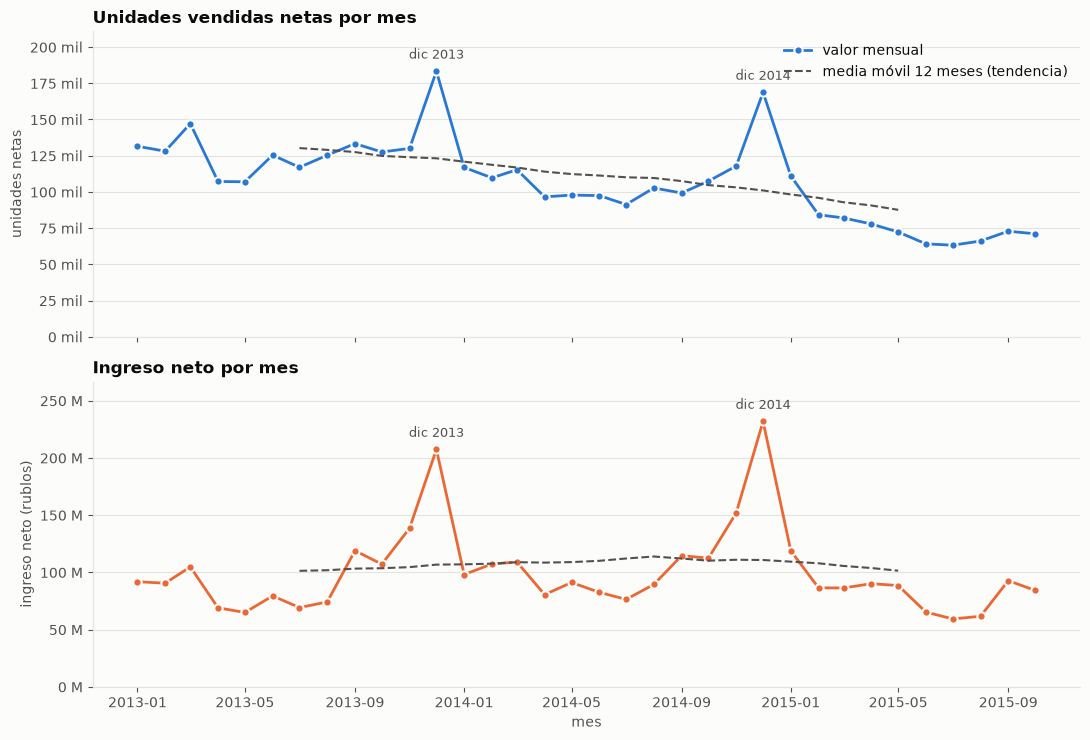

In [52]:
mm12 = serie[["unidades", "ingreso"]].rolling(12, center=True).mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
paneles = [
    (axes[0], "unidades", "Unidades vendidas netas por mes", fmt_miles),
    (axes[1], "ingreso", "Ingreso neto por mes", fmt_millones),
]
for ax, col, titulo, fmt in paneles:
    ax.plot(serie.index, serie[col], color=COLOR[col], marker="o", markersize=6,
            markeredgecolor=FONDO, markeredgewidth=1.5, label="valor mensual")
    ax.plot(mm12.index, mm12[col], color=TINTA_2, linestyle="--", linewidth=1.5,
            label="media móvil 12 meses (tendencia)")
    ax.set_title(titulo)
    ax.set_ylabel("unidades netas" if col == "unidades" else "ingreso neto (rublos)")
    ax.yaxis.set_major_formatter(fmt)
    ax.set_ylim(0, serie[col].max() * 1.15)
    for fecha in serie.index[serie.index.month == 12]:
        ax.annotate(f"dic {fecha.year}", (fecha, serie.loc[fecha, col]), xytext=(0, 9),
                    textcoords="offset points", ha="center", fontsize=9, color=TINTA_2)
axes[1].set_xlabel("mes")
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

**Interpretación:**
- Las **unidades** muestran una tendencia descendente clara: la media móvil pasa de unas 130,000 unidades al mes a mediados de 2013 a menos de 90,000 a mediados de 2015.
- El **ingreso** se mantiene más estable hasta finales de 2014 y empieza a caer en 2015.
- Diciembre destaca cada año como el pico de ambas series; las demás subidas del ingreso se analizan en 6.5.

### 6.3 Tendencias generales

Para comparar series de distinta escala, se expresan como **índice (promedio de 2013 = 100)** y se suavizan con la media móvil de 12 meses. Se añade el **precio medio por unidad** (ingreso / unidades).

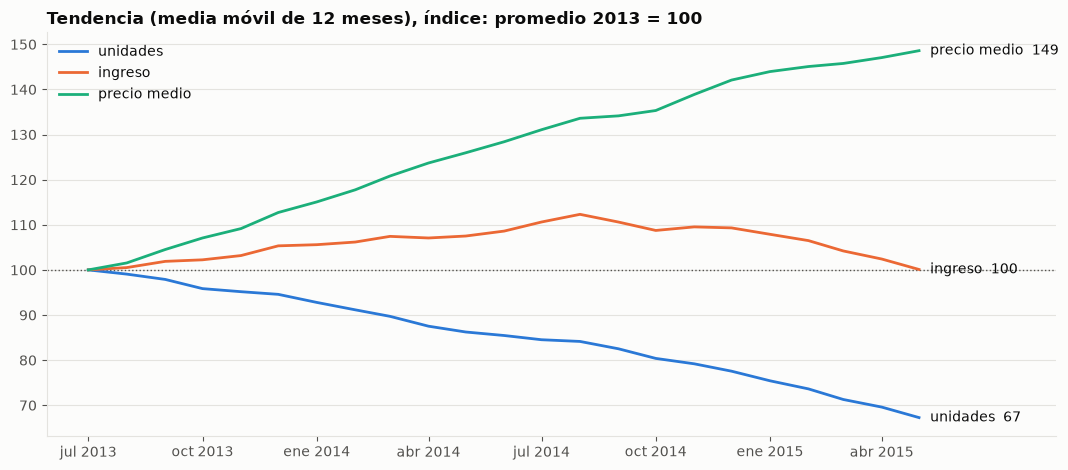

In [53]:
variables = ["unidades", "ingreso", "precio medio"]
indice = serie[variables] / serie[variables].iloc[:12].mean() * 100
indice_tendencia = indice.rolling(12, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.axhline(100, color=TINTA_2, linewidth=1, linestyle=":")
for col in variables:
    s = indice_tendencia[col].dropna()
    ax.plot(s.index, s, color=COLOR[col], label=col)
    ax.annotate(f"{col}  {s.iloc[-1]:.0f}", (s.index[-1], s.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=10, color=TINTA)
ax.set_title("Tendencia (media móvil de 12 meses), índice: promedio 2013 = 100")
ticks = pd.date_range("2013-07-01", "2015-04-01", freq="3MS")
ax.set_xticks(ticks, [f"{MESES[t.month - 1]} {t.year}" for t in ticks])
ax.set_xlim(right=indice_tendencia.dropna().index[-1] + pd.Timedelta(days=110))
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

In [54]:
x = np.arange(len(serie))
resumen_tendencia = pd.DataFrame(
    {
        col: {
            "pendiente lineal por mes": np.polyfit(x, serie[col], 1)[0],
            "pendiente como % del promedio": np.polyfit(x, serie[col], 1)[0] / serie[col].mean(),
        }
        for col in ["unidades", "ingreso"]
    }
).T
resumen_tendencia.style.format({"pendiente lineal por mes": "{:,.0f}", "pendiente como % del promedio": "{:+.2%}"})

,pendiente lineal por mes,pendiente como % del promedio
unidades,"-1,944",-1.81%
ingreso,"-80,082",-0.08%


In [55]:
# Variación interanual: cada mes frente al mismo mes del año anterior
interanual = serie[["unidades", "ingreso"]].pct_change(12).dropna()
interanual["año"] = interanual.index.year
interanual["mes"] = [MESES[m - 1] for m in interanual.index.month]
tabla_interanual = interanual.pivot(index="mes", columns="año", values=["unidades", "ingreso"]).reindex(MESES)
tabla_interanual.columns = [f"{var} {anio} vs {anio - 1}" for var, anio in tabla_interanual.columns]
tabla_interanual.style.format("{:+.1%}", na_rep="—")

,unidades 2014 vs 2013,unidades 2015 vs 2014,ingreso 2014 vs 2013,ingreso 2015 vs 2014
mes,,,,
ene,-11.1%,-5.1%,+6.8%,+21.1%
feb,-14.4%,-23.2%,+18.5%,-19.4%
mar,-21.6%,-28.9%,+4.0%,-20.7%
abr,-9.9%,-19.4%,+16.6%,+11.9%
may,-8.6%,-26.1%,+40.3%,-3.0%
jun,-22.3%,-34.2%,+3.9%,-20.9%
jul,-22.0%,-30.8%,+10.3%,-22.3%
ago,-18.0%,-35.7%,+20.6%,-31.1%
sep,-25.6%,-26.6%,-3.7%,-19.0%


**Interpretación:**
- **Unidades a la baja:** la pendiente lineal es de unas −1,900 unidades por mes (≈ −1.8% del promedio mensual). Todos los meses de 2014 y 2015 venden menos que el mismo mes del año anterior, y la caída se **acelera en 2015** en 2014 las caídas interanuales van de −8% a −26%, y en 2015, salvo enero (−5%), van de −19% a −36%.
- **Precio medio al alza:** el precio medio por unidad sube de forma sostenida (cerca de un 50% sobre 2013 en la tendencia, mientras las unidades quedan un tercio por debajo), en línea con el mayor peso de consolas y juegos de nueva generación (sección 5.5).
- **Ingreso:** el aumento del precio compensa la caída de unidades durante 2014 (ingreso interanual mayormente positivo), pero no en 2015, cuando el ingreso también cae.
- Para predecir unidades, la tendencia descendente debe tenerse en cuenta: el nivel de 2013 ya no es representativo del mes a predecir.

### 6.4 Estacionalidad

#### 6.4.1 Por mes del año

Se comparan los tres años en el mismo eje de meses. Además, se calcula un **índice estacional**: las unidades de cada mes divididas por su media móvil de 12 meses (que elimina la tendencia), promediadas por mes del año. Un valor de 1.20 significa que ese mes vende un 20% más de lo que indica la tendencia.

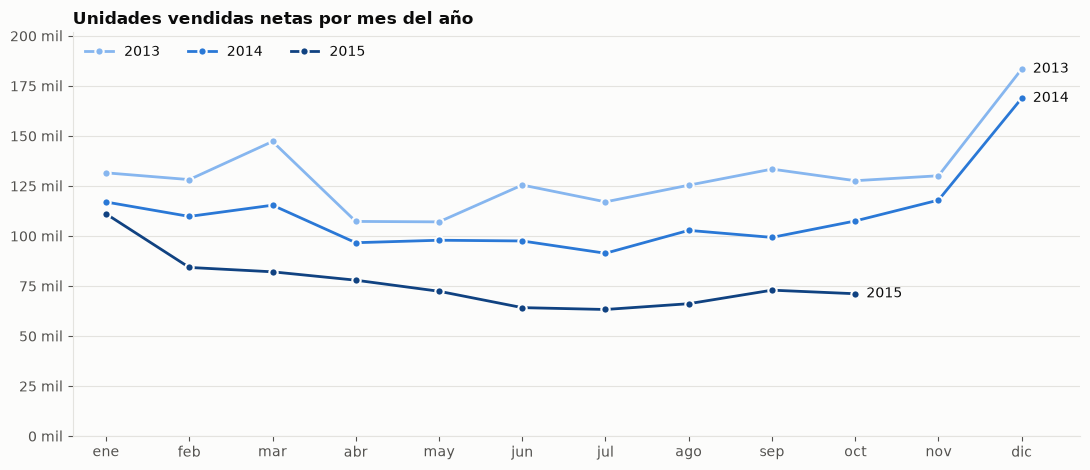

In [56]:
por_mes_anio = serie.assign(anio=serie.index.year, num_mes=serie.index.month)

fig, ax = plt.subplots(figsize=(11, 4.8))
for anio, grupo in por_mes_anio.groupby("anio"):
    ax.plot(grupo["num_mes"], grupo["unidades"], color=COLOR_ANIO[anio], marker="o", markersize=6,
            markeredgecolor=FONDO, markeredgewidth=1.5, label=str(anio))
    ultimo = grupo.iloc[-1]
    ax.annotate(str(anio), (ultimo["num_mes"], ultimo["unidades"]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=10, color=TINTA)
ax.set_xticks(range(1, 13), MESES)
ax.set_xlim(0.6, 12.7)
ax.yaxis.set_major_formatter(fmt_miles)
ax.set_ylim(0, por_mes_anio["unidades"].max() * 1.1)
ax.set_title("Unidades vendidas netas por mes del año")
ax.legend(loc="upper left", ncols=3)
fig.tight_layout()
plt.show()

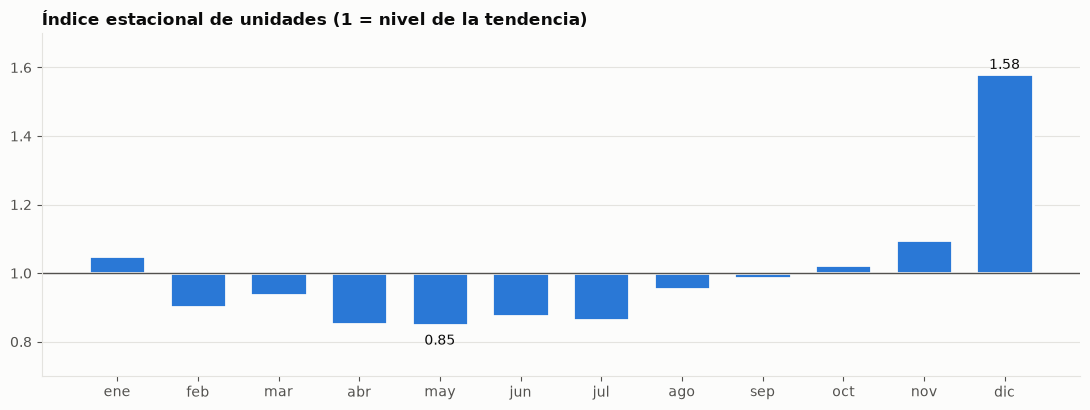

,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
índice estacional,1.05,0.90,0.94,0.85,0.85,0.88,0.86,0.95,0.98,1.02,1.10,1.58
observaciones,2,2,2,2,2,1,2,2,2,2,2,2


In [57]:
ratio_estacional = (serie["unidades"] / mm12["unidades"]).dropna()
indice_estacional = ratio_estacional.groupby(ratio_estacional.index.month).agg(["mean", "count"])
indice_estacional.index = MESES
indice_estacional.columns = ["índice estacional", "observaciones"]

fig, ax = plt.subplots(figsize=(11, 4.2))
barras = ax.bar(MESES, indice_estacional["índice estacional"] - 1, bottom=1,
                color=COLOR["unidades"], width=0.7, edgecolor=FONDO, linewidth=2)
ax.axhline(1, color=TINTA_2, linewidth=1)
for mes in [indice_estacional["índice estacional"].idxmax(), indice_estacional["índice estacional"].idxmin()]:
    valor = indice_estacional.loc[mes, "índice estacional"]
    ax.annotate(f"{valor:.2f}", (MESES.index(mes), valor), xytext=(0, 4 if valor > 1 else -14),
                textcoords="offset points", ha="center", fontsize=10, color=TINTA)
ax.set_ylim(0.7, indice_estacional["índice estacional"].max() + 0.12)
ax.set_title("Índice estacional de unidades (1 = nivel de la tendencia)")
fig.tight_layout()
plt.show()

(
    indice_estacional.T.style
    .format("{:.2f}", subset=pd.IndexSlice[["índice estacional"], :])
    .format("{:.0f}", subset=pd.IndexSlice[["observaciones"], :])
)

**Interpretación:**
- **Diciembre** es, con diferencia, el mes más fuerte: vende cerca de un **58% más** de lo que marca la tendencia, por las compras de regalos de Año Nuevo (la principal fecha de regalos en Rusia).
- **Enero, octubre y noviembre** también están por encima de la tendencia; noviembre (~+10%) anticipa el pico de diciembre.
- **De abril a julio** se encuentra la temporada baja (alrededor de un 12–15% por debajo de la tendencia).
- El patrón es similar en los tres años, aunque cada año a un nivel más bajo. El índice se basa en 1 o 2 observaciones por mes (los extremos de la serie no tienen media móvil centrada), así que debe leerse como orientativo.
- **Noviembre**, el mes a predecir, es estacionalmente alto: se espera un repunte respecto a octubre.

#### 6.4.2 Por día de la semana

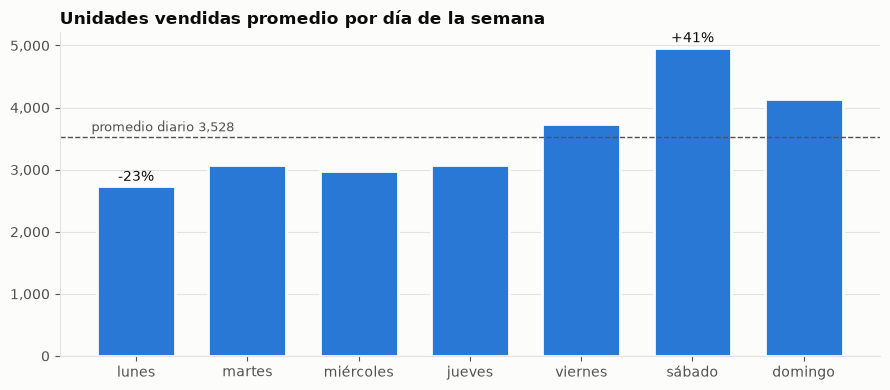

In [58]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(por_dia_semana.index, por_dia_semana["unidades_promedio"], color=COLOR["unidades"],
       width=0.7, edgecolor=FONDO, linewidth=2)
promedio_diario = por_dia["unidades"].mean()
ax.axhline(promedio_diario, color=TINTA_2, linewidth=1, linestyle="--")
ax.annotate(f"promedio diario {promedio_diario:,.0f}", (-0.4, promedio_diario), xytext=(0, 4),
            textcoords="offset points", ha="left", fontsize=9, color=TINTA_2)
for dia in ["lunes", "sábado"]:
    fila = por_dia_semana.loc[dia]
    ax.annotate(f"{fila['vs. promedio']:+.0%}", (list(por_dia_semana.index).index(dia), fila["unidades_promedio"]),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10, color=TINTA)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_title("Unidades vendidas promedio por día de la semana")
fig.tight_layout()
plt.show()

In [59]:
# Estabilidad del patrón semanal: desviación de cada día respecto al promedio de su año
dia_anio = por_dia.assign(anio=por_dia.index.year, dia=por_dia.index.dayofweek)
patron = dia_anio.groupby(["anio", "dia"])["unidades"].mean().unstack("anio")
patron = patron / dia_anio.groupby("anio")["unidades"].mean() - 1
patron.index = DIAS
patron.style.format("{:+.1%}")

anio,2013,2014,2015
lunes,-24.0%,-23.4%,-18.5%
martes,-16.5%,-13.6%,-4.8%
miércoles,-17.4%,-16.1%,-12.3%
jueves,-13.4%,-10.7%,-15.3%
viernes,+7.5%,+5.2%,+4.9%
sábado,+43.9%,+42.1%,+32.7%
domingo,+20.2%,+16.8%,+12.7%


**Interpretación:**
- El **fin de semana** concentra las ventas: el **sábado** vende cerca de un 40% más que el promedio y el domingo un 17% más, mientras que **de lunes a jueves** las ventas están por debajo del promedio (el lunes es el día más bajo, ~−23%).
- El patrón es **estable en los tres años**, por lo que es una característica estructural del negocio (tiendas físicas en centros comerciales).
- Al agregar por mes, este efecto se compensa casi por completo, aunque un mes con más sábados puede vender ligeramente más.

### 6.5 Picos y caídas abruptas

#### 6.5.1 A nivel mensual

Se listan los meses con una variación respecto al mes anterior de al menos ±20% en unidades o ±40% en ingreso, junto con el producto que más ingreso generó ese mes.

In [60]:
variacion = serie[["mes", "unidades", "ingreso"]].copy()
variacion["var. unidades"] = variacion["unidades"].pct_change()
variacion["var. ingreso"] = variacion["ingreso"].pct_change()

ingreso_producto_mes = ventas.groupby(["date_block_num", "item_id"])["revenue"].sum().reset_index()
lider = ingreso_producto_mes.loc[ingreso_producto_mes.groupby("date_block_num")["revenue"].idxmax()]
lider = lider.merge(items[["item_id", "item_name"]], on="item_id").set_index("date_block_num")
variacion["producto con más ingreso"] = lider.loc[serie["date_block_num"], "item_name"].str[:60].values
variacion["% ingreso del producto"] = (lider.loc[serie["date_block_num"], "revenue"].values / variacion["ingreso"]).values

cambios_bruscos = variacion[(variacion["var. unidades"].abs() >= 0.20) | (variacion["var. ingreso"].abs() >= 0.40)]
cambios_bruscos.style.format({
    "unidades": "{:,.0f}", "ingreso": "{:,.0f}", "var. unidades": "{:+.1%}",
    "var. ingreso": "{:+.1%}", "% ingreso del producto": "{:.1%}",
}).format_index("{:%Y-%m}")

,mes,unidades,ingreso,var. unidades,var. ingreso,producto con más ingreso,% ingreso del producto
fecha,,,,,,,
2013-04,2013-04,"107,190","69,154,286",-27.2%,-34.1%,"Injustice: Gods Among Us. Soviet Edition [PS3, русские субти",2.2%
2013-09,2013-09,"133,332","119,081,892",+6.4%,+60.3%,"Grand Theft Auto V [PS3, русские субтитры]",14.9%
2013-12,2013-12,"183,342","207,571,731",+41.0%,+49.7%,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),22.4%
2014-01,2014-01,"116,899","98,226,023",-36.2%,-52.7%,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),7.4%
2014-12,2014-12,"168,755","232,025,171",+43.2%,+52.6%,Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B01) + игра Gran,10.4%
2015-01,2015-01,"110,971","118,927,700",-34.2%,-48.7%,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),5.3%
2015-02,2015-02,"84,198","86,593,884",-24.1%,-27.2%,"Орден 1886 [PS4, русская версия]",5.9%
2015-09,2015-09,"72,843","92,905,169",+10.2%,+50.5%,"FIFA 16 [PS4, русская версия]",6.3%


**Interpretación (explicaciones según los datos):**
- **Diciembre (2013 y 2014), +41% y +43% en unidades:** pico estacional de Año Nuevo. En diciembre de 2013 el producto con más ingreso es la **PlayStation 4**, y en diciembre de 2014, un **pack de PS4 con GTA V**.
- **Enero (2014 y 2015), −36% y −34%:** vuelta a la normalidad tras el pico de diciembre; no es una anomalía, sino la otra cara de la estacionalidad.
- **Septiembre de 2013, +60% en ingreso con solo +6% en unidades:** lanzamiento de **Grand Theft Auto V** para PS3 y Xbox 360, un producto caro que eleva el precio medio del mes.
- **Noviembre de 2013, +29% en ingreso** (por debajo del umbral de la tabla, pero relevante): lanzamiento de la **PlayStation 4** (el 29/11/2013, ver 6.5.2), una consola de alto precio.
- **Septiembre de 2015, +50% en ingreso:** lanzamientos de otoño de juegos de PS4 (por ejemplo FIFA 16).
- **Abril de 2013 (−27%) y febrero de 2015 (−24%):** la de abril sigue a un marzo de 2013 muy alto (lanzamientos como StarCraft II y el festivo del 8 de marzo). La de febrero de 2015 marca el inicio de un año con caídas interanuales de más del 20% en casi todos los meses; los datos no incluyen la causa, que podría ser externa (por ejemplo, el contexto económico).

#### 6.5.2 A nivel diario

Para detectar días atípicos se compara cada día con la **mediana móvil centrada de 29 días** (una referencia robusta del nivel normal de ese momento). Se marca como **pico** un día con al menos el doble de esa referencia, y como **caída** uno con menos del 60%. Para cada uno se indica el producto y la tienda que más unidades vendieron ese día. Para el producto se excluye la bolsa de marca (`item_id` 20949), que acompaña a casi cualquier compra y no explica los picos.

In [61]:
diario = por_dia.copy()
diario["referencia"] = diario["unidades"].rolling(29, center=True, min_periods=10).median()
diario["ratio"] = diario["unidades"] / diario["referencia"]
diario["tiendas activas"] = ventas.groupby("date")["shop_id"].nunique()

BOLSA = 20949  # bolsa de marca: acompaña a casi cualquier compra (sección 5.4)

def principal(dia, columna):
    """Elemento con más unidades vendidas en un día (sin contar la bolsa de marca)."""
    dia_ventas = ventas[(ventas["date"] == dia) & (ventas["item_id"] != BOLSA)]
    return dia_ventas.groupby(columna)["item_cnt_day"].sum().idxmax()

nombre_item = items.set_index("item_id")["item_name"]
nombre_tienda = shops.set_index("shop_id")["shop_name"]

eventos = diario[(diario["ratio"] >= 2) | (diario["ratio"] < 0.6)].copy()
eventos["tipo"] = np.where(eventos["ratio"] >= 2, "pico", "caída")
eventos["día"] = [DIAS[d] for d in eventos.index.dayofweek]
eventos["producto principal"] = [nombre_item[principal(d, "item_id")][:55] for d in eventos.index]
eventos["tienda principal"] = [f"{s} · {nombre_tienda[s]}" for s in (principal(d, "shop_id") for d in eventos.index)]
eventos = eventos.sort_values(["tipo", "ratio"], ascending=[False, False])
print(f"Picos: {(eventos['tipo'] == 'pico').sum()} | Caídas: {(eventos['tipo'] == 'caída').sum()}")
eventos[["tipo", "día", "unidades", "referencia", "ratio", "tiendas activas", "producto principal", "tienda principal"]].style.format(
    {"unidades": "{:,.0f}", "referencia": "{:,.0f}", "ratio": "{:.2f}"}
).format_index("{:%d/%m/%Y}")

Picos: 21 | Caídas: 12


,tipo,día,unidades,referencia,ratio,tiendas activas,producto principal,tienda principal
date,,,,,,,,
19/05/2015,pico,martes,"8,483","1,997",4.25,44,"Ведьмак 3: Дикая охота [PC, русская версия]",12 · Интернет-магазин ЧС
14/04/2015,pico,martes,"7,158","2,299",3.11,44,"Grand Theft Auto V [PC, русские субтитры]",12 · Интернет-магазин ЧС
27/05/2014,pico,martes,"8,256","3,010",2.74,49,"Watch_Dogs. Специальное издание [PS4, русская версия]",12 · Интернет-магазин ЧС
30/12/2014,pico,martes,"13,236","5,070",2.61,50,Прием денежных средств для 1С-Онлайн,"25 · Москва ТРК ""Атриум"""
22/02/2014,pico,sábado,"8,472","3,263",2.60,46,"Battlefield 4 [PC, русская версия]","31 · Москва ТЦ ""Семеновский"""
04/10/2014,pico,sábado,"8,767","3,583",2.45,51,"Средиземье: Тени Мордора [PC, Цифровая версия]",9 · Выездная Торговля
30/12/2013,pico,lunes,"12,823","5,301",2.42,46,"Battlefield 4 [PC, русская версия]","31 · Москва ТЦ ""Семеновский"""
29/12/2013,pico,domingo,"12,863","5,368",2.40,45,"Battlefield 4 [PC, русская версия]","31 · Москва ТЦ ""Семеновский"""
28/12/2013,pico,sábado,"13,343","5,806",2.30,45,"Battlefield 4 [PC, русская версия]","31 · Москва ТЦ ""Семеновский"""


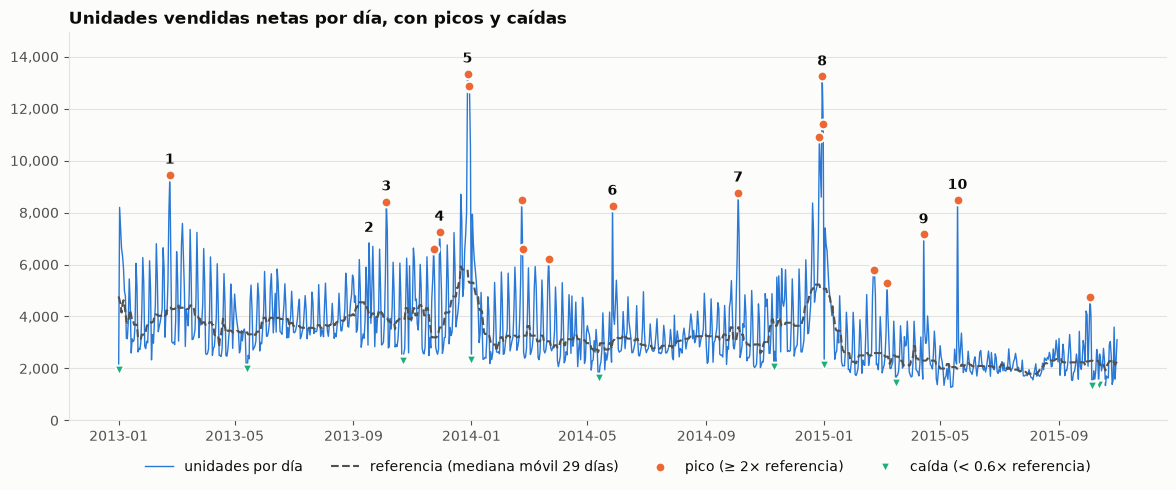

,fecha,unidades,ratio vs. referencia,producto principal,explicación
n.º,,,,,
1,23/02/2013,"9,456",2.18,"Crysis 3 [PC, русская версия]","23 de febrero (Día del Defensor de la Patria, festivo de regalos)"
2,17/09/2013,"6,832",1.66,"Grand Theft Auto V [PS3, русские субтитры]",Lanzamiento de GTA V para PS3 y Xbox 360
3,05/10/2013,"8,425",2.15,"Grand Theft Auto V [PS3, русские субтитры]",Feria de octubre: tienda 9 «Выездная Торговля» (venta itinerante)
4,29/11/2013,"7,262",2.03,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),Lanzamiento de PlayStation 4
5,28/12/2013,"13,343",2.30,"Battlefield 4 [PC, русская версия]",Compras de Año Nuevo
6,27/05/2014,"8,256",2.74,"Watch_Dogs. Специальное издание [PS4, русская версия]",Lanzamiento de Watch Dogs
7,04/10/2014,"8,767",2.45,"Средиземье: Тени Мордора [PC, Цифровая версия]","Feria de octubre: tiendas 9 y 20 («Распродажа», liquidación)"
8,30/12/2014,"13,236",2.61,Прием денежных средств для 1С-Онлайн,Compras de Año Nuevo
9,14/04/2015,"7,158",3.11,"Grand Theft Auto V [PC, русские субтитры]",Lanzamiento de GTA V para PC


In [62]:
# Eventos destacados en la gráfica, numerados; su explicación está en la tabla siguiente
DESTACADOS = [
    ("2013-02-23", "23 de febrero (Día del Defensor de la Patria, festivo de regalos)"),
    ("2013-09-17", "Lanzamiento de GTA V para PS3 y Xbox 360"),
    ("2013-10-05", "Feria de octubre: tienda 9 «Выездная Торговля» (venta itinerante)"),
    ("2013-11-29", "Lanzamiento de PlayStation 4"),
    ("2013-12-28", "Compras de Año Nuevo"),
    ("2014-05-27", "Lanzamiento de Watch Dogs"),
    ("2014-10-04", "Feria de octubre: tiendas 9 y 20 («Распродажа», liquidación)"),
    ("2014-12-30", "Compras de Año Nuevo"),
    ("2015-04-14", "Lanzamiento de GTA V para PC"),
    ("2015-05-19", "Lanzamiento de The Witcher 3"),
]
fechas_destacadas = pd.to_datetime([f for f, _ in DESTACADOS])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(diario.index, diario["unidades"], color=COLOR["unidades"], linewidth=1, label="unidades por día")
ax.plot(diario.index, diario["referencia"], color=TINTA_2, linewidth=1.5, linestyle="--",
        label="referencia (mediana móvil 29 días)")
picos = eventos[eventos["tipo"] == "pico"]
caidas = eventos[eventos["tipo"] == "caída"]
ax.scatter(picos.index, picos["unidades"], s=50, color=COLOR["ingreso"], edgecolor=FONDO,
           linewidth=1.5, zorder=3, label="pico (≥ 2× referencia)")
ax.scatter(caidas.index, caidas["unidades"], s=50, marker="v", color=COLOR["precio medio"],
           edgecolor=FONDO, linewidth=1.5, zorder=3, label="caída (< 0.6× referencia)")
for numero, fecha in enumerate(fechas_destacadas, start=1):
    ax.annotate(str(numero), (fecha, diario.loc[fecha, "unidades"]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=10, fontweight="bold", color=TINTA)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_ylim(0, diario["unidades"].max() * 1.12)
ax.set_title("Unidades vendidas netas por día, con picos y caídas")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncols=4)
fig.tight_layout()
plt.show()

pd.DataFrame(
    {
        "fecha": fechas_destacadas.strftime("%d/%m/%Y"),
        "unidades": diario.loc[fechas_destacadas, "unidades"].values,
        "ratio vs. referencia": diario.loc[fechas_destacadas, "ratio"].values,
        "producto principal": [nombre_item[principal(f, "item_id")][:55] for f in fechas_destacadas],
        "explicación": [texto for _, texto in DESTACADOS],
    },
    index=pd.RangeIndex(1, len(DESTACADOS) + 1, name="n.º"),
).style.format({"unidades": "{:,.0f}", "ratio vs. referencia": "{:.2f}"})

**Interpretación (explicaciones según los datos):**
- **Lanzamientos de videojuegos y consolas:** son los picos más pronunciados. El día de lanzamiento, un solo título vende miles de unidades (por ejemplo, The Witcher 3 el 19/05/2015, a más de 4 veces el nivel normal, o GTA V para PC el 14/04/2015). Coinciden con un fuerte peso de la tienda 12 (`Интернет-магазин ЧС`, tienda online), que entrega los pedidos anticipados.
- **Festivos rusos:** el **23 de febrero** y el **8 de marzo** y sus vísperas (días de regalos) y los **últimos días de diciembre** (Año Nuevo) superan claramente el nivel normal, impulsados por categorías de regalo (DVD, juegos, música).
- **Ferias de octubre:** a inicios de octubre aparecen las tiendas 9 (`Выездная Торговля`, venta itinerante) y 20 (`Москва "Распродажа"`, liquidación), que solo venden esos días y aportan miles de unidades. Son eventos puntuales, no ventas regulares.
- **Caídas:** la más clara es el **1 de enero** de cada año, con menos de la mitad de las tiendas abiertas (festivo). Las demás caídas son lunes o martes con todas las tiendas activas, o los días posteriores al cierre de la feria de octubre de 2015, cuando la referencia todavía incluye esos días altos; **no hay evidencia de cierres ni de datos faltantes**.
- **Implicación:** los picos diarios se diluyen en el total mensual, pero los lanzamientos de productos y las tiendas temporales (9 y 20) generan meses atípicos para productos y tiendas concretos, y deben considerarse al construir variables para el modelo.

### 6.6 Resumen de la sección

| Aspecto | Hallazgo |
|---|---|
| Tendencia | Unidades en descenso sostenido (≈ −1.8% del promedio por mes), con aceleración en 2015; el ingreso se sostiene hasta 2014 gracias a un precio medio creciente. |
| Estacionalidad anual | Diciembre ≈ +58% sobre la tendencia; temporada baja de abril a julio; noviembre por encima de la tendencia. |
| Estacionalidad semanal | Sábado ≈ +40% y lunes ≈ −23% frente al promedio; patrón estable en los tres años. |
| Picos | Lanzamientos (GTA V, PS4, Watch Dogs, The Witcher 3), festivos (23 de febrero, 8 de marzo, Año Nuevo) y ferias de octubre (tiendas 9 y 20). |
| Caídas | 1 de enero (tiendas cerradas) y los descensos de enero tras el pico de diciembre. |

## 7. Análisis comparativo entre sucursales y productos

Objetivo de esta sección: comparar el desempeño de productos, categorías y sucursales, detectar valores extremos de precio y cantidad con un método estadístico adecuado e investigar los casos más relevantes para distinguir **errores** de **comportamientos comerciales legítimos**.

Se reutilizan `ventas` y las tablas `por_producto`, `por_categoria` y `por_tienda` (sección 5), así como el estilo de gráficas de la sección 6. **No se elimina ningún registro**: los valores extremos solo se marcan con máscaras.

### 7.1 Productos más y menos vendidos

In [63]:
formato_pi = {"unidades": "{:,.0f}", "ingreso": "{:,.0f}"}
producto_info = items.set_index("item_id")[["item_name"]].join(
    items.set_index("item_id")["item_category_id"].map(item_categories.set_index("item_category_id")["item_category_name"]).rename("categoría")
)
producto_info["item_name"] = producto_info["item_name"].str[:55]

def tabla_productos(orden, columna, ascendente):
    datos = por_producto.sort_values(columna, ascending=ascendente).head(10).join(producto_info)
    return datos[["item_name", "categoría", "unidades", "ingreso"]].style.format(formato_pi).set_caption(orden)

display(tabla_productos("Top 10 por unidades", "unidades", False))
display(tabla_productos("Top 10 por ingreso neto", "ingreso", False))

,item_name,categoría,unidades,ingreso
item_id,,,,
20949,Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,642","928,864"
2808,"Diablo III [PC, Jewel, русская версия]",Игры PC - Стандартные издания,"17,245","16,852,778"
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,"16,642","43,617,975"
17717,Прием денежных средств для 1С-Онлайн,Служебные,"15,830","17,200,826"
5822,Playstation Store пополнение бумажника: Карта оплаты 10,Карты оплаты - PSN,"14,515","15,408,983"
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,"11,688","31,065,160"
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),Игровые консоли - PS4,"10,289","219,391,489"
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"10,099","19,983,483"
1855,"Battlefield 4 [PC, русская версия]",Игры PC - Стандартные издания,"10,032","9,357,025"


,item_name,categoría,unidades,ingreso
item_id,,,,
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1108A/B01),Игровые консоли - PS4,"10,289","219,391,489"
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,"16,642","43,617,975"
13443,Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B01) + игра,Игровые консоли - PS4,"1,366","34,331,245"
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,"11,688","31,065,160"
3733,"Grand Theft Auto V [PS4, русские субтитры]",Игры - PS4,"6,506","22,298,864"
16787,"Одни из нас [PS3, русская версия]",Игры - PS3,"9,227","21,907,839"
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"10,099","19,983,483"
13405,"Комплект ""Microsoft Xbox One 500GB (Day One Edition Gre",Игровые консоли - XBOX ONE,991,"18,125,480"
17717,Прием денежных средств для 1С-Онлайн,Служебные,"15,830","17,200,826"


In [64]:
display(tabla_productos("10 menos vendidos por unidades", "unidades", True))
display(tabla_productos("10 con menor ingreso neto", "ingreso", True))

print(f"Productos del catálogo sin ninguna venta registrada: {len(items) - len(por_producto):,}")
print(f"Productos con ventas netas <= 0:                    {(por_producto['unidades'] <= 0).sum():,}")
print(f"Productos con exactamente 1 unidad neta:            {(por_producto['unidades'] == 1).sum():,}")

,item_name,categoría,unidades,ingreso
item_id,,,,
1590,"Assassin’s Creed 3. Freedom Edition [PC, русская версия",Игры PC - Коллекционные издания,-11,"-28,589"
18062,Робопет Собака,"Подарки - Гаджеты, роботы, спорт",-1,"-4,999"
13474,Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игра «FIFA 1,Игровые консоли - PS3,-1,"-10,398"
11871,Змея,"Подарки - Гаджеты, роботы, спорт",-1,"-5,999"
8515,Английский язык. 2 - 5 класс (Jewel),Программы - Обучающие,0,15
7547,VideoStudio Pro X6 IE Windows Mini-Box,Программы - Для дома и офиса,0,0
4591,"MCCARTNEY, PAUL In Red Square (Фирм.)",Музыка - Музыкальное видео,0,0
13477,Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + игра «Чарод,Игровые консоли - PS3,0,"-7,592"
19,/ЗОЛОТАЯ КОЛЛЕКЦИЯ м/ф-72,Кино - DVD,1,28


,item_name,categoría,unidades,ingreso
item_id,,,,
1590,"Assassin’s Creed 3. Freedom Edition [PC, русская версия",Игры PC - Коллекционные издания,-11,"-28,589"
13474,Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игра «FIFA 1,Игровые консоли - PS3,-1,"-10,398"
13477,Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + игра «Чарод,Игровые консоли - PS3,0,"-7,592"
11871,Змея,"Подарки - Гаджеты, роботы, спорт",-1,"-5,999"
18062,Робопет Собака,"Подарки - Гаджеты, роботы, спорт",-1,"-4,999"
7547,VideoStudio Pro X6 IE Windows Mini-Box,Программы - Для дома и офиса,0,0
4591,"MCCARTNEY, PAUL In Red Square (Фирм.)",Музыка - Музыкальное видео,0,0
22098,Элемент питания КОСМОС LR03 2*BL,Элементы питания,1,7
22010,"Щелкунчик и Крысиный король [PC, Jewel]",Игры PC - Стандартные издания,1,14


Productos del catálogo sin ninguna venta registrada: 363
Productos con ventas netas <= 0:                    8
Productos con exactamente 1 unidad neta:            2,319


**Interpretación:**
- El **top por unidades** mezcla productos de naturaleza distinta: la bolsa de marca (20949), servicios como `Прием денежных средств для 1С-Онлайн` (cobros de la tienda online) y tarjetas de pago de PlayStation Store, junto con videojuegos superventas (Diablo III, GTA V, Battlefield 4).
- El **top por ingreso** está dominado por consolas (PS4, Xbox One) y por GTA V en todas sus plataformas.
- Los **menos vendidos** tienen ventas netas negativas o nulas: son productos en los que las devoluciones superan o igualan las ventas del periodo (posiblemente, devoluciones de ventas hechas antes de 2013). Además hay miles de productos con una sola unidad vendida: la cola larga del catálogo es muy amplia, por lo que el "último lugar" está repartido entre muchos empates.

### 7.2 Categorías más y menos vendidas

In [65]:
def tabla_categorias(titulo, columna, ascendente):
    return (por_categoria.sort_values(columna, ascending=ascendente).head(10)
            .style.format(formato_cat).set_caption(titulo))

display(tabla_categorias("Top 10 categorías por unidades", "unidades", False))
display(tabla_categorias("Top 10 categorías por ingreso neto", "ingreso", False))

,,unidades,ingreso,% unidades,% ingreso
item_category_id,item_category_name,,,,
40,Кино - DVD,"634,171","169,944,222",17.4%,5.0%
30,Игры PC - Стандартные издания,"456,540","257,519,291",12.5%,7.6%
55,Музыка - CD локального производства,"348,591","100,022,564",9.6%,2.9%
19,Игры - PS3,"254,887","412,052,156",7.0%,12.1%
37,Кино - Blu-Ray,"203,284","90,478,732",5.6%,2.7%
71,"Подарки - Сумки, Альбомы, Коврики д/мыши","187,998","934,207",5.2%,0.0%
28,Игры PC - Дополнительные издания,"174,954","136,419,149",4.8%,4.0%
23,Игры - XBOX 360,"169,944","259,619,128",4.7%,7.6%
20,Игры - PS4,"127,319","373,010,312",3.5%,11.0%


,,unidades,ingreso,% unidades,% ingreso
item_category_id,item_category_name,,,,
19,Игры - PS3,"254,887","412,052,156",7.0%,12.1%
20,Игры - PS4,"127,319","373,010,312",3.5%,11.0%
12,Игровые консоли - PS4,"13,230","292,239,762",0.4%,8.6%
23,Игры - XBOX 360,"169,944","259,619,128",4.7%,7.6%
30,Игры PC - Стандартные издания,"456,540","257,519,291",12.5%,7.6%
40,Кино - DVD,"634,171","169,944,222",17.4%,5.0%
28,Игры PC - Дополнительные издания,"174,954","136,419,149",4.8%,4.0%
55,Музыка - CD локального производства,"348,591","100,022,564",9.6%,2.9%
37,Кино - Blu-Ray,"203,284","90,478,732",5.6%,2.7%


In [66]:
display(tabla_categorias("10 categorías con menos unidades", "unidades", True))
display(tabla_categorias("10 categorías con menor ingreso neto", "ingreso", True))

,,unidades,ingreso,% unidades,% ingreso
item_category_id,item_category_name,,,,
10,Игровые консоли - PS2,1,"1,998",0.0%,0.0%
51,Книги - Познавательная литература,1,129,0.0%,0.0%
1,Аксессуары - PS2,2,431,0.0%,0.0%
0,PC - Гарнитуры/Наушники,3,263,0.0%,0.0%
53,Книги - Художественная литература,3,847,0.0%,0.0%
50,Книги - Открытки,3,58,0.0%,0.0%
52,Книги - Путеводители,3,300,0.0%,0.0%
48,Книги - Компьютерная литература,6,"1,654",0.0%,0.0%
27,Игры MAC - Цифра,8,"5,422",0.0%,0.0%


,,unidades,ingreso,% unidades,% ingreso
item_category_id,item_category_name,,,,
50,Книги - Открытки,3,58,0.0%,0.0%
51,Книги - Познавательная литература,1,129,0.0%,0.0%
0,PC - Гарнитуры/Наушники,3,263,0.0%,0.0%
52,Книги - Путеводители,3,300,0.0%,0.0%
1,Аксессуары - PS2,2,431,0.0%,0.0%
53,Книги - Художественная литература,3,847,0.0%,0.0%
48,Книги - Компьютерная литература,6,"1,654",0.0%,0.0%
10,Игровые консоли - PS2,1,"1,998",0.0%,0.0%
18,Игры - PS2,11,"3,828",0.0%,0.0%


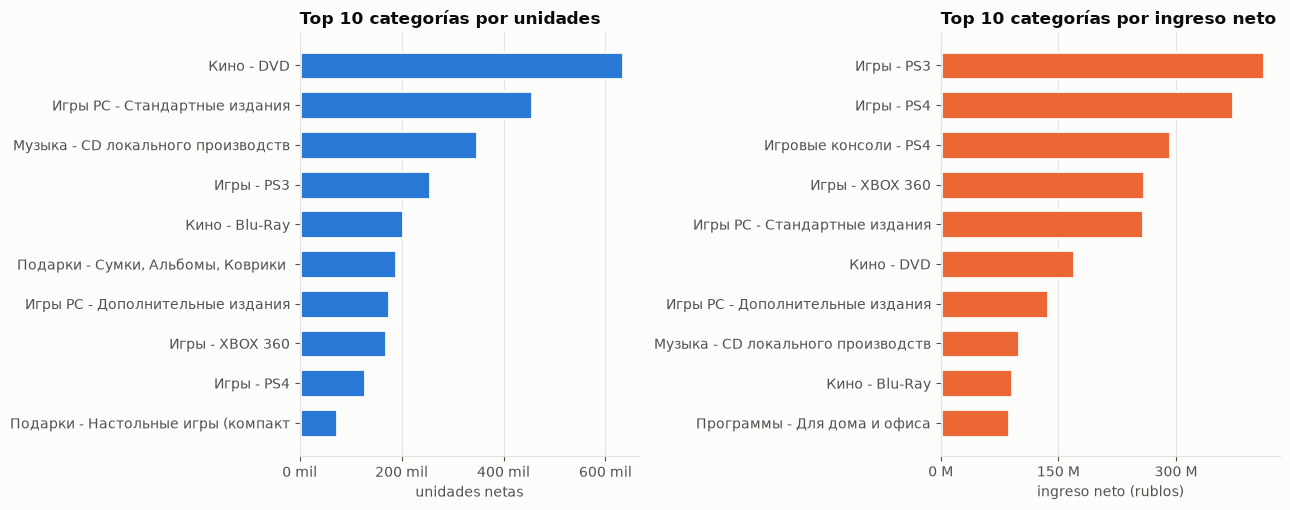

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, col, fmt in [(axes[0], "unidades", fmt_miles), (axes[1], "ingreso", fmt_millones)]:
    top = por_categoria[col].nlargest(10).iloc[::-1]
    etiquetas = [nombre[:34] for _, nombre in top.index]
    ax.barh(etiquetas, top.values, color=COLOR[col], height=0.7, edgecolor=FONDO, linewidth=2)
    ax.xaxis.set_major_formatter(fmt)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
    ax.grid(axis="x", color=REJILLA)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Top 10 categorías por {'unidades' if col == 'unidades' else 'ingreso neto'}")
    ax.set_xlabel("unidades netas" if col == "unidades" else "ingreso neto (rublos)")
fig.tight_layout()
plt.show()

**Interpretación:**
- Por **unidades** lideran los formatos físicos de bajo precio (DVD, juegos de PC, CD de música); por **ingreso**, los juegos de consola y las consolas. Aun así, ocho categorías aparecen en ambos top 10: el núcleo del negocio son juegos, cine y música.
- Las **categorías con menos ventas** son plataformas antiguas (consolas, juegos y accesorios de PS2), libros, auriculares de PC y juegos digitales para MAC. Varias tienen menos de 100 unidades netas en casi tres años, por lo que aportarán muy poca información a un modelo.

### 7.3 Desempeño de las 60 sucursales

Como muchas tiendas no estuvieron activas los 34 meses, se compara el total y también las **unidades por mes activo**. Cada tienda se clasifica según su actividad:
- **Completa:** vende los 34 meses.
- **Abrió después:** empieza después de enero de 2013 y sigue activa al final.
- **Cerró antes:** deja de vender antes de octubre de 2015.
- **Intermitente:** tiene meses sin ventas entre su primer y su último mes.

In [68]:
def segmento(fila):
    if fila["meses_activa"] < fila["ultimo_mes"] - fila["primer_mes"] + 1:
        return "intermitente"
    if fila["meses_activa"] == 34:
        return "completa"
    if fila["ultimo_mes"] < 33:
        return "cerró antes"
    return "abrió después"

por_tienda["segmento"] = por_tienda.apply(segmento, axis=1)
por_tienda["% unidades"] = por_tienda["unidades"] / por_tienda["unidades"].sum()

resumen_segmentos = por_tienda.groupby("segmento").agg(
    tiendas=("unidades", "size"),
    en_test=("en test", "sum"),
    unidades=("unidades", "sum"),
    pct_unidades=("% unidades", "sum"),
    mediana_unidades_mes=("unidades por mes activo", "median"),
).sort_values("unidades", ascending=False)
resumen_segmentos.style.format({"unidades": "{:,.0f}", "pct_unidades": "{:.1%}", "mediana_unidades_mes": "{:,.0f}"})

,tiendas,en_test,unidades,pct_unidades,mediana_unidades_mes
segmento,,,,,
completa,32,32,"2,571,499",70.5%,"1,949"
cerró antes,15,0,"499,401",13.7%,"1,478"
abrió después,9,9,"394,388",10.8%,"1,296"
intermitente,4,1,"182,918",5.0%,"3,451"


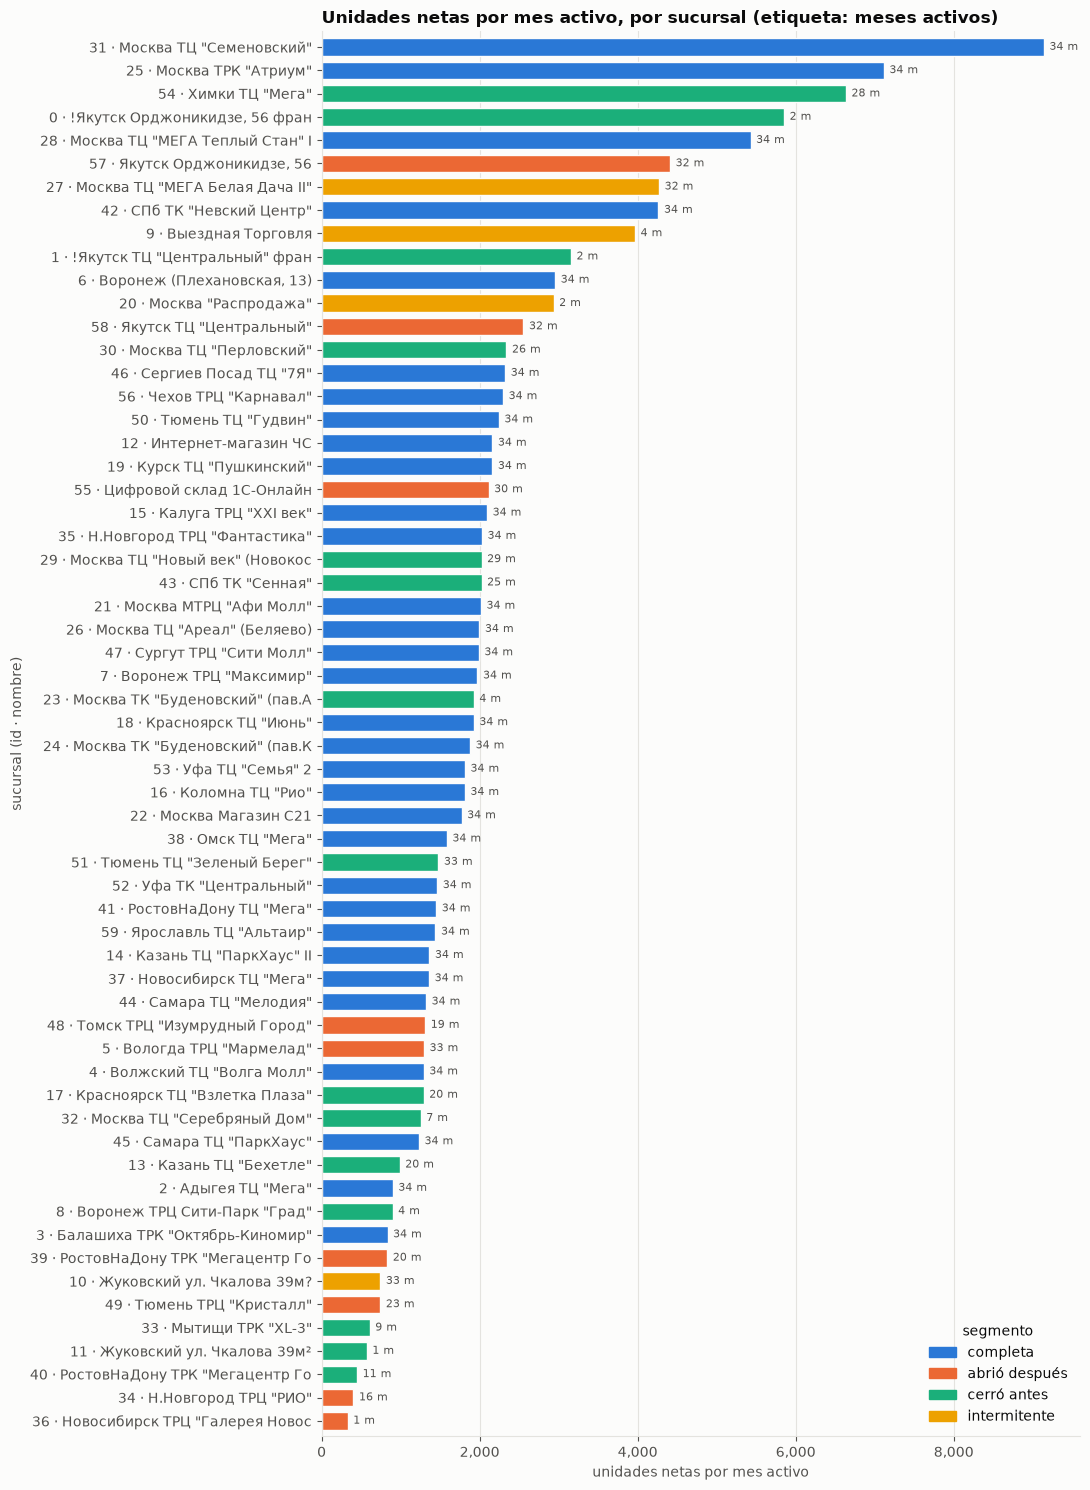

In [69]:
SEGMENTO_COLOR = {"completa": "#2a78d6", "abrió después": "#eb6834",
                  "cerró antes": "#1baf7a", "intermitente": "#eda100"}

orden = por_tienda.sort_values("unidades por mes activo")
fig, ax = plt.subplots(figsize=(11, 15))
ax.barh([f"{i} · {n[:30]}" for i, n in zip(orden.index, orden["shop_name"])],
        orden["unidades por mes activo"], color=orden["segmento"].map(SEGMENTO_COLOR),
        height=0.75, edgecolor=FONDO, linewidth=1)
for y, (_, fila) in enumerate(orden.iterrows()):
    ax.annotate(f"{fila['meses_activa']} m", (fila["unidades por mes activo"], y), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=TINTA_2)
ax.grid(axis="x", color=REJILLA)
ax.grid(axis="y", visible=False)
ax.margins(y=0.005)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_title("Unidades netas por mes activo, por sucursal (etiqueta: meses activos)")
ax.set_xlabel("unidades netas por mes activo")
ax.set_ylabel("sucursal (id · nombre)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in SEGMENTO_COLOR.values()],
          labels=list(SEGMENTO_COLOR), loc="lower right", title="segmento")
fig.tight_layout()
plt.show()

In [70]:
# Sucursales atípicas por volumen: regla IQR de Tukey sobre las unidades por mes activo
upm = por_tienda["unidades por mes activo"]
q1, q3 = upm.quantile([0.25, 0.75])
limite_superior_tienda = q3 + 1.5 * (q3 - q1)
print(f"Límite superior IQR: {limite_superior_tienda:,.0f} unidades por mes activo")
(por_tienda[upm > limite_superior_tienda]
 .sort_values("unidades por mes activo", ascending=False)
 [["shop_name", "segmento", "meses_activa", "unidades", "unidades por mes activo", "en test"]]
 .style.format({"unidades": "{:,.0f}", "unidades por mes activo": "{:,.0f}"}))

Límite superior IQR: 3,819 unidades por mes activo


,shop_name,segmento,meses_activa,unidades,unidades por mes activo,en test
shop_id,,,,,,
31,"Москва ТЦ ""Семеновский""",completa,34,"310,777","9,140",True
25,"Москва ТРК ""Атриум""",completa,34,"241,920","7,115",True
54,"Химки ТЦ ""Мега""",cerró antes,28,"185,790","6,635",False
0,"!Якутск Орджоникидзе, 56 фран",cerró antes,2,"11,705","5,852",False
28,"Москва ТЦ ""МЕГА Теплый Стан"" II",completa,34,"184,557","5,428",True
57,"Якутск Орджоникидзе, 56",abrió después,32,"141,107","4,410",True
27,"Москва ТЦ ""МЕГА Белая Дача II""",intermitente,32,"136,657","4,271",False
42,"СПб ТК ""Невский Центр""",completa,34,"144,934","4,263",True
9,Выездная Торговля,intermitente,4,"15,866","3,966",False


**Interpretación:**
- Las tiendas **completas** concentran la mayor parte de las ventas. Hay tiendas que **cerraron antes** del final del periodo, que no aparecen en `test`, y tiendas que **abrieron después**, como la 36, que solo tiene un mes de historia y sí está en `test`.
- Las tiendas **intermitentes** incluyen las de venta temporal identificadas en la sección 6 (9 `Выездная Торговля` y 20 `Москва "Распродажа"`), que solo venden durante las ferias de octubre.
- Por volumen (regla IQR sobre unidades por mes activo), las atípicas por arriba son sobre todo las **grandes tiendas de Moscú y San Petersburgo** (31 `Семеновский`, 25 `Атриум`, 54 `Химки Мега`, 28 `Теплый Стан`, 27 `Белая Дача`, 42 `Невский Центр`) y la 57 de Якутск: son **tiendas insignia** con un volumen legítimamente alto, no errores. También aparecen la **0** (solo 2 meses; es la misma tienda que la 57) y la **9** (solo vende durante las ferias): ambas tienen un promedio inflado por su poca actividad.
- La tienda **10** figura como intermitente porque le falta un único mes, el **25**, que es justo el único mes en que vende la tienda **11**. Esto refuerza que la 10 y la 11 son la misma tienda (sección 4.4).
- Comparar por mes activo corrige parcialmente el sesgo por antigüedad. Aun así, las tiendas con muy pocos meses (36, 11) tienen métricas poco fiables.

### 7.4 Detección de valores extremos

La elección del método depende de la forma de cada distribución:

| Variable | Problema | Método elegido |
|---|---|---|
| `item_price` (global) | Muy asimétrica (de 0.07 a 307,980), aproximadamente log-normal. | Regla IQR de Tukey sobre **log10(precio)**, con k = 1.5 (atípico) y k = 3 (extremo). |
| `item_cnt_day` | Cerca del 90% de los registros vale exactamente 1, así que el IQR es 0 y la regla de Tukey marcaría como atípico todo valor distinto de 1. | **Percentiles de cola**: por encima del p99.99 (o por debajo del p0.01 en devoluciones). |
| `item_price` (dentro de cada producto) | Un precio puede ser normal en general pero anómalo para su producto. La MAD es 0 porque la mayoría de los registros coincide con la mediana del producto. | **Razón respecto a la mediana del producto**: ≥ 10× o ≤ 0.1× (un orden de magnitud). |

In [71]:
log_precio = np.log10(ventas["item_price"])
q1, q3 = log_precio.quantile([0.25, 0.75])
iqr = q3 - q1
limites_precio = pd.DataFrame(
    {
        k: {
            "límite inferior": 10 ** (q1 - k * iqr),
            "límite superior": 10 ** (q3 + k * iqr),
            "registros bajo el límite": (log_precio < q1 - k * iqr).sum(),
            "registros sobre el límite": (log_precio > q3 + k * iqr).sum(),
        }
        for k in (1.5, 3)
    }
).T
limites_precio.index = ["k = 1.5 (atípico)", "k = 3 (extremo)"]
limites_precio["% registros"] = (limites_precio["registros bajo el límite"] + limites_precio["registros sobre el límite"]) / len(ventas)
limites_precio.style.format({"límite inferior": "{:,.2f}", "límite superior": "{:,.0f}",
                             "registros bajo el límite": "{:,.0f}", "registros sobre el límite": "{:,.0f}",
                             "% registros": "{:.2%}"})

,límite inferior,límite superior,registros bajo el límite,registros sobre el límite,% registros
k = 1.5 (atípico),30.98,"8,028","50,433","24,342",2.55%
k = 3 (extremo),3.86,"64,515","5,936",1,0.20%


In [72]:
cuantiles_cantidad = ventas["item_cnt_day"].quantile([0.0001, 0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 0.9999])
print(f"Registros con item_cnt_day == 1: {(ventas['item_cnt_day'] == 1).mean():.1%} "
      f"-> IQR = {cuantiles_cantidad[0.75] - cuantiles_cantidad[0.25]:.0f}")
limite_cantidad_alto = cuantiles_cantidad[0.9999]
limite_cantidad_bajo = cuantiles_cantidad[0.0001]
mask_cantidad_extrema = (ventas["item_cnt_day"] > limite_cantidad_alto) | (ventas["item_cnt_day"] < limite_cantidad_bajo)
print(f"Límites p0.01 / p99.99: {limite_cantidad_bajo:.0f} / {limite_cantidad_alto:.0f} unidades")
print(f"Registros con cantidad extrema: {mask_cantidad_extrema.sum():,}")
cuantiles_cantidad.rename(lambda q: f"p{q * 100:g}").to_frame("item_cnt_day").T

Registros con item_cnt_day == 1: 89.6% -> IQR = 0
Límites p0.01 / p99.99: -1 / 67 unidades
Registros con cantidad extrema: 397


,p0.01,p0.1,p1,p25,p50,p75,p99,p99.9,p99.99
item_cnt_day,-1.0,-1.0,1.0,1.0,1.0,1.0,5.0,22.0,67.0


In [73]:
mediana_producto = ventas.groupby("item_id")["item_price"].transform("median")
razon_precio = ventas["item_price"] / mediana_producto
mask_precio_contexto = (razon_precio >= 10) | (razon_precio <= 0.1)
print(f"Registros iguales a la mediana de su producto: {(razon_precio == 1).mean():.1%} (por eso MAD = 0)")
print(f"Precios >= 10x la mediana del producto: {(razon_precio >= 10).sum():,}")
print(f"Precios <= 0.1x la mediana del producto: {(razon_precio <= 0.1).sum():,}")
print(f"Productos afectados: {ventas.loc[mask_precio_contexto, 'item_id'].nunique():,}")

Registros iguales a la mediana de su producto: 67.4% (por eso MAD = 0)
Precios >= 10x la mediana del producto: 1,218
Precios <= 0.1x la mediana del producto: 2,904
Productos afectados: 300


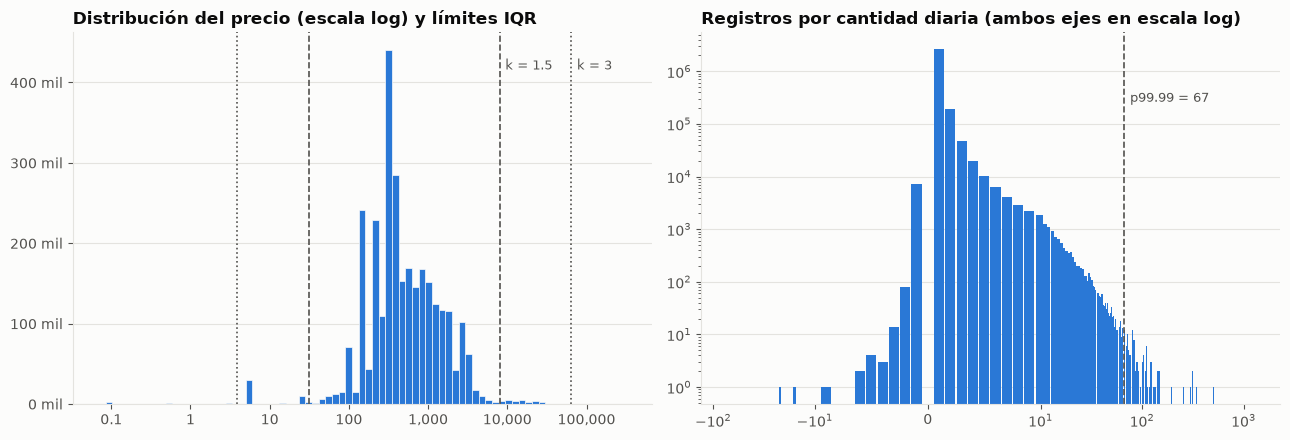

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(log_precio.min(), log_precio.max(), 80)
axes[0].hist(log_precio, bins=bins, color=COLOR["unidades"], edgecolor=FONDO, linewidth=0.5)
for k, estilo in [(1.5, "--"), (3, ":")]:
    for limite in (q1 - k * iqr, q3 + k * iqr):
        axes[0].axvline(limite, color=TINTA_2, linestyle=estilo, linewidth=1.2)
    axes[0].annotate(f"k = {k}", (q3 + k * iqr, axes[0].get_ylim()[1] * 0.9), xytext=(4, 0),
                     textcoords="offset points", fontsize=9, color=TINTA_2)
axes[0].set_xticks(range(-1, 6), [f"{10 ** e:,.1f}" if e < 0 else f"{10 ** e:,.0f}" for e in range(-1, 6)])
axes[0].yaxis.set_major_formatter(fmt_miles)
axes[0].set_title("Distribución del precio (escala log) y límites IQR")

conteo = ventas["item_cnt_day"].value_counts().sort_index()
axes[1].bar(conteo.index, conteo.values, width=0.9, color=COLOR["unidades"])
axes[1].set_yscale("log")
axes[1].set_xscale("symlog", linthresh=10)
axes[1].axvline(limite_cantidad_alto, color=TINTA_2, linestyle="--", linewidth=1.2)
axes[1].annotate(f"p99.99 = {limite_cantidad_alto:.0f}", (limite_cantidad_alto, conteo.max() / 10), xytext=(4, 0),
                 textcoords="offset points", fontsize=9, color=TINTA_2)
axes[1].set_title("Registros por cantidad diaria (ambos ejes en escala log)")
fig.tight_layout()
plt.show()

**Interpretación:**
- **Precio global:** con k = 1.5 se marca alrededor de un 2.5% de los registros, en su mayoría productos baratos (accesorios, regalos) o caros (consolas) perfectamente normales. Con k = 3 solo queda **un registro por encima** (307,980) y unos 6,000 por debajo de ~4, es decir, **precios simbólicos**. El criterio extremo (k = 3) es más útil para investigar.
- **Cantidad:** el IQR es 0, por lo que se usa la cola de la distribución. Por encima del p99.99 (67 unidades en un día) quedan unos pocos cientos de registros.
- **Precio dentro del producto:** algunos miles de registros tienen un precio al menos 10 veces mayor o menor que la mediana de su producto. Suelen concentrarse en periodos y productos concretos, lo que apunta a **promociones** más que a errores aislados (ver 7.5).

### 7.5 Investigación de los casos más relevantes

#### 7.5.1 Cantidades extremas

In [75]:
cols_caso = ["date", "shop_id", "item_id", "item_price", "item_cnt_day", "revenue"]
def enriquecer(df):
    out = df[cols_caso].copy()
    out.insert(2, "tienda", out["shop_id"].map(nombre_tienda).str[:24])
    out.insert(4, "producto", out["item_id"].map(nombre_item).str[:45])
    out.insert(5, "categoría", out["item_id"].map(producto_info["categoría"]).str[:30])
    return out

formato_caso = {"item_price": "{:,.2f}", "item_cnt_day": "{:,.0f}", "revenue": "{:,.0f}", "date": "{:%d/%m/%Y}"}
enriquecer(ventas.nlargest(12, "item_cnt_day")).style.format(formato_caso)

,date,shop_id,tienda,item_id,producto,categoría,item_price,item_cnt_day,revenue
2909818,28/10/2015,12,Интернет-магазин ЧС,11373,Доставка до пункта выдачи (Boxberry),Доставка товара,0.91,"2,169","1,971"
2326930,15/01/2015,12,Интернет-магазин ЧС,20949,Фирменный пакет майка 1С Интерес белый (34*42,"Подарки - Сумки, Альбомы, Ковр",4.00,"1,000","4,000"
2864235,30/09/2015,12,Интернет-магазин ЧС,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)",Служебные - Билеты,"1,692.53",669,"1,132,300"
2851091,30/09/2015,55,Цифровой склад 1С-Онлайн,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)",Билеты (Цифра),"1,702.83",637,"1,084,700"
2608040,14/04/2015,12,Интернет-магазин ЧС,3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,"1,904.55",624,"1,188,438"
2626181,19/05/2015,12,Интернет-магазин ЧС,11373,Доставка до пункта выдачи (Boxberry),Доставка товара,155.19,539,"83,649"
2851073,29/09/2015,55,Цифровой склад 1С-Онлайн,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)",Билеты (Цифра),"1,500.00",533,"799,500"
2048518,02/10/2014,12,Интернет-магазин ЧС,9242,"Билет ""ИгроМир 2014"" (на один день (отдельно",Билеты (Цифра),"1,500.00",512,"768,000"
2067669,09/10/2014,55,Цифровой склад 1С-Онлайн,19437,"Средиземье: Тени Мордора [PC, Цифровая версия",Игры PC - Цифра,899.00,508,"456,692"
2864260,29/09/2015,12,Интернет-магазин ЧС,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт)",Служебные - Билеты,"1,500.00",504,"756,000"


In [76]:
extremos_cantidad = ventas[ventas["item_cnt_day"] > limite_cantidad_alto]
por_tienda_ext = extremos_cantidad["shop_id"].map(nombre_tienda).value_counts(normalize=True).head(5)
print("Tiendas con más registros de cantidad extrema (proporción):")
print(por_tienda_ext.map("{:.1%}".format).to_string())
print("\nCategorías con más registros de cantidad extrema (proporción):")
print(extremos_cantidad["item_category_name"].value_counts(normalize=True).head(6).map("{:.1%}".format).to_string())

Tiendas con más registros de cantidad extrema (proporción):
shop_id
Интернет-магазин ЧС         24.9%
Цифровой склад 1С-Онлайн    15.4%
Москва ТРК "Атриум"          8.9%
Москва ТЦ "Семеновский"      8.5%
СПб ТК "Невский Центр"       6.8%

Categorías con más registros de cantidad extrema (proporción):
item_category_name
Игры PC - Стандартные издания               17.4%
Подарки - Сумки, Альбомы, Коврики д/мыши    16.4%
Игры PC - Цифра                             10.9%
Игры - PS4                                  10.6%
Игры - PS3                                   8.5%
Игры PC - Дополнительные издания             8.2%


In [77]:
print("Devoluciones más grandes (cantidad más negativa):")
enriquecer(ventas.nsmallest(5, "item_cnt_day")).style.format(formato_caso)

Devoluciones más grandes (cantidad más negativa):


,date,shop_id,tienda,item_id,producto,categoría,item_price,item_cnt_day,revenue
1057907,02/11/2013,12,Интернет-магазин ЧС,8023,ZL004 Лазерные наклейки Смайлики маленькие,"Подарки - Открытки, наклейки",15.00,-22,-330
1835454,10/07/2014,14,"Казань ТЦ ""ПаркХаус"" II",20949,Фирменный пакет майка 1С Интерес белый (34*42,"Подарки - Сумки, Альбомы, Ковр",5.00,-16,-80
2048519,10/10/2014,12,Интернет-магазин ЧС,9242,"Билет ""ИгроМир 2014"" (на один день (отдельно",Билеты (Цифра),"1,433.33",-9,"-12,900"
59156,18/01/2013,12,Интернет-магазин ЧС,1590,"Assassin’s Creed 3. Freedom Edition [PC, русс",Игры PC - Коллекционные издани,"2,599.00",-6,"-15,594"
940092,19/10/2013,42,"СПб ТК ""Невский Центр""",3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,"2,599.00",-6,"-15,594"


#### 7.5.2 Precios extremos

In [78]:
enriquecer(ventas.nlargest(8, "item_price")).style.format(formato_caso)

,date,shop_id,tienda,item_id,producto,categoría,item_price,item_cnt_day,revenue
1163158,13/12/2013,12,Интернет-магазин ЧС,6066,Radmin 3 - 522 лиц.,Программы - Для дома и офиса,"307,980.00",1,"307,980"
885138,17/09/2013,12,Интернет-магазин ЧС,11365,Доставка (EMS),Доставка товара,"59,200.00",1,"59,200"
1488135,20/03/2014,25,"Москва ТРК ""Атриум""",13199,Коллекционные шахматы (Властелин Колец),Подарки - Сувениры,"50,999.00",1,"50,999"
2327159,29/01/2015,12,Интернет-магазин ЧС,7241,UserGate Proxy & Firewall 6.X с модулем фильт,Программы - Для дома и офиса,"49,782.00",1,"49,782"
2885692,23/10/2015,42,"СПб ТК ""Невский Центр""",13403,"Комплект ""Microsoft Xbox One 1TB Limited Edi",Игровые консоли - XBOX ONE,"42,990.00",1,"42,990"
2910156,29/10/2015,12,Интернет-магазин ЧС,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edi",Игровые консоли - XBOX ONE,"42,990.00",1,"42,990"
2917760,20/10/2015,3,"Балашиха ТРК ""Октябрь-Ки",13403,"Комплект ""Microsoft Xbox One 1TB Limited Edi",Игровые консоли - XBOX ONE,"42,990.00",1,"42,990"
2931380,20/10/2015,22,Москва Магазин С21,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edi",Игровые консоли - XBOX ONE,"42,990.00",1,"42,990"


In [79]:
# Precios simbólicos: ¿son errores aislados o una práctica sistemática?
precio_simbolico = ventas[ventas["item_price"] < 1]
resumen_simbolico = precio_simbolico.groupby("date_block_num").agg(
    mes=("date", lambda s: s.min().strftime("%Y-%m")),
    registros=("item_id", "size"),
    productos=("item_id", "nunique"),
    tiendas=("shop_id", "nunique"),
    precio_mas_comun=("item_price", lambda s: s.round(2).mode().iloc[0]),
)
print(f"Registros con precio < 1: {len(precio_simbolico):,} en {precio_simbolico['item_id'].nunique()} productos")
resumen_simbolico[resumen_simbolico["registros"] >= 50]

Registros con precio < 1: 4,657 en 66 productos


,mes,registros,productos,tiendas,precio_mas_comun
date_block_num,,,,,
5,2013-06,1689,27,40,0.10
6,2013-07,745,28,39,0.10
7,2013-08,503,29,37,0.10
18,2014-07,1185,29,44,0.50
30,2015-07,380,7,39,0.99
31,2015-08,79,7,21,0.99


In [80]:
# Ejemplo: juguete antiestrés con precio normal al inicio y precio simbólico de 0.10 a mediados de 2013
ejemplo = ventas[ventas["item_id"] == 11865]
print(nombre_item[11865])
ejemplo.groupby("date_block_num")["item_price"].agg(["size", "median", "min", "max"]).T.style.format("{:,.2f}")

Змей МАКС антистресс 33 см.


date_block_num,0,1,2,3,4,5,6,7,13,15,16,17,18
size,14.00,5.00,4.00,5.00,3.00,101.00,36.00,18.00,1.00,2.00,3.00,4.00,1.00
median,510.15,510.00,329.00,329.00,329.00,0.10,0.10,0.10,148.00,148.00,58.00,56.50,46.40
min,335.00,510.00,230.00,306.00,306.00,0.07,0.10,0.10,148.00,148.00,58.00,55.00,46.40
max,729.00,510.00,329.00,329.00,329.00,329.00,328.00,119.25,148.00,148.00,98.00,58.00,46.40


In [81]:
# Productos con más registros fuera de rango respecto a su propia mediana
fuera_contexto = ventas[mask_precio_contexto]
(fuera_contexto.groupby("item_id")
 .agg(registros=("item_price", "size"), meses=("date_block_num", "nunique"),
      tiendas=("shop_id", "nunique"), precio_min=("item_price", "min"), precio_max=("item_price", "max"))
 .assign(mediana_producto=lambda d: ventas.groupby("item_id")["item_price"].median().reindex(d.index),
         producto=lambda d: d.index.map(nombre_item).str[:45])
 .nlargest(10, "registros")
 .style.format({"precio_min": "{:,.2f}", "precio_max": "{:,.2f}", "mediana_producto": "{:,.2f}"}))

,registros,meses,tiendas,precio_min,precio_max,mediana_producto,producto
item_id,,,,,,,
15346,237,3,39,0.99,0.99,149.00,Мягкая игрушка Веселая овечка Заводная 11см
2969,232,5,41,499.00,549.00,49.00,"Divinity: Dragon Commander [PC, Jewel, русски"
3325,200,2,44,49.00,49.00,799.00,"FIFA 13 [PC, русская версия]"
1855,183,2,40,0.50,0.50,799.00,"Battlefield 4 [PC, русская версия]"
17717,176,33,44,9.00,"16,790.00",999.00,Прием денежных средств для 1С-Онлайн
1856,148,2,38,0.50,0.50,"1,499.00","Battlefield 4 [PS3, русская версия]"
7018,140,3,43,0.50,2.99,"1,199.00","Titanfall [PC, русская версия]"
1858,111,2,37,0.50,0.50,"1,499.00","Battlefield 4 [Xbox 360, русская версия]"
11867,110,12,38,6.42,99.00,0.10,Змей ШНУР 15 см


#### 7.5.3 Sucursales con comportamiento particular

In [82]:
especiales = [12, 55, 9, 20, 36, 0, 1, 57, 58, 10, 11, 39, 40]
categoria_principal = (
    ventas[ventas["shop_id"].isin(especiales)]
    .groupby(["shop_id", "item_category_name"])["item_cnt_day"].sum()
    .groupby(level=0).idxmax().map(lambda t: t[1])
)
(por_tienda.loc[especiales, ["shop_name", "segmento", "meses_activa", "primer_mes", "ultimo_mes",
                              "unidades", "unidades por mes activo", "en test"]]
 .assign(categoria_principal=categoria_principal)
 .style.format({"unidades": "{:,.0f}", "unidades por mes activo": "{:,.0f}"}))

,shop_name,segmento,meses_activa,primer_mes,ultimo_mes,unidades,unidades por mes activo,en test,categoria_principal
shop_id,,,,,,,,,
12,Интернет-магазин ЧС,completa,34,0,33,"73,478","2,161",True,Доставка товара
55,Цифровой склад 1С-Онлайн,abrió después,30,4,33,"63,388","2,113",True,Игры PC - Цифра
9,Выездная Торговля,intermitente,4,9,33,"15,866","3,966",False,Игры PC - Стандартные издания
20,"Москва ""Распродажа""",intermitente,2,21,33,"5,872","2,936",False,Подарки - Атрибутика
36,"Новосибирск ТРЦ ""Галерея Новосибирск""",abrió después,1,33,33,330,330,True,Музыка - CD локального производства
0,"!Якутск Орджоникидзе, 56 фран",cerró antes,2,0,1,"11,705","5,852",False,Кино - DVD
1,"!Якутск ТЦ ""Центральный"" фран",cerró antes,2,0,1,"6,311","3,156",False,Кино - DVD
57,"Якутск Орджоникидзе, 56",abrió después,32,2,33,"141,107","4,410",True,Кино - DVD
58,"Якутск ТЦ ""Центральный""",abrió después,32,2,33,"81,734","2,554",True,Кино - DVD


#### 7.5.4 Diagnóstico: errores frente a comportamientos legítimos

| Caso | Evidencia en los datos | Diagnóstico | Recomendación (sin aplicar aún) |
|---|---|---|---|
| **Precio 307,980** (item 6066, `Radmin 3 - 522 лиц.`, tienda 12) | Única venta del producto; el nombre indica una licencia para 522 usuarios (~590 por licencia). | **Legítimo** (venta corporativa por volumen), pero irrepetible. | Mantener; no influye en `item_cnt_month` (1 unidad). Recortar o excluir si se usa el precio como variable. |
| **2,169 unidades a 0.91** (item 11373, `Доставка до пункта выдачи`, tienda 12) | Es un **servicio de envío**, no un producto. Solo se vende en la tienda online (es su categoría principal) y su precio diario es un promedio muy variable. | **No es demanda de producto**: registro operativo, aunque real. | No eliminar: el item aparece en `test` (42 tiendas). Tratar las categorías de servicio aparte (marcarlas) y recortar el objetivo. |
| **Cobros `Прием денежных средств для 1С-Онлайн`** (item 17717, top 4 en unidades) | Es un **servicio de cobro**: su precio varía de 9 a 16,790 porque refleja el importe cobrado, no un precio de producto. | **No es demanda de producto**. | Igual que el anterior: también está en `test`; marcarlo como servicio y no usar su precio como variable. |
| **Bolsa de marca 20949** (hasta 1,000 unidades/día a ~4) | Producto más vendido en unidades; acompaña a casi cualquier compra; picos de cientos de unidades en tiendas grandes. | **Legítimo**, pero es un consumible de empaque. | Mantener; considerar recortar el objetivo (el recorte a [0, 20] ya limita su efecto) y vigilarlo en las métricas. |
| **Entradas «ИгроМир»** (cientos por día, tiendas 12 y 55, finales de sept.) | Venta anticipada de entradas para una feria de videojuegos, concentrada en pocos días al año. | **Legítimo** (evento estacional). | Mantener; tratar como evento puntual. |
| **Lanzamientos** (GTA V PC 624 u., The Witcher 3 480 u. en la tienda 12) | Coinciden con las fechas de lanzamiento (sección 6.5) y con la tienda online (pedidos anticipados). | **Legítimo**. | Mantener; útil para variables de "novedad" del producto. |
| **Precios simbólicos y de liquidación** (< 1: 0.10, 0.50, 0.99; o precios ≥ 10× / ≤ 0.1× la mediana del producto) | Se repiten **cada verano** (jun–ago 2013 a 0.10, jul 2014 a 0.50, jul–ago 2015 a 0.99), afectan a decenas de productos en 20–44 tiendas a la vez (por ejemplo, Battlefield 4 a 0.50 o juguetes antiestrés a 0.10). Otros productos tienen precios de liquidación (FIFA 13 a 49 frente a 799). | **Promociones** (regalo con compra o liquidación), no errores de captura. | Mantener en unidades; para variables de precio, usar la mediana del producto o marcar el periodo promocional. |
| **Devoluciones grandes** (hasta −22) | Pocas, en la tienda online o en productos baratos. | **Legítimas** (devoluciones). | Mantener; ya se suman en el total neto. |
| **Tiendas 9 y 20** | Intermitentes, solo activas en las ferias de octubre. | **Legítimas**, pero temporales. | Mantener; no son comparables con tiendas permanentes y no están en `test`. |
| **Tienda 12 (online) y 55 (almacén digital)** | Concentran la mayoría de las cantidades extremas; la 55 vende casi solo productos digitales. | **Canales distintos** a las tiendas físicas. | Mantener; tratarlas como canales propios en el análisis. |
| **Tiendas 0/57, 1/58 y 10/11** | Periodos complementarios y nombres casi idénticos (sección 4.4). | **Error de registro** (ID duplicado). | Unificar en la etapa de limpieza (ya propuesto en 4.5). |
| **Tienda 36** | Solo vende en el último mes y está en `test`. | **Legítima** (apertura reciente). | Mantener; tendrá muy poca historia para predecir. |

**Conclusión:** casi todos los valores extremos responden a **comportamientos comerciales legítimos** (ventas corporativas, lanzamientos, eventos, promociones y canales online). Los pocos casos que no representan demanda de producto (servicios de envío y de cobro, que sin embargo están en `test`) o que son errores (IDs de tienda duplicados) se tratarán en la etapa de limpieza. Ningún registro se elimina en este notebook.

## 8. Visualizaciones clave obligatorias

Objetivo de esta sección: asegurar que el notebook contiene las cinco visualizaciones clave del proyecto. Se **reutilizan** las gráficas que ya cumplen el requisito (para no duplicarlas) y solo se crean las que faltan.

| Visualización obligatoria | Dónde está | Estado |
|---|---|---|
| Serie temporal de ventas totales | Sección **6.2**: unidades e ingreso neto por mes, con media móvil de 12 meses (complementada por la serie diaria de 6.5.2). | Reutilizada; se añadieron etiquetas de ejes con unidades. |
| Barras de ventas por sucursal | Sección **7.3**: unidades netas por mes activo de las 60 sucursales, coloreadas por segmento. | Reutilizada; se añadieron etiquetas de ejes. |
| Barras de los productos top N | — (solo había tablas en 7.1). | **Nueva**: 8.1. |
| Barras por categoría | Sección **7.2**: top 10 categorías por unidades y por ingreso neto. | Reutilizada; se añadieron etiquetas de ejes. |
| Heatmap de ventas por mes y sucursal | — | **Nueva**: 8.2. |

Todos los importes están en rublos y todas las cantidades son **netas** (incluyen devoluciones).

### 8.1 Productos top 10 por unidades y por ingreso neto

Los productos que no son mercancía en sentido estricto se marcan en la etiqueta: **[empaque]** para la bolsa de marca y **[servicio]** para los cobros y envíos (sección 7.5).

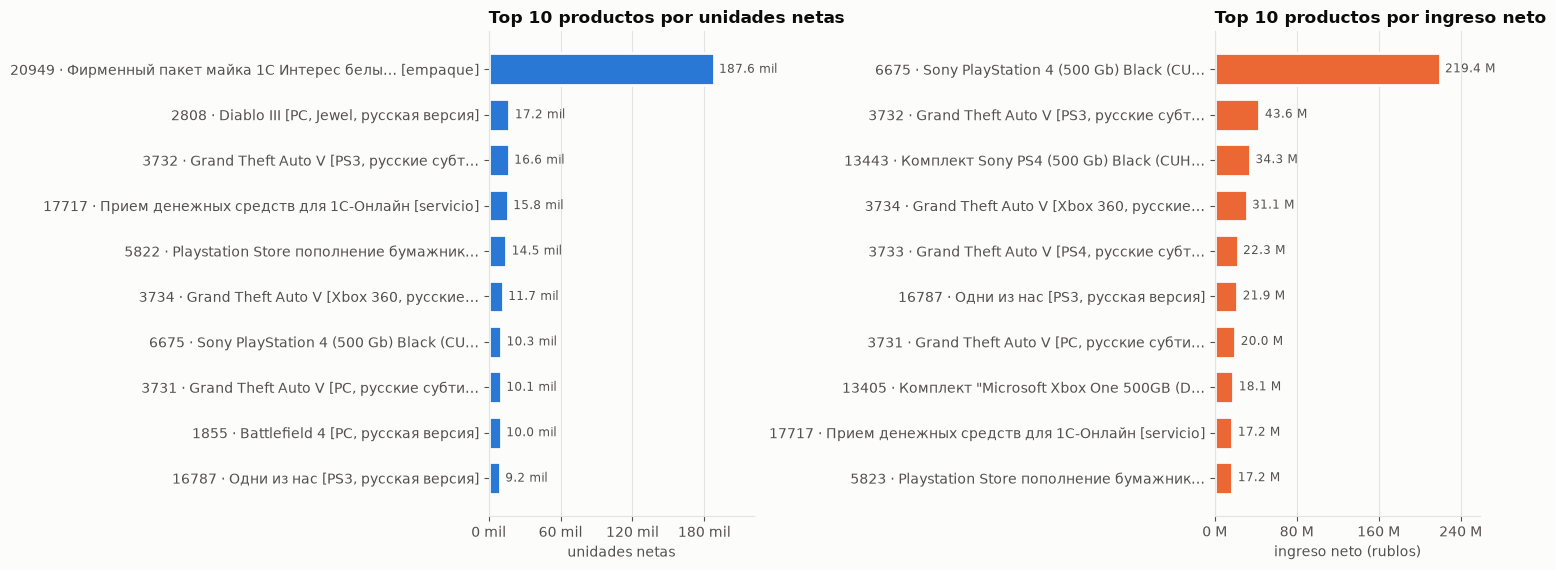

In [83]:
NATURALEZA = {20949: "empaque", 17717: "servicio", 11373: "servicio"}

def etiqueta_producto(item_id, largo=38):
    nombre = nombre_item[item_id]
    nombre = nombre if len(nombre) <= largo else nombre[: largo - 1] + "…"
    marca = f" [{NATURALEZA[item_id]}]" if item_id in NATURALEZA else ""
    return f"{item_id} · {nombre}{marca}"

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, col, fmt, etiqueta_x in [
    (axes[0], "unidades", mticker.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} mil"), "unidades netas"),
    (axes[1], "ingreso", fmt_millones, "ingreso neto (rublos)"),
]:
    top = por_producto[col].nlargest(10).iloc[::-1]
    ax.barh([etiqueta_producto(i) for i in top.index], top.values, color=COLOR[col],
            height=0.7, edgecolor=FONDO, linewidth=2)
    for y, valor in enumerate(top.values):
        texto = f"{valor / 1e3:,.1f} mil" if col == "unidades" else f"{valor / 1e6:,.1f} M"
        ax.annotate(texto, (valor, y), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=TINTA_2)
    ax.set_xlim(0, top.max() * 1.18)
    ax.xaxis.set_major_formatter(fmt)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
    ax.grid(axis="x", color=REJILLA)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(etiqueta_x)
    ax.set_title(f"Top 10 productos por {etiqueta_x.split(' (')[0]}")
fig.tight_layout()
plt.show()

**Interpretación:**
- Por **unidades**, la bolsa de marca (187.6 mil) multiplica por diez al segundo producto. Sin ella y sin el servicio de cobro, el ranking lo forman **videojuegos superventas** (Diablo III, GTA V en varias plataformas, Battlefield 4, The Last of Us) y tarjetas de pago de PlayStation Store.
- Por **ingreso**, la **PlayStation 4** (219 M) genera por sí sola casi lo mismo que los nueve siguientes juntos (unos 226 M). El resto son GTA V, packs de consola y tarjetas de pago.
- **GTA V** es el único título fuerte en ambos rankings: es el producto estrella del periodo.

### 8.2 Heatmap de ventas por mes y sucursal

Cada celda muestra las **unidades netas vendidas** por una sucursal en un mes. Las celdas grises indican que la sucursal **no tuvo ventas** ese mes. Las sucursales se ordenan por su primer mes con ventas y, dentro de él, por volumen total. La escala de color es de raíz cuadrada para que las tiendas pequeñas también muestren su patrón, a pesar de que unas pocas tiendas grandes dominan los valores.

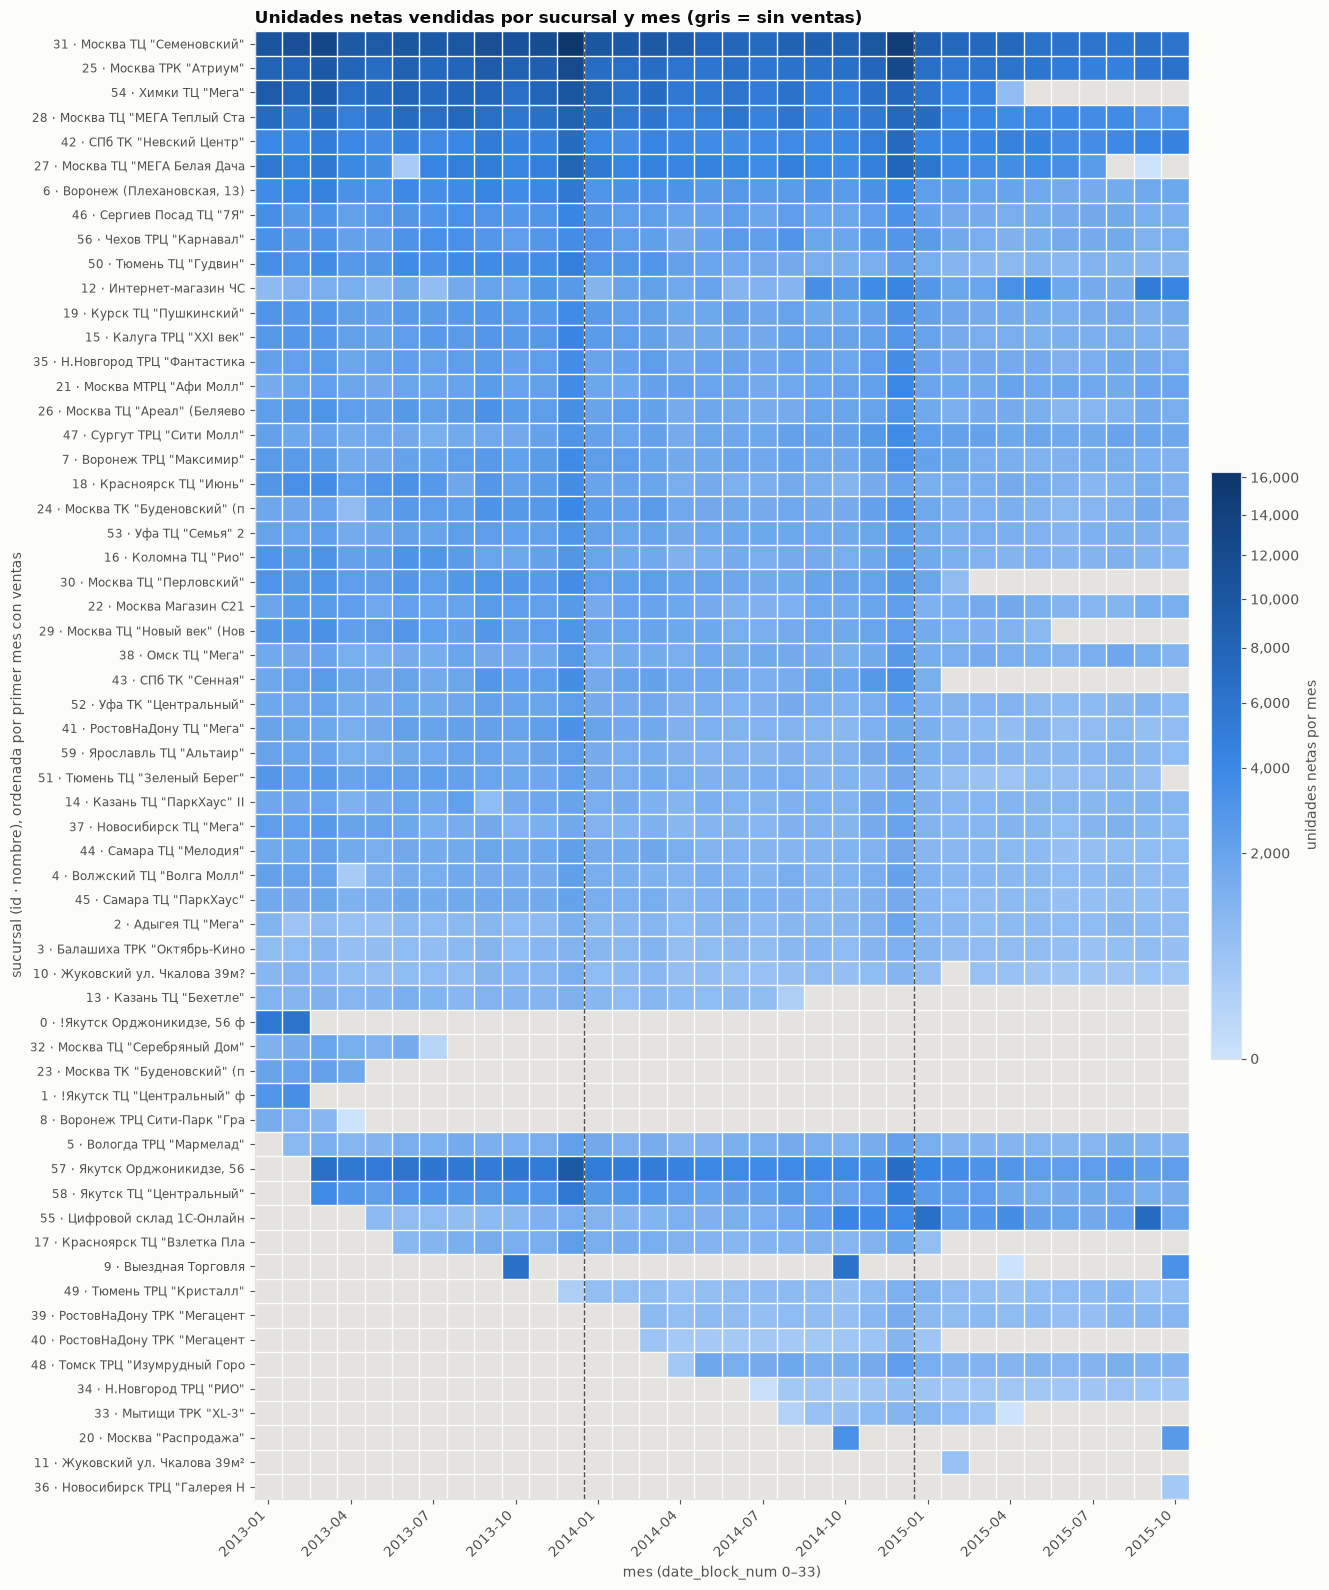

In [84]:
from matplotlib.colors import LinearSegmentedColormap, PowerNorm

matriz = ventas.pivot_table(index="shop_id", columns="date_block_num", values="item_cnt_day",
                            aggfunc="sum")
orden_tiendas = por_tienda.sort_values(["primer_mes", "unidades"], ascending=[True, False]).index
matriz = matriz.reindex(index=orden_tiendas, columns=range(34))

azules = LinearSegmentedColormap.from_list(
    "azul_secuencial", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
azules.set_bad("#e4e3df")

fig, ax = plt.subplots(figsize=(14, 16))
imagen = ax.imshow(matriz.clip(lower=0), aspect="auto", cmap=azules,
                   norm=PowerNorm(gamma=0.5, vmin=0, vmax=matriz.max().max()), interpolation="nearest")
ax.set_yticks(range(len(matriz)), [f"{i} · {nombre_tienda[i][:26]}" for i in matriz.index], fontsize=8.5)
meses_etiqueta = serie.set_index("date_block_num")["mes"]
ax.set_xticks(range(0, 34, 3), [meses_etiqueta[m] for m in range(0, 34, 3)], rotation=45, ha="right")
ax.set_xticks(np.arange(-0.5, 34, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(matriz), 1), minor=True)
ax.grid(which="minor", color=FONDO, linewidth=1)
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
for x in (11.5, 23.5):
    ax.axvline(x, color=TINTA_2, linewidth=1, linestyle="--")
ax.set_xlabel("mes (date_block_num 0–33)")
ax.set_ylabel("sucursal (id · nombre), ordenada por primer mes con ventas")
ax.set_title("Unidades netas vendidas por sucursal y mes (gris = sin ventas)")
barra = fig.colorbar(imagen, ax=ax, shrink=0.4, pad=0.02)
barra.set_label("unidades netas por mes")
barra.ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.tight_layout()
plt.show()

In [85]:
celdas_con_ventas = matriz.notna().sum().sum()
print(f"Celdas sucursal–mes con ventas: {celdas_con_ventas:,} de {matriz.size:,} ({celdas_con_ventas / matriz.size:.1%})")
print(f"Sucursales con ventas en octubre de 2015 (mes 33): {matriz[33].notna().sum()}")
print(f"Valor máximo: {matriz.max().max():,.0f} unidades "
      f"(tienda {matriz.max(axis=1).idxmax()}, mes {matriz.max().idxmax()})")

Celdas sucursal–mes con ventas: 1,586 de 2,040 (77.7%)
Sucursales con ventas en octubre de 2015 (mes 33): 44
Valor máximo: 16,318 unidades (tienda 31, mes 11)


**Interpretación:**
- **Estacionalidad común:** las columnas de **diciembre** (justo antes de cada línea discontinua, que marca el cambio de año) son las más oscuras en casi todas las sucursales activas. El pico de Año Nuevo es generalizado, no exclusivo de unas pocas tiendas.
- **Tendencia descendente:** en la mayoría de las filas el color se aclara de izquierda a derecha, lo que confirma a nivel de tienda la caída de unidades vista en la sección 6. La excepción son los **canales online**: la tienda online (12) y el almacén digital (55) se oscurecen con el tiempo, es decir, **crecen** mientras las tiendas físicas caen.
- **Ciclo de vida de las tiendas:** el heatmap muestra claramente las **aperturas** (filas que empiezan tarde), los **cierres** (filas que terminan antes del mes 33) y las tiendas **intermitentes** (9 y 20, con celdas aisladas en octubre). También se ve que la tienda **11** rellena exactamente el hueco del mes 25 de la tienda **10**, y que las tiendas **0 y 1** dejan de vender justo cuando empiezan la **57 y la 58**.
- **Dominio de las tiendas insignia:** la tienda 31 (Moscú, `Семеновский`) es la más oscura en todo el periodo, seguida de la 25 y la 54.
- **Implicación para el modelo:** solo las sucursales con historia hasta el mes 33 son relevantes para predecir el mes 34. Las tiendas cerradas aportan historia, pero no predicciones.

## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)

Objetivo de esta sección: medir cuánto se parecen las ventas de un periodo a las de periodos anteriores, para identificar **persistencia** (dependencia de los meses recientes) y **estacionalidad** (repetición cada 12 meses o cada 7 días).

- **ACF (autocorrelación):** correlación entre la serie y la misma serie desplazada *k* periodos (rezago *k*). Incluye efectos directos e indirectos.
- **PACF (autocorrelación parcial):** correlación con el rezago *k* después de descontar el efecto de los rezagos intermedios 1…*k*−1. Indica qué rezagos aportan información **propia**.

Las correlaciones describen asociaciones temporales; **no implican causalidad**.

### 9.1 Criterios: rezagos, construcción de series y limitaciones

**Rezagos:**
- **Mensual:** hay solo **34 observaciones**, así que se usan **15 rezagos**. Así se cubre el rezago estacional 12 y sus vecinos, y se respeta el límite de la PACF (menos de n/2 = 17 rezagos).
- **Diario:** hay 1,034 observaciones; se usan **35 rezagos** (5 semanas), suficientes para ver el ciclo semanal (7, 14, 21, 28, 35).

**Construcción de series mensuales continuas (meses 0 a 33):**

| Situación | Valor asignado | Motivo |
|---|---|---|
| La entidad vendió ese mes | Suma neta de `item_cnt_day` | Dato observado. |
| La tienda estaba **activa** (vendió algo ese mes), pero no vendió ese producto | **0** | Es una venta nula real: el producto pudo venderse y no se vendió. |
| La tienda **no tuvo actividad** ese mes (antes de abrir, después de cerrar o en un hueco) | **Sin dato (NaN)** | No hubo oportunidad de venta; rellenar con 0 inventaría una caída que no ocurrió. |
| Producto antes de su primera venta | **Sin dato (NaN)** | El producto todavía no estaba en el mercado. |

Para calcular ACF y PACF se requieren series **sin huecos**. Por eso la selección se limita a sucursales activas los 34 meses y a productos cuya historia empieza en el mes 0.

**Limitaciones:**
- **Bandas de confianza anchas:** con n = 34, una correlación debe superar aproximadamente ±0.34 para ser significativa al 95%, y la banda de la ACF se ensancha con el rezago (fórmula de Bartlett). Solo se detectan relaciones fuertes.
- **Pocas repeticiones estacionales:** el rezago 12 se estima con solo 22 pares de meses (menos de dos ciclos completos), por lo que la evidencia estacional es frágil.
- **Tendencia:** la caída sostenida de las ventas (sección 6) produce una ACF que decae lentamente y puede ocultar la estacionalidad. Por eso también se analiza la serie **diferenciada** (cambio mes a mes).
- **Comparaciones múltiples:** con 15 rezagos, es esperable que alguno salga significativo por azar (~5%). Solo se interpretan los patrones coherentes.

In [86]:
from statsmodels.tsa.stattools import acf, pacf

REZAGOS_MES, REZAGOS_DIA = 15, 35

def calcular_acf_pacf(serie, rezagos):
    """ACF y PACF con intervalos de confianza al 95% (ACF: Bartlett; PACF: 1.96/sqrt(n))."""
    valores_acf, ic_acf = acf(serie, nlags=rezagos, alpha=0.05, result_object=False)
    valores_pacf, ic_pacf = pacf(serie, nlags=rezagos, alpha=0.05, method="ywm")
    return {
        "ACF": (valores_acf, ic_acf[:, 1] - valores_acf),
        "PACF": (valores_pacf, ic_pacf[:, 1] - valores_pacf),
    }

def dibujar_correlograma(ax, valores, banda, titulo, color, marcas=()):
    """Correlograma sin el rezago 0. Punto relleno = significativo; hueco = no significativo."""
    rezagos = np.arange(1, len(valores))
    v, b = valores[1:], banda[1:]
    ax.fill_between(rezagos, -b, b, color=REJILLA, alpha=0.9, linewidth=0, label="IC 95%")
    for m in marcas:
        ax.axvline(m, color=TINTA_2, linestyle=":", linewidth=1)
    ax.axhline(0, color=TINTA_2, linewidth=1)
    ax.vlines(rezagos, 0, v, color=color, linewidth=2)
    significativo = np.abs(v) > b
    ax.scatter(rezagos[significativo], v[significativo], s=40, color=color, edgecolor=FONDO, linewidth=1.5, zorder=3)
    ax.scatter(rezagos[~significativo], v[~significativo], s=40, facecolor=FONDO, edgecolor=color, linewidth=1.5, zorder=3)
    ax.set_ylim(-1, 1)
    ax.set_xlim(0.3, len(valores) - 0.3)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("rezago")
    ax.set_ylabel("correlación")

def rezagos_significativos(valores, banda):
    return [k for k in range(1, len(valores)) if abs(valores[k]) > banda[k]]

print(f"Banda aproximada para n = 34: ±{1.96 / np.sqrt(34):.2f} | para n = 1,034: ±{1.96 / np.sqrt(1034):.3f}")

Banda aproximada para n = 34: ±0.34 | para n = 1,034: ±0.061


### 9.2 Ventas totales mensuales

Se analiza la serie mensual de unidades netas (34 meses) en **nivel** y en **primera diferencia** (cambio respecto al mes anterior). La diferencia elimina buena parte de la tendencia. La línea punteada marca el rezago 12.

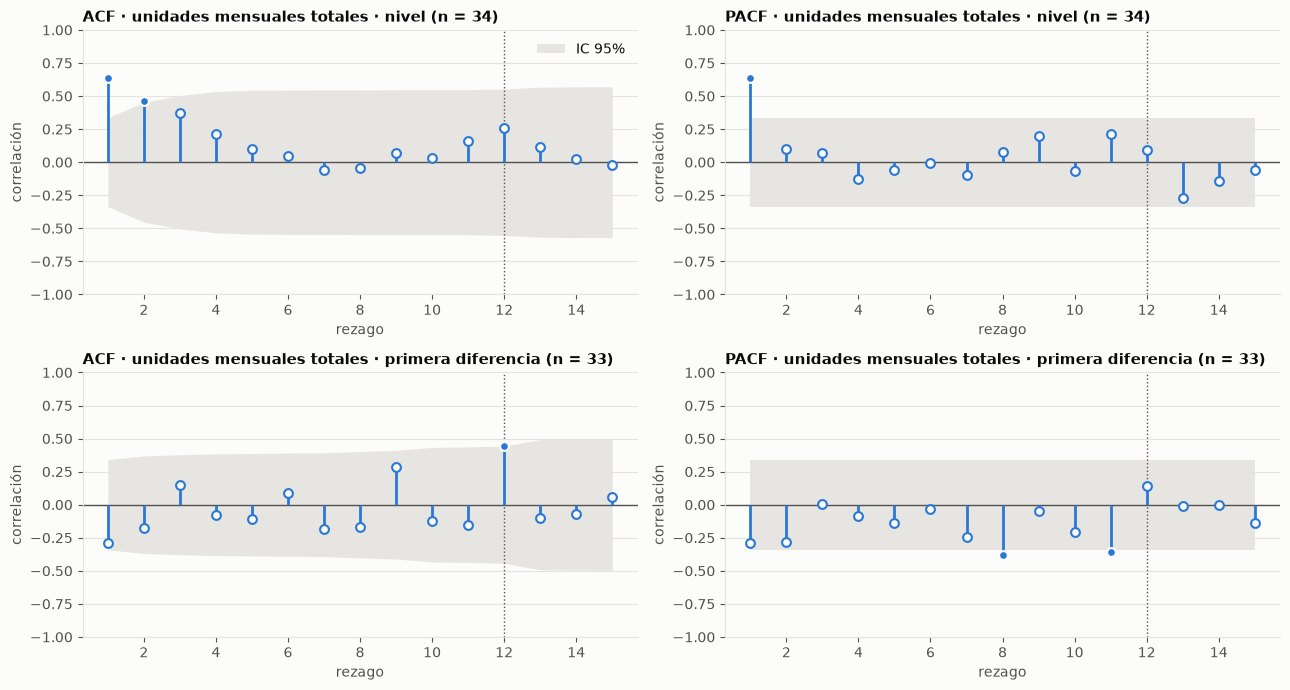

In [87]:
total_mensual = serie.set_index("date_block_num")["unidades"]
variantes = {
    "Nivel": total_mensual,
    "Primera diferencia": total_mensual.diff().dropna(),
}

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
resumen_total = {}
for fila, (nombre, s) in enumerate(variantes.items()):
    resultado = calcular_acf_pacf(s, REZAGOS_MES)
    for col, tipo in enumerate(["ACF", "PACF"]):
        valores, banda = resultado[tipo]
        dibujar_correlograma(axes[fila, col], valores, banda,
                             f"{tipo} · unidades mensuales totales · {nombre.lower()} (n = {len(s)})",
                             COLOR["unidades"], marcas=[12])
        resumen_total[(nombre, tipo)] = {
            "rezago 1": valores[1], "rezago 2": valores[2], "rezago 12": valores[12],
            "rezagos significativos": ", ".join(map(str, rezagos_significativos(valores, banda))) or "ninguno",
        }
axes[0, 0].legend(loc="upper right")
fig.tight_layout()
plt.show()

pd.DataFrame(resumen_total).T.style.format({"rezago 1": "{:+.2f}", "rezago 2": "{:+.2f}", "rezago 12": "{:+.2f}"})

**Interpretación:**
- **Nivel:** la ACF es alta en los primeros rezagos y decae lentamente (significativa en los rezagos 1 y 2). Es la huella típica de una serie con **tendencia**: los meses cercanos se parecen porque comparten el mismo nivel. La PACF solo es significativa en el **rezago 1**: una vez conocido el mes anterior, los rezagos intermedios apenas añaden información.
- **Primera diferencia:** al quitar la tendencia aparece una correlación positiva y significativa en el **rezago 12**, que es la señal **estacional anual** (el patrón de diciembre se repite). El rezago 1 es negativo (−0.29, no significativo): a un mes con subida le suele seguir una bajada, como el pico de diciembre seguido por enero. En la PACF de la diferencia aparecen significativos los rezagos 8 y 11, de forma aislada y sin un patrón coherente; con 15 rezagos evaluados, pueden deberse al azar.
- Con solo dos ciclos anuales, el rezago 12 debe leerse como **indicio** de estacionalidad coherente con la sección 6, no como prueba concluyente.

### 9.3 Ventas totales diarias

Serie de unidades netas por día (1,034 días). Las líneas punteadas marcan múltiplos de 7.

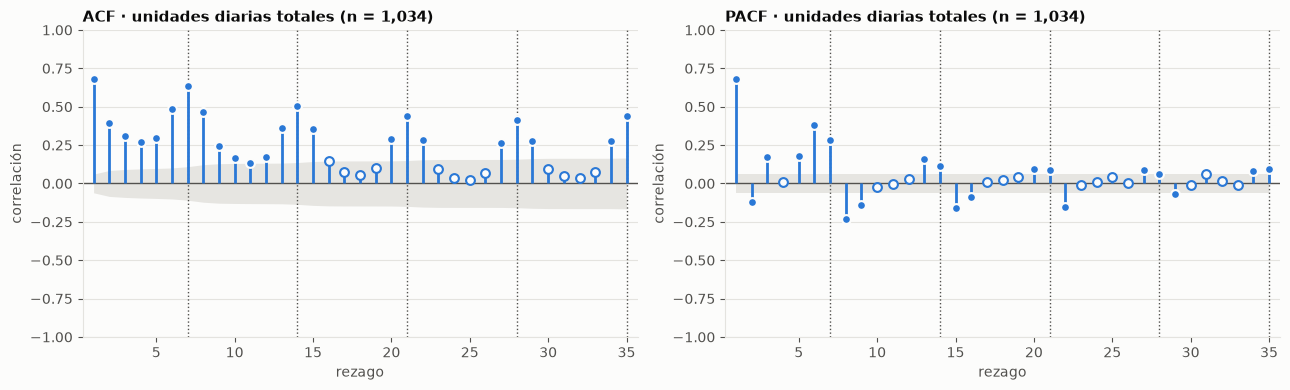

,rezago 1,rezago 6,rezago 7,rezago 8,rezago 14,rezago 21,rezago 28,rezago 35
ACF diaria,+0.68,+0.48,+0.64,+0.47,+0.51,+0.44,+0.41,+0.44


In [88]:
total_diario = por_dia["unidades"]
resultado_dia = calcular_acf_pacf(total_diario, REZAGOS_DIA)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, tipo in zip(axes, ["ACF", "PACF"]):
    valores, banda = resultado_dia[tipo]
    dibujar_correlograma(ax, valores, banda, f"{tipo} · unidades diarias totales (n = {len(total_diario):,})",
                         COLOR["unidades"], marcas=range(7, REZAGOS_DIA + 1, 7))
fig.tight_layout()
plt.show()

valores_acf_dia = resultado_dia["ACF"][0]
pd.Series(valores_acf_dia[[1, 6, 7, 8, 14, 21, 28, 35]], index=[f"rezago {k}" for k in [1, 6, 7, 8, 14, 21, 28, 35]],
          name="ACF diaria").to_frame().T.style.format("{:+.2f}")

**Interpretación:**
- La ACF diaria muestra **picos en los rezagos 7, 14, 21, 28 y 35**, por encima de los rezagos vecinos: es la firma del **ciclo semanal** (sábados altos y lunes bajos, sección 6.4.2). El pico decrece lentamente porque también influyen la tendencia y la estacionalidad anual.
- La PACF tiene valores significativos en los primeros rezagos y alrededor del 7. Esto indica que el día anterior y el mismo día de la semana anterior aportan información propia.
- Con n = 1,034, la banda de confianza es estrecha (±0.06): casi cualquier rezago resulta significativo, así que importa más la **forma** del correlograma que la significancia individual.
- Como el objetivo es mensual, el ciclo semanal se compensa al agregar (sección 3.5), pero confirma que el comportamiento diario es muy regular.

### 9.4 Selección representativa de series mensuales

Se eligen series con **historial completo** (34 meses) para que la ACF sea comparable:
- **Sucursales** (activas los 34 meses), de distinto tamaño y canal: la más grande (31), una mediana (22), una pequeña (2) y la tienda online (12).
- **Productos** (con ventas desde el mes 0) de familias distintas: un videojuego (2808, Diablo III PC), una tarjeta de pago (5822, PlayStation Store) y un consumible (22088, pilas). Se excluyen la bolsa de marca y los servicios (sección 7.5).
- **Pares sucursal–producto** en tiendas activas los 34 meses: uno con ventas todos los meses y otros con meses sin ventas, **rellenados con 0** porque la tienda estaba activa.

In [89]:
activa = matriz.notna()  # sucursal x mes: True si la tienda vendió algo ese mes (sección 8.2)
mensual_par = ventas.groupby(["shop_id", "item_id", "date_block_num"])["item_cnt_day"].sum()
mensual_producto = ventas.groupby(["item_id", "date_block_num"])["item_cnt_day"].sum()

def serie_tienda(shop_id):
    """Unidades por mes; NaN en meses sin actividad de la tienda."""
    return matriz.loc[shop_id].reindex(range(34))

def serie_producto(item_id):
    """Unidades por mes; 0 tras la primera venta si no vendió; NaN antes de su primera venta."""
    s = mensual_producto.loc[item_id].reindex(range(34))
    return s.fillna(0).where(np.arange(34) >= s.first_valid_index())

def serie_par(shop_id, item_id):
    """Unidades por mes; 0 si la tienda estaba activa y no vendió; NaN si la tienda estaba inactiva."""
    s = mensual_par.loc[(shop_id, item_id)].reindex(range(34))
    return s.fillna(0).where(activa.loc[shop_id].values)

SELECCION = {
    "Sucursales": {f"tienda {i}": serie_tienda(i) for i in [31, 22, 2, 12]},
    "Productos": {f"producto {i}": serie_producto(i) for i in [2808, 5822, 22088]},
    "Pares sucursal–producto": {f"tienda {s} · producto {i}": serie_par(s, i)
                                for s, i in [(31, 5822), (22, 482), (25, 2808)]},
}

filas = []
for grupo, series in SELECCION.items():
    for nombre, s in series.items():
        ids = [int(x) for x in nombre.replace("·", " ").split() if x.isdigit()]
        descripcion = nombre_tienda[ids[0]] if grupo == "Sucursales" else nombre_item[ids[-1]]
        filas.append({
            "grupo": grupo, "serie": nombre, "descripción": descripcion[:45],
            "meses con ventas": int((s > 0).sum() + (s < 0).sum()),
            "meses en 0 (rellenados)": int((s == 0).sum()),
            "meses sin actividad (NaN)": int(s.isna().sum()),
            "unidades totales": s.sum(),
        })
tabla_seleccion = pd.DataFrame(filas).set_index(["grupo", "serie"])
assert tabla_seleccion["meses sin actividad (NaN)"].eq(0).all(), "Las series seleccionadas deben ser continuas"
tabla_seleccion.style.format({"unidades totales": "{:,.0f}"})

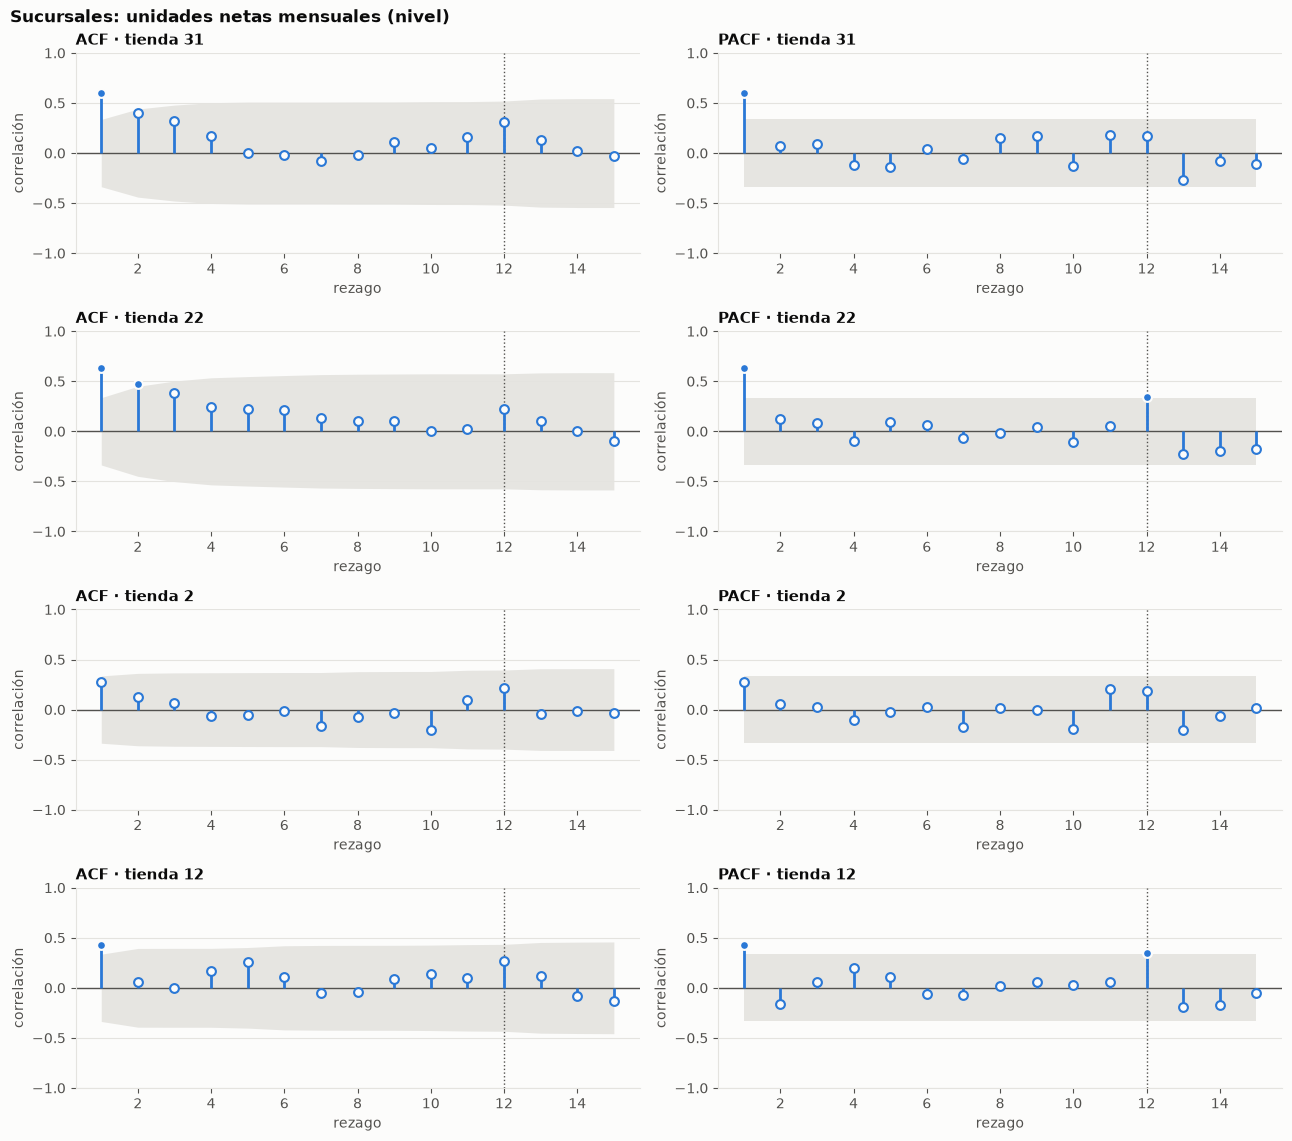

In [90]:
def panel_correlogramas(series, color, titulo_figura):
    fig, axes = plt.subplots(len(series), 2, figsize=(13, 2.9 * len(series)), squeeze=False)
    resumen = {}
    for fila, (nombre, s) in enumerate(series.items()):
        resultado = calcular_acf_pacf(s.values, REZAGOS_MES)
        for col, tipo in enumerate(["ACF", "PACF"]):
            valores, banda = resultado[tipo]
            dibujar_correlograma(axes[fila, col], valores, banda, f"{tipo} · {nombre}", color, marcas=[12])
            resumen[(nombre, tipo)] = {
                "rezago 1": valores[1], "rezago 12": valores[12],
                "rezagos significativos": ", ".join(map(str, rezagos_significativos(valores, banda))) or "ninguno",
            }
    fig.suptitle(titulo_figura, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    plt.show()
    return pd.DataFrame(resumen).T.style.format({"rezago 1": "{:+.2f}", "rezago 12": "{:+.2f}"})

panel_correlogramas(SELECCION["Sucursales"], COLOR["unidades"], "Sucursales: unidades netas mensuales (nivel)")

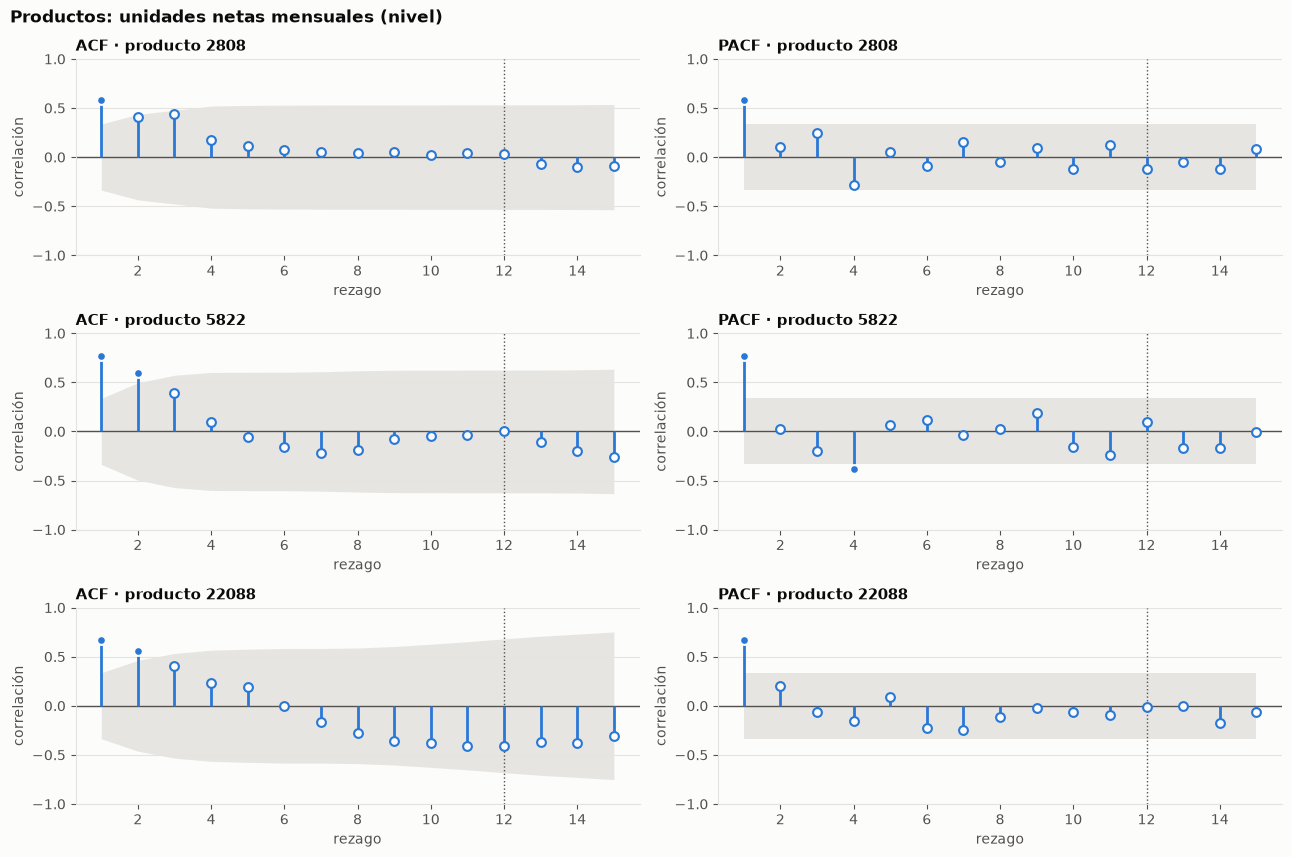

In [91]:
panel_correlogramas(SELECCION["Productos"], COLOR["unidades"], "Productos: unidades netas mensuales (nivel)")

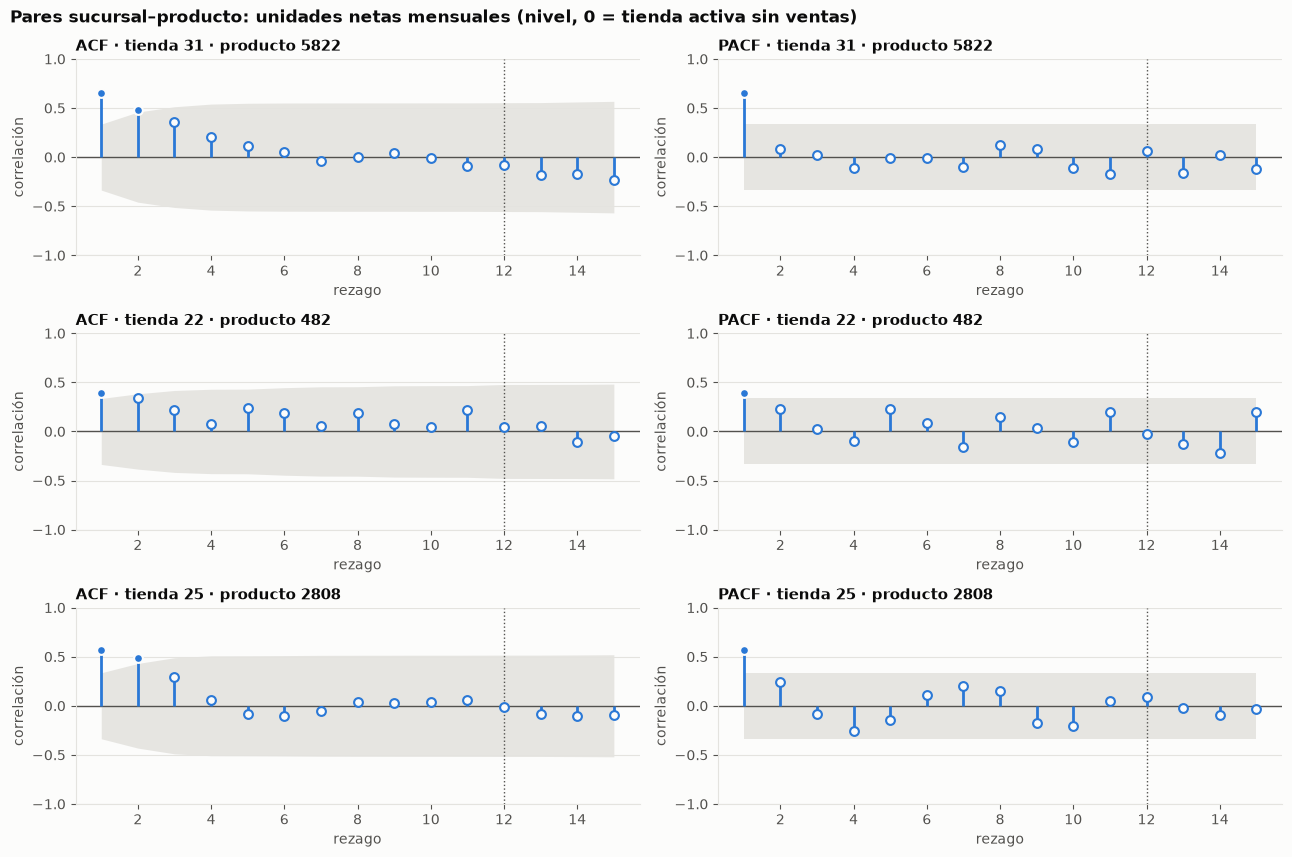

In [92]:
panel_correlogramas(SELECCION["Pares sucursal–producto"], COLOR["unidades"],
                    "Pares sucursal–producto: unidades netas mensuales (nivel, 0 = tienda activa sin ventas)")

### 9.5 ¿Se generalizan los patrones? Resumen sobre muchas series

Para no depender solo de los ejemplos, se calcula la ACF de **todas** las series con historial suficiente y se resume qué tan frecuente es cada patrón:
- **Sucursales:** las 32 activas los 34 meses.
- **Productos:** los que tienen ventas en el mes 0 y en al menos 24 de los 34 meses.
- **Pares sucursal–producto:** en tiendas activas los 34 meses, con ventas en al menos 24 meses (los meses restantes se rellenan con 0).

Se reporta la mediana de la ACF y el porcentaje de series en las que cada rezago es significativo, tanto en nivel como en primera diferencia.

In [93]:
tiendas_completas = por_tienda.index[por_tienda["meses_activa"] == 34]
meses_con_venta_prod = mensual_producto.groupby(level=0).size()
primer_mes_prod = mensual_producto.reset_index().groupby("item_id")["date_block_num"].min()
productos_ok = meses_con_venta_prod.index[(meses_con_venta_prod >= 24) & (primer_mes_prod == 0)]
productos_ok = productos_ok.difference(list(NATURALEZA))  # sin bolsa ni servicios
meses_con_venta_par = mensual_par.groupby(level=[0, 1]).size()
pares_ok = [p for p in meses_con_venta_par.index[meses_con_venta_par >= 24]
            if p[0] in tiendas_completas and p[1] not in NATURALEZA]

grupos_resumen = {
    "Sucursales": [serie_tienda(i) for i in tiendas_completas],
    "Productos": [serie_producto(i) for i in productos_ok],
    "Pares sucursal–producto": [serie_par(s, i) for s, i in pares_ok],
}

def resumen_acf(lista_series, diferenciar):
    regs = []
    for s in lista_series:
        x = s.diff().dropna().values if diferenciar else s.values
        if np.std(x) == 0:
            continue
        valores, ic = acf(x, nlags=REZAGOS_MES, alpha=0.05, result_object=False)
        banda = ic[:, 1] - valores
        regs.append({k: (valores[k], abs(valores[k]) > banda[k]) for k in (1, 2, 3, 12)})
    fila = {"series": len(regs)}
    for k in (1, 2, 3, 12):
        fila[f"mediana ACF r{k}"] = np.median([r[k][0] for r in regs])
        fila[f"% signif. r{k}"] = np.mean([r[k][1] for r in regs])
    return fila

resumen_general = pd.DataFrame(
    {(grupo, "diferencia" if dif else "nivel"): resumen_acf(lista, dif)
     for grupo, lista in grupos_resumen.items() for dif in (False, True)}
).T
formato_resumen = {c: "{:+.2f}" for c in resumen_general.columns if c.startswith("mediana")}
formato_resumen.update({c: "{:.0%}" for c in resumen_general.columns if c.startswith("%")})
formato_resumen["series"] = "{:,.0f}"
resumen_general.style.format(formato_resumen)

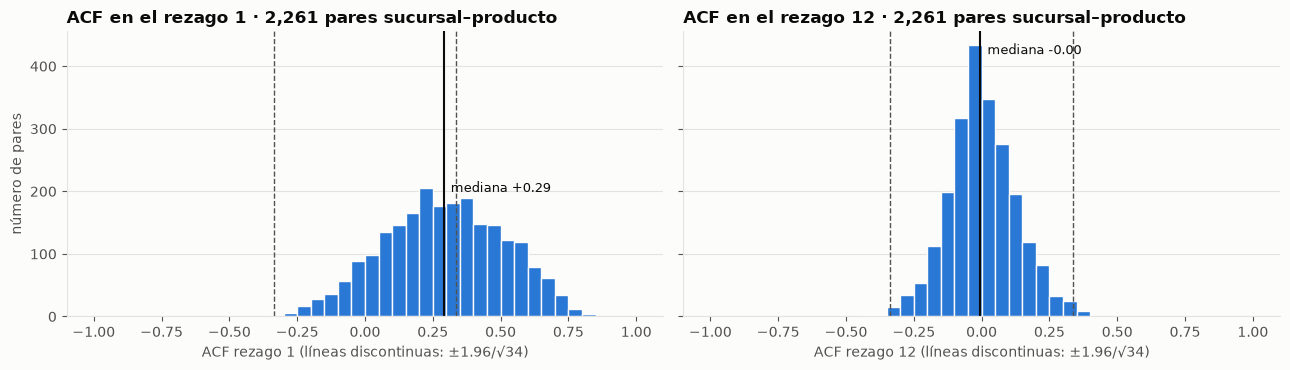

In [94]:
# Distribución de la ACF en los rezagos 1 y 12 para los pares sucursal–producto (nivel)
acf_pares = np.array([acf(s.values, nlags=REZAGOS_MES, result_object=False)[[1, 12]] for s in grupos_resumen["Pares sucursal–producto"]
                      if np.std(s.values) > 0])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (indice, rezago) in zip(axes, enumerate([1, 12])):
    ax.hist(acf_pares[:, indice], bins=np.linspace(-1, 1, 41), color=COLOR["unidades"], edgecolor=FONDO, linewidth=1)
    for limite in (-1.96 / np.sqrt(34), 1.96 / np.sqrt(34)):
        ax.axvline(limite, color=TINTA_2, linestyle="--", linewidth=1)
    ax.axvline(np.median(acf_pares[:, indice]), color=TINTA, linewidth=1.5)
    ax.annotate(f"mediana {np.median(acf_pares[:, indice]):+.2f}", (np.median(acf_pares[:, indice]), ax.get_ylim()[1] * 0.92),
                xytext=(5, 0), textcoords="offset points", fontsize=9, color=TINTA)
    ax.set_title(f"ACF en el rezago {rezago} · {len(acf_pares):,} pares sucursal–producto")
    ax.set_xlabel(f"ACF rezago {rezago} (líneas discontinuas: ±1.96/√34)")
axes[0].set_ylabel("número de pares")
fig.tight_layout()
plt.show()

**Interpretación (9.4 y 9.5):**

| Nivel de agregación | Persistencia (rezago 1) | Estacionalidad anual (rezago 12) |
|---|---|---|
| **Total** | Fuerte (+0.64). | Visible al diferenciar (+0.45, significativa). |
| **Sucursales** | Fuerte: mediana +0.62, significativa en el 88% de las tiendas. Más débil en tiendas pequeñas y ruidosas (tienda 2). | En nivel casi no aparece (6%); **al diferenciar**, la mediana sube a +0.40 y es significativa en el 28% de las tiendas. |
| **Productos** | Fuerte: mediana +0.54, significativa en el 78%. | **No aparece** (mediana ≈ 0; 0% significativa). |
| **Pares sucursal–producto** | Moderada: mediana +0.29, significativa solo en el 43%. | **No aparece** (mediana ≈ 0; 0% significativa). |

- **Persistencia:** en todos los niveles, las ventas de un mes se asocian positivamente con las del mes anterior. La PACF suele ser significativa **solo en el rezago 1**: el mes inmediatamente anterior concentra casi toda la información de corto plazo, y los rezagos 2–3 de la ACF son en gran parte su eco.
- **Estacionalidad que depende de la agregación:** el patrón anual (diciembre) se detecta en el total y en las sucursales, donde se suman muchos productos. A nivel de **producto** y de **par sucursal–producto** no aparece. En esos niveles domina el **ciclo de vida** del producto (ventas altas al principio y luego en descenso): por ejemplo, las pilas (22088) muestran una ACF **negativa** en el rezago 12 (−0.40), que refleja esa caída y no una estacionalidad inversa.
- **Ruido a nivel fino:** en los pares, la primera diferencia tiene un rezago 1 claramente negativo (mediana −0.40, significativo en el 66%). Indica que gran parte de la variación mes a mes es **ruido que se revierte**: un mes alto suele ir seguido de uno más bajo.
- **Meses rellenados con 0:** en los pares seleccionados casi no hay ceros (por ejemplo, 2 en la tienda 25 · producto 2808), porque se exigió historial suficiente. En el resto del catálogo los ceros son mayoría y la autocorrelación sería todavía más débil.

**Implicaciones para la modelación (sin atribuir causalidad):**
- Los **rezagos recientes** (1 y, en menor medida, 2–3 meses) de las ventas de la misma sucursal, el mismo producto o el mismo par son candidatos naturales como variables predictoras.
- El **rezago 12** puede aportar como variable a nivel agregado (sucursal o total), pero con solo dos ciclos anuales su evidencia es limitada, y a nivel de par sucursal–producto no muestra relación.
- La estacionalidad de diciembre conviene representarla con variables de calendario (mes del año) más que con el rezago 12 de cada par.
- Estas conclusiones se basan en series con historial completo; los productos nuevos o con poca historia no pueden evaluarse con ACF/PACF.

## 10. Insights y conclusiones del EDA

Objetivo de esta sección: sintetizar los hallazgos de las secciones 2 a 9, medir cuánta historia existe para los pares que hay que predecir y evaluar si el dataset está listo para modelar.

### 10.1 Factores y variables asociados con las ventas

| Factor | Evidencia | Sección |
|---|---|---|
| **Tiempo: tendencia** | Las unidades caen de forma sostenida (≈ −1.8% del promedio mensual por mes). En 2015, las caídas interanuales van de −19% a −36% (salvo enero, −5%). | 5.10, 6.3 |
| **Tiempo: estacionalidad anual** | Diciembre vende ≈ 58% más que la tendencia; noviembre ≈ 10% más; abril–julio, entre un 12% y un 15% menos. | 6.4.1 |
| **Tiempo: ciclo semanal** | Sábado +41% y lunes −23% frente al promedio diario. Es estable en los tres años, pero se compensa al agregar por mes. | 6.4.2, 9.3 |
| **Historia reciente** | La ACF del rezago 1 es significativa en el 88% de las sucursales y el 78% de los productos; la PACF se concentra en el rezago 1. | 9.4, 9.5 |
| **Producto: concentración** | El 1% de los productos acumula el 28% de las unidades y el 45% del ingreso; hay una cola larga de productos con 1 unidad. | 5.4, 7.1 |
| **Producto: ciclo de vida y lanzamientos** | Los picos diarios más altos coinciden con lanzamientos (GTA V, PS4, The Witcher 3); a nivel de producto domina el ciclo de vida, no la estacionalidad. | 6.5, 9.5 |
| **Categoría** | En volumen dominan DVD, juegos de PC y CD de música; en ingreso, juegos de consola y consolas. El precio medio por familia difiere en más de 40 veces. | 5.5, 7.2 |
| **Sucursal** | Hay mucha heterogeneidad (de 330 a 9,140 unidades por mes activo). Las tiendas insignia de Moscú lideran; los canales online (12, 55) crecen mientras las tiendas físicas caen. | 5.6, 7.3, 8.2 |
| **Ciclo de vida de la tienda** | Solo 32 de 60 tiendas venden los 34 meses; hay 15 que cerraron, 9 que abrieron después y 4 intermitentes. | 7.3, 8.2 |
| **Precio** | El precio medio por unidad sube ≈ 50% sobre 2013 en la tendencia, mientras las unidades bajan un tercio. Hay promociones de precio simbólico cada verano. | 6.3, 7.5 |
| **Eventos** | Festivos (23 de febrero, 8 de marzo, Año Nuevo) y ferias de octubre (tiendas 9 y 20) generan picos puntuales. | 6.5.2 |

### 10.2 Patrones útiles para un modelo de forecasting

1. **Unidad de modelado:** mes × tienda × producto, con objetivo `item_cnt_month` = suma neta mensual de `item_cnt_day`, recortada a [0, 20]. La matriz es muy dispersa: solo el 3.6% de las combinaciones tiene ventas (sección 3.5).
2. **Rezagos de la variable objetivo:** 1, 2 y 3 meses del mismo par, producto y tienda. El rezago 1 es el más informativo (sección 9).
3. **Calendario:** mes del año (para capturar diciembre y noviembre) y, opcionalmente, número de días y de fines de semana del mes. El rezago 12 solo aporta a nivel agregado.
4. **Tendencia:** dar más peso a los meses recientes o incluir variables de nivel reciente; el nivel de 2013 no es representativo de noviembre de 2015.
5. **Codificación por grupos (target encoding):** promedios históricos por tienda, producto, categoría y familia, calculados solo con meses anteriores para evitar fuga de información.
6. **Antigüedad del producto:** meses desde la primera venta (los lanzamientos concentran la demanda en sus primeros meses) y meses desde la última venta.
7. **Precio:** precio relativo frente a la mediana del producto, marcando las promociones, en lugar del precio bruto.
8. **Indicadores de canal y tipo:** tienda online o digital (12, 55) y productos de servicio o empaque (11373, 17717, 20949).

### 10.3 Cobertura de los pares de `test.csv` en el historial

Se clasifica cada par `(shop_id, item_id)` de `test` según la historia disponible en `sales_train`:
- **Par con historial:** ese producto se vendió alguna vez en esa tienda.
- **Producto conocido, par nuevo:** el producto se vendió en otras tiendas, pero nunca en esta.
- **Producto nuevo:** el producto no tiene ninguna venta en `sales_train`.

In [95]:
pares_train = set(zip(sales_train["shop_id"], sales_train["item_id"]))
productos_train = set(sales_train["item_id"])

cobertura = test.copy()
cobertura["par_con_historial"] = [p in pares_train for p in zip(cobertura["shop_id"], cobertura["item_id"])]
cobertura["producto_conocido"] = cobertura["item_id"].isin(productos_train)
cobertura["grupo"] = np.select(
    [cobertura["par_con_historial"], cobertura["producto_conocido"]],
    ["par con historial", "producto conocido, par nuevo"],
    default="producto nuevo",
)

resumen_cobertura = (
    cobertura.groupby("grupo")
    .agg(pares=("ID", "size"), productos=("item_id", "nunique"), tiendas=("shop_id", "nunique"))
    .reindex(["par con historial", "producto conocido, par nuevo", "producto nuevo"])
)
resumen_cobertura["% de pares"] = resumen_cobertura["pares"] / len(cobertura)
resumen_cobertura.loc["total test"] = [len(cobertura), cobertura["item_id"].nunique(),
                                         cobertura["shop_id"].nunique(), 1.0]

con = cobertura["par_con_historial"].sum()
print(f"Pares en test: {len(cobertura):,} "
      f"({cobertura['shop_id'].nunique()} tiendas × {cobertura['item_id'].nunique():,} productos = "
      f"{cobertura['shop_id'].nunique() * cobertura['item_id'].nunique():,}: es la malla completa)")
print(f"Con historial: {con:,} ({con / len(cobertura):.1%}) | Sin historial: {len(cobertura) - con:,} "
      f"({1 - con / len(cobertura):.1%})")
resumen_cobertura.style.format({"pares": "{:,.0f}", "productos": "{:,.0f}", "tiendas": "{:,.0f}", "% de pares": "{:.1%}"})

Pares en test: 214,200 (42 tiendas × 5,100 productos = 214,200: es la malla completa)
Con historial: 111,404 (52.0%) | Sin historial: 102,796 (48.0%)


,pares,productos,tiendas,% de pares
grupo,,,,
par con historial,"111,404","4,716",42,52.0%
"producto conocido, par nuevo","87,550","4,737",42,40.9%
producto nuevo,"15,246",363,42,7.1%
total test,"214,200","5,100",42,100.0%


In [96]:
# Profundidad del historial: ¿cuándo se vendió por última vez el par?
ultimo_mes_par = sales_train.groupby(["shop_id", "item_id"])["date_block_num"].max()
cobertura["ultimo_mes"] = [ultimo_mes_par.get(p, np.nan) for p in zip(cobertura["shop_id"], cobertura["item_id"])]
recencia = pd.Series({
    "vendido en el mes 33 (oct-2015)": (cobertura["ultimo_mes"] == 33).sum(),
    "última venta en meses 28–32": cobertura["ultimo_mes"].between(28, 32).sum(),
    "última venta antes del mes 28": (cobertura["ultimo_mes"] < 28).sum(),
    "sin historial": cobertura["ultimo_mes"].isna().sum(),
}).to_frame("pares")
recencia["% de pares"] = recencia["pares"] / len(cobertura)
recencia.style.format({"pares": "{:,.0f}", "% de pares": "{:.1%}"})

,pares,% de pares
vendido en el mes 33 (oct-2015),"28,680",13.4%
última venta en meses 28–32,"45,813",21.4%
última venta antes del mes 28,"36,911",17.2%
sin historial,"102,796",48.0%


In [97]:
# Comprobaciones adicionales
productos_nuevos = set(cobertura.loc[cobertura["grupo"] == "producto nuevo", "item_id"])
nunca_vendidos = set(items["item_id"]) - productos_train
print(f"Productos nuevos en test: {len(productos_nuevos)} | "
      f"¿son los productos del catálogo nunca vendidos (sección 7.1)? {productos_nuevos == nunca_vendidos}")
print(f"Tiendas de test sin historial: {len(set(test['shop_id']) - set(sales_train['shop_id']))}")
print(f"Servicios/empaque en test (11373, 17717, 20949): "
      f"{cobertura['item_id'].isin(list(NATURALEZA)).sum()} pares")

# Efecto de unificar las tiendas duplicadas (0→57, 1→58, 11→10; propuesto en 4.5)
UNIFICAR = {0: 57, 1: 58, 11: 10}
pares_unificados = set(zip(sales_train["shop_id"].replace(UNIFICAR), sales_train["item_id"]))
con_unif = sum(p in pares_unificados for p in zip(cobertura["shop_id"], cobertura["item_id"]))
print(f"Pares con historial si se unifican las tiendas: {con_unif:,} ({con_unif / len(cobertura):.1%}), "
      f"+{con_unif - con:,} pares")

Productos nuevos en test: 363 | ¿son los productos del catálogo nunca vendidos (sección 7.1)? True


Tiendas de test sin historial: 0
Servicios/empaque en test (11373, 17717, 20949): 126 pares


Pares con historial si se unifican las tiendas: 111,471 (52.0%), +67 pares


**Interpretación:**
- `test` es la **malla completa** de 42 tiendas × 5,100 productos (214,200 pares): incluye a propósito combinaciones que nunca se vendieron.
- **52.0% de los pares (111,404) tiene historial** tienda–producto y **48.0% (102,796) no lo tiene**. De estos últimos:
  - **87,550 pares (40.9%)** son de productos conocidos que nunca se vendieron en esa tienda: se puede usar la historia del producto en otras tiendas y la de su categoría.
  - **15,246 pares (7.1%)** corresponden a **363 productos nuevos**, que son exactamente los 363 productos del catálogo sin ninguna venta (sección 7.1). Para ellos solo hay información de categoría, nombre y tienda.
- **La historia también es poco reciente:** solo el **13.4%** de los pares vendió en octubre de 2015 y el 21.4% más tuvo su última venta entre mayo y septiembre de 2015. Para el resto, la historia es antigua o inexistente, lo que sugiere que muchos tendrán ventas de 0.
- Todas las tiendas de `test` tienen historial. **Unificar las tiendas duplicadas** apenas cambia la cobertura (+67 pares), porque las tiendas 0 y 1 solo vendieron dos meses; aun así, conviene hacerlo por consistencia.
- **Implicación:** entrenar sobre una malla mensual completa (como `test`, con ceros incluidos) es imprescindible para que el modelo aprenda a predecir los muchos pares sin ventas.

### 10.4 Calidad del dataset y preparación para el modelado

| Aspecto | Estado | Pendiente para la limpieza |
|---|---|---|
| Valores nulos | ✅ Ninguno en los cinco archivos. | — |
| Tipos y fechas | ✅ `date` convertible sin errores; `date_block_num` coherente al 100%; calendario sin huecos. | Convertir `date` al cargar. |
| Duplicados exactos | ⚠️ 6 filas. | Eliminar las copias. |
| Precio inválido | ⚠️ 1 registro con −1 (imputado solo en la copia de trabajo). | Aplicar la imputación en el pipeline. |
| Devoluciones | ✅ 7,356 registros (0.25%), transacciones válidas. | Conservar; agregar en neto. |
| Tiendas duplicadas | ⚠️ 0/57, 1/58 y 10/11 son la misma tienda; 39/40, dudoso. | Unificar 0→57, 1→58 y 11→10; mantener 39 y 40 separadas. |
| Servicios y empaque | ⚠️ El envío (11373) y los cobros (17717) no son demanda de producto, pero están en `test`. | Marcarlos con una variable; no eliminarlos. |
| Valores extremos | ✅ Casi todos legítimos (lanzamientos, ventas corporativas, eventos, canal online). | Recortar el objetivo a [0, 20]; no eliminar registros. |
| Precios promocionales | ⚠️ Precios simbólicos cada verano (0.10, 0.50, 0.99). | Usar precio relativo o marcar promociones. |
| Tiendas no permanentes | ⚠️ 15 cerradas, 4 intermitentes (9 y 20 son ferias temporales). | Usar su historia para patrones generales; no son objetivo de predicción. |
| Dispersión y cobertura | ⚠️ Solo el 3.6% de las combinaciones mes–tienda–producto tiene ventas; casi la mitad de los pares de `test` no tiene historial. | Construir la malla completa de tienda × producto por mes, rellenando con 0, para entrenar con el mismo formato que `test`. |
| Profundidad temporal | ⚠️ 34 meses: menos de tres ciclos anuales. | Validar con los últimos meses (por ejemplo, mes 33) como conjunto de validación. |

**Valoración:** el dataset es **consistente y de buena calidad estructural**: no tiene nulos, las fechas son coherentes y los problemas son puntuales y están identificados. Ninguno impide modelar. Los retos principales no son de limpieza, sino de **dispersión** (muchos ceros), **cobertura** (pares y productos sin historia) y **no estacionariedad** (tendencia descendente y cambios en la mezcla de tiendas y productos). El dataset estará listo para modelar después de aplicar las limpiezas de la tabla y construir la malla mensual.

### 10.5 Conclusiones

1. **Los datos son fiables.** No hay nulos, las fechas y `date_block_num` son coherentes, y los errores encontrados (6 duplicados, 1 precio negativo y 3 pares de tiendas duplicadas) son pocos y fáciles de corregir.
2. **La demanda cae y se transforma.** Las unidades bajan ≈ 1.8% al mes y un tercio en la tendencia del periodo, mientras el precio medio sube ≈ 50%, y los canales online crecen frente a las tiendas físicas.
3. **El calendario importa.** Diciembre es el pico anual (≈ +58%) y noviembre, el mes a predecir, está por encima de la tendencia; el ciclo semanal es fuerte en datos diarios, pero se diluye al agregar por mes.
4. **El pasado reciente es el mejor indicador.** Las ventas del mes anterior son el predictor temporal más consistente en todos los niveles; la estacionalidad solo es visible a nivel agregado.
5. **Las ventas están muy concentradas.** Pocos productos y tiendas explican gran parte del volumen, mientras la mayoría de las combinaciones tienda–producto tiene ventas nulas o muy esporádicas.
6. **Los extremos son, en su mayoría, negocio real.** Lanzamientos, eventos, ventas corporativas y promociones explican los valores atípicos: deben conservarse, con el objetivo recortado a [0, 20].
7. **El mayor reto es la cobertura.** Casi la mitad de los pares de `test` no tiene historial tienda–producto, y un 7% corresponde a productos nunca vendidos. El modelo deberá apoyarse en información de producto, categoría y tienda, y no solo en la historia de cada par.
8. **Siguiente paso:** aplicar las limpiezas pendientes, construir la malla mensual tienda × producto con el objetivo recortado, generar las variables de rezago, calendario, antigüedad y codificación por grupos, y validar con los meses más recientes.